# Lab 03 — Bản tích hợp — Sentiment Analysis & Fine-tuning

**Môn học:** Deep Learning — UTH. **Bài toán:** phân tích cảm xúc và phân loại văn bản nhị phân với Hugging Face.

Notebook có hai chế độ. **`MODE="view"`** đọc kết quả Kaggle đã xác minh và tạo hoặc dùng lại run phân tích chứa hình/bảng; không tải dataset/model và không train. **`MODE="train"`** gọi cùng module với CLI để thực thi thí nghiệm mới. Output đã lưu trong notebook là một lượt chạy `view`, không phải một lần GPU training mới.

Mỗi trực quan hóa hiển thị bên dưới được đọc từ file ảnh trong `outputs/`; bảng có bản JSON nguồn tương ứng. Artifacts thí nghiệm cũ không bị ghi đè. Các bảng JSON phục vụ tái tính toán và kiểm tra, còn hình phục vụ diễn giải bài. Cài môi trường theo [README](../README.md) trước khi chạy và xem [description](../description_lab_03.md) cho các quyết định phạm vi.

**Cách đọc số liệu:** các số trong phần giải thích là kết quả Kaggle tham chiếu có run ID cụ thể. Khi `MODE="train"`, bảng và hình được tính từ run mới; không gán số tham chiếu cho kết quả vừa chạy.

Phiên dữ liệu hiện hành: `20261026T155822Z_finetuning_2c2f0401`, dataset revision `aa13bc287fa6fcab6daf52f0dfb9994269ffea28`. Hình/bảng dùng cho report được xuất từ các run chọn tường minh ở `config/report.json` sang `outputs/published/`.

**Lần chạy mới:** notebook này giữ output lịch sử 3 epoch để đối chiếu. Dùng [04_kaggle_10epoch_study.ipynb](04_kaggle_10epoch_study.ipynb) cho quy trình mới: mỗi candidate đủ 10 epoch, validation selection và ZIP. Các số liệu bên dưới thuộc run lịch sử, không phải kết quả 10 epoch.

**Kết quả 10 epoch đã kiểm chứng:** [05_study_results_and_discussion.ipynb](05_study_results_and_discussion.ipynb) trình bày study mới, Accuracy 83,40%, best checkpoint tại epoch 3,184. Các phần lịch sử dưới đây vẫn giữ nguồn 3 epoch; không đổi nhãn thành kết quả mới.

## Roadmap — Exercise 1

| Phase | Câu hỏi cần trả lời | Module / file tham chiếu | Đầu vào | Artifact / bằng chứng đầu ra |
|---|---|---|---|---|
| P01 — Setup | Đang xem bằng chứng hay chạy inference mới? | [workflow.py](../src/workflow.py), [config.json](../config/config.json) | Config và registry | Run ID, config, snapshot môi trường |
| P02 — Pretrained model | Model nào đã biết sentiment? | [classifier.py](../src/models/classifier.py): `load_model` | DistilBERT fine-tuned SST-2 | Model/tokenizer dùng chung cho hai cách suy luận |
| P03 — Tokenization | Câu được mã hóa như thế nào? | [workflow.py](../src/workflow.py): `exercise1` | Câu văn bản mẫu | `tokenizer_breakdown.json`, `tokenizer_table.png` |
| P04 — Forward | Logits khác xác suất ở đâu? | [classifier.py](../src/models/classifier.py): `manual_predict` | `input_ids`, `attention_mask` | `predictions.json`, `sentiment_predictions.png` |
| P05 — Đối chiếu API | Pipeline có khớp manual không? | [classifier.py](../src/models/classifier.py): `compare_inference` | Cùng model, tokenizer, câu mẫu | `pipeline_manual_comparison.png`, `summary.json` |
| P06 — Audit & bàn giao | Output có còn nguyên và tái đọc được? | [evidence.py](../src/evidence.py), [analysis.py](../src/analysis.py), [runs.py](../src/utils/runs.py) | Predictions và manifest | Audit, SHA256, run phân tích riêng trong `outputs/runs/` |

Sơ đồ luồng: **text → tokenizer → model forward → logits → softmax → argmax → label/score**. Exercise 1 không dùng optimizer và không cập nhật trọng số.

## Roadmap — Exercise 2

| Phase | Mục tiêu / quyết định | Module / file tham chiếu | Đầu vào | Artifact / trực quan hóa |
|---|---|---|---|---|
| P01 — Data contract | Dùng đủ official train/validation/test | [loader.py](../src/datasets/loader.py): `load_data` | Rotten Tomatoes | Split sizes và `class_distribution.png` |
| P02 — EDA | Hiểu độ dài và phân bố nhãn trước khi diễn giải | [workflow.py](../src/workflow.py), [analysis.py](../src/analysis.py) | Dataset hoặc predictions đã lưu | `data_statistics.json`, `review_length_distribution.png` |
| P03 — Encoding | Truncation 128, padding theo batch | [loader.py](../src/datasets/loader.py): `tokenize_data` | Text, tokenizer | Tokenized datasets; `token_length_distribution.png` |
| P04 — Model | Backbone pretrained + đầu phân loại hai lớp | [classifier.py](../src/models/classifier.py): `load_model` | DistilBERT nền | Logits `(B,2)`, config và provenance |
| P05 — Sanity | Forward/loss/gradient có học được? | [trainer.py](../src/training/trainer.py), [test_training.py](../tests/test_training.py) | Batch nhỏ và model disposable | Kết quả test; không đổi model train chính |
| P06 — Optimization | Train ba epochs; chọn checkpoint bằng validation | [trainer.py](../src/training/trainer.py): `make_trainer` | Train/validation | `trainer_history.json`, `learning_curves.png` |
| P07 — Threshold | Chọn ngưỡng bằng validation rồi đóng băng | [thresholds.py](../src/training/thresholds.py) | Validation probabilities | `validation_threshold/threshold_curves.png`, `decision_threshold.json`, validation comparison |
| P08 — Test | Đánh giá một lần sau lựa chọn | [workflow.py](../src/workflow.py): `evaluate_model`, [metrics.py](../src/training/metrics.py) | Checkpoint/ngưỡng cố định, test | Metrics, confusion matrix, toàn bộ predictions |
| P09 — Curves | Phân biệt ranking, threshold và calibration | [analysis.py](../src/analysis.py) | Test probabilities đã lưu | ROC/PR, reliability và histogram xác suất |
| P10 — Error analysis | Đọc câu sai, confidence và loại lỗi | [analysis.py](../src/analysis.py), [workflow.py](../src/workflow.py): `choose_samples` | Predictions + nhãn thật | `sample_predictions.png`, bảng metric theo lớp |
| P11 — Save/load | Kiểm tra checkpoint và truy vết artifact | [classifier.py](../src/models/classifier.py): `verify_saved_model`, [runs.py](../src/utils/runs.py) | Model đã train | `best_model/`, `reload_check.json`, SHA256 manifest |
| P12 — Report | Kết luận đúng phạm vi bằng chứng | [walkthrough](../walkthrough_lab_03.md), [description](../description_lab_03.md) | Tất cả artifacts | Bảng quyết định, giới hạn và báo cáo thống nhất |

**Điểm tách bắt buộc:** train cập nhật trọng số; validation chọn checkpoint/ngưỡng; test đo chất lượng cuối. Việc vẽ đường cong trên test trong phần chẩn đoán không cho phép quay lại chọn ngưỡng tốt nhất từ test.

| Phase bổ sung | Module / file tham chiếu | Artifact đã lưu |
|---|---|---|
| Kiểm toán policy và provenance | [threshold_evidence.py](../src/threshold_evidence.py), [decision.py](../src/decision.py) | `threshold_audit.json`, checkpoint SHA256 và validation fingerprint |
| So sánh validation/test/inference | [threshold_analysis.py](../src/threshold_analysis.py) | `tables.json`, `test_comparison.png`, `confusion_comparison.png`, `changed_predictions.png` |
| Lưu toàn bộ cell output | [render_notebooks.py](../scripts/render_notebooks.py) | Run `notebook_render` chứa bản notebook đã thực thi |


| Phase report | Module/file tham chiếu | Đầu ra |
|---|---|---|
| Chốt bộ artifact | [report.json](../config/report.json), [publish_artifacts.py](../scripts/publish_artifacts.py) | [Bảng/hình report](../outputs/published/index.md) |


In [1]:
from pathlib import Path
import sys
import json

LAB = next((p / "labs/lab03" if (p / "labs/lab03/src/workflow.py").is_file() else p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "labs/lab03/src/workflow.py").is_file() or (p / "src/workflow.py").is_file()), None)
if LAB is None:
    raise RuntimeError("Open this notebook inside the Lab-DL repository")
sys.path.insert(0, str(LAB.parents[1]))

import pandas as pd
from IPython.display import display, Image, Markdown
from labs.lab03.src.workflow import read_config, exercise1, finetune
from labs.lab03.src.evidence import selected_run, audit_exercise1, audit_finetuning, read_json
from labs.lab03.src.analysis import ensure_analysis, ensure_exercise1_analysis

# view: xem kết quả có sẵn; chỉ tạo/cache artifacts phân tích, không tải model hay train.
# train: tạo thí nghiệm mới; fine-tuning mặc định cần GPU CUDA.
MODE = "view"
assert MODE in {"view", "train"}
config = read_config()

def show_figure(path, caption):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Missing saved visualization: {path}")
    display(Markdown(f"**{caption}**"))
    display(Image(filename=str(path)))

print("Chế độ:", MODE)
print("Nguồn bài:", LAB)
print("Hình và bảng được đọc từ artifacts đã lưu trong outputs/.")
from labs.lab03.src.threshold_analysis import ensure_threshold_analysis

Chế độ: view
Nguồn bài: /workspace/Lab-DL-completion/labs/lab03
Hình và bảng được đọc từ artifacts đã lưu trong outputs/.


## 1.1. Mô hình được sử dụng và lý do lựa chọn

`distilbert/distilbert-base-uncased-finetuned-sst-2-english` đã được fine-tune cho sentiment nhị phân trên SST-2. Model này phù hợp để thực hành inference ngay, khác backbone nền ở Exercise 2. Tên lớp 0/1 được model ánh xạ sang `NEGATIVE`/`POSITIVE`.

`pipeline("sentiment-analysis")` là API cấp cao; nó không phải một thuật toán khác với forward thủ công. Hai cách phải dùng cùng checkpoint, cùng tokenizer và cùng thiết lập truncation để đối chiếu có ý nghĩa. Ba câu mẫu kiểm tra API chỉ là ví dụ minh họa, không phải test set để báo cáo accuracy tổng quát.

In [2]:
exercise1_run = exercise1(config) if MODE == "train" else selected_run("exercise1")
exercise1_audit = audit_exercise1(exercise1_run)
exercise1_analysis = ensure_exercise1_analysis(exercise1_run)
ex1_summary = read_json(exercise1_analysis / "summary.json")
print("Run inference:", exercise1_run.name)
print("Run phân tích đã lưu:", exercise1_analysis)
print("Tệp gốc khớp SHA256:", exercise1_audit["verified_files"])

Run inference: 20261026T155744Z_exercise1_65dfe784
Run phân tích đã lưu: /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261026T192053Z_exercise1_analysis_4323ef53
Tệp gốc khớp SHA256: 5


## 1.2. Tokenization — từ văn bản sang tensor

WordPiece có thể biểu diễn một từ bằng nhiều subword; token không nhất thiết trùng một từ. Tokenizer thêm `[CLS]` ở đầu và `[SEP]` ở cuối. `input_ids` là các ID vocabulary, không phải giá trị sentiment. `attention_mask` bằng 1 tại token thực và bằng 0 tại padding.

Trong câu đơn không có padding, mask toàn 1 là đúng. Với batch nhiều câu, padding tạo tensor chữ nhật `(B,S)` và mask giúp attention bỏ qua phần đệm. Tokenizer còn áp dụng quy tắc của model uncased; không tự đổi vocabulary hoặc tải tokenizer của checkpoint khác.

Hình dưới là bảng token có vị trí, ID và mask; các giá trị nguồn nằm trong `tokenizer_breakdown.json` và `summary.json` của run phân tích.

**Tokenization breakdown của câu mẫu**

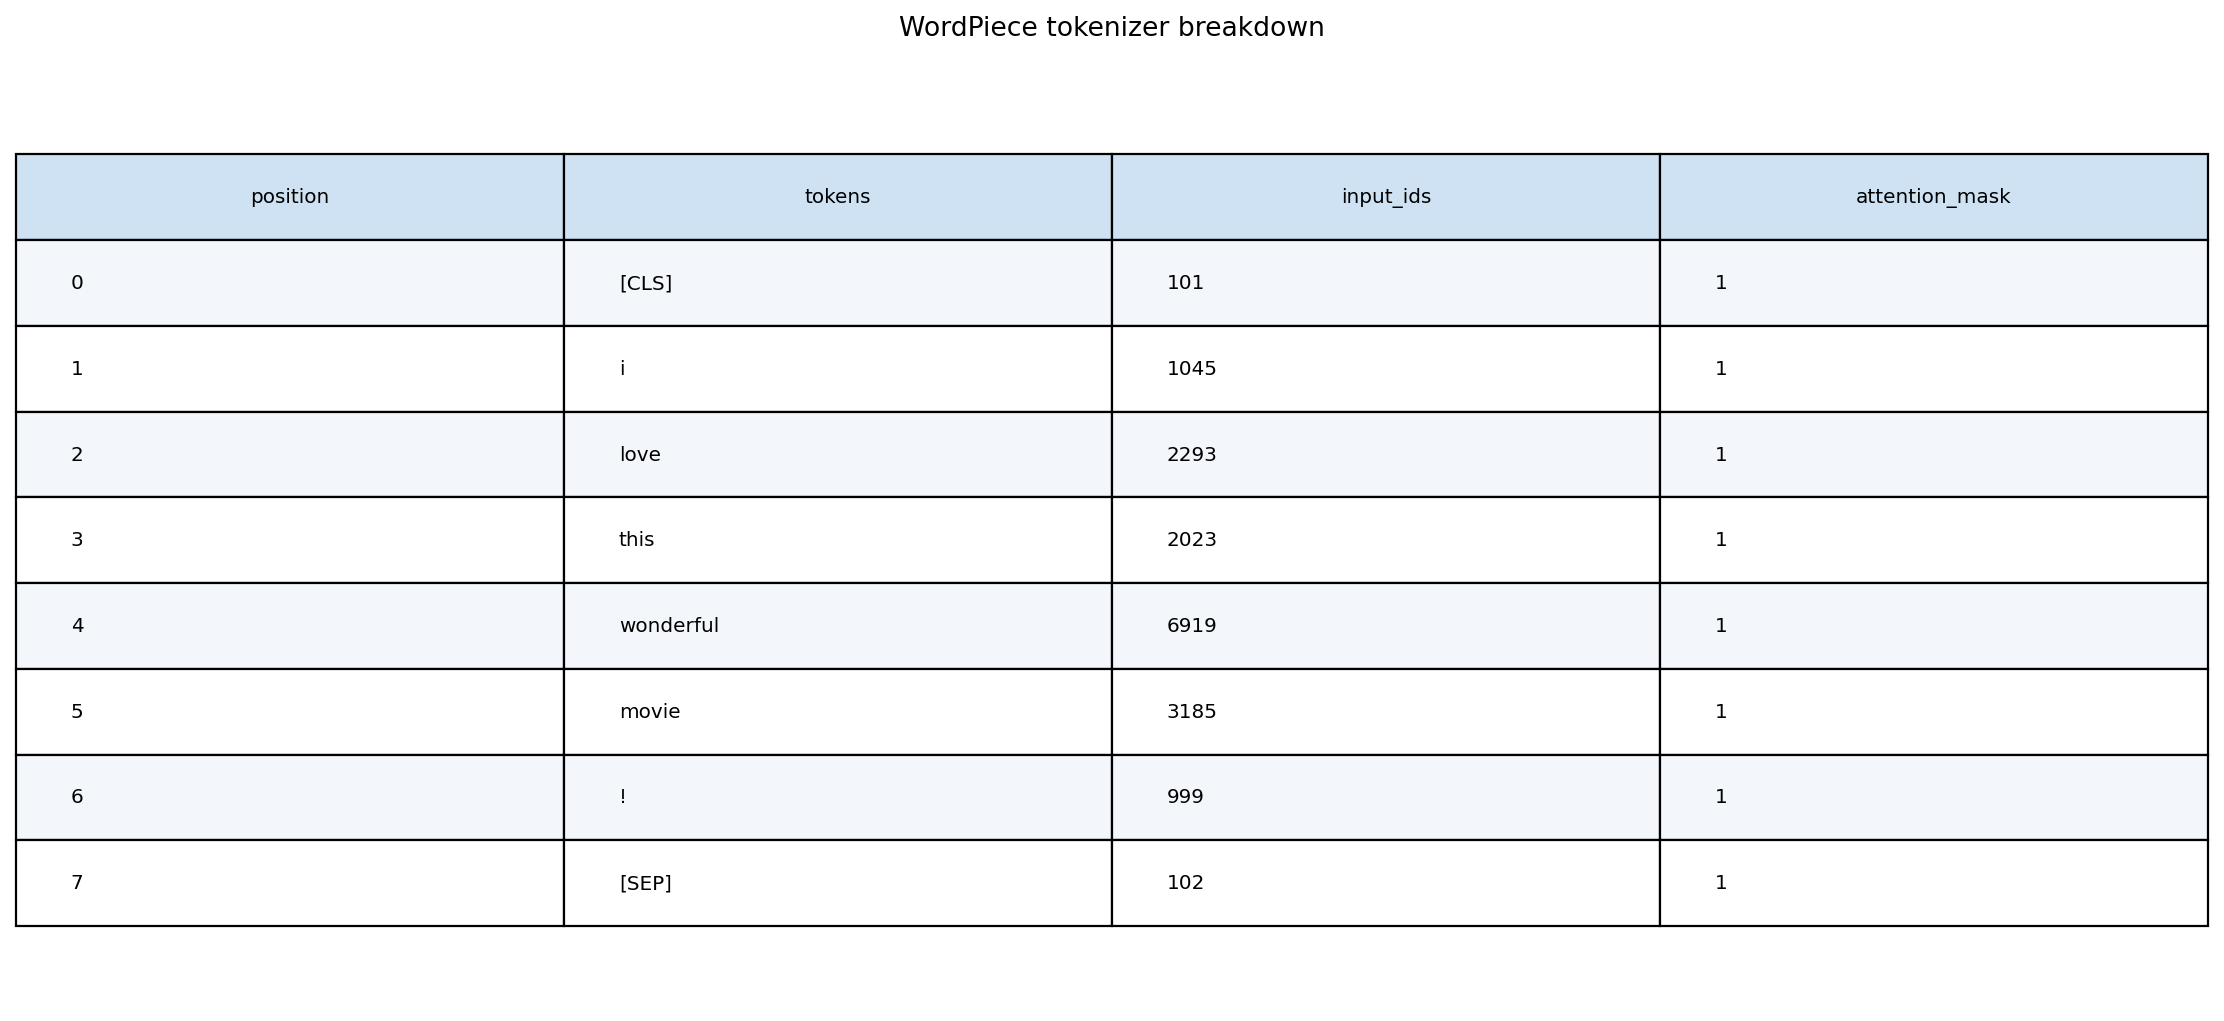

,position,tokens,input_ids,attention_mask
0,0,[CLS],101,1
1,1,i,1045,1
2,2,love,2293,1
3,3,this,2023,1
4,4,wonderful,6919,1
5,5,movie,3185,1
6,6,!,999,1
7,7,[SEP],102,1


In [3]:
show_figure(exercise1_analysis / "tokenizer_table.png", "Tokenization breakdown của câu mẫu")
display(pd.DataFrame(ex1_summary["tokenization"]))

## 1.3. Forward pass, logits và softmax

Model trả hai logits $z_0,z_1$. Đây là điểm số chưa chuẩn hóa, có thể âm hoặc lớn hơn 1. Softmax chuyển chúng thành xác suất:

$$p_c=\frac{\exp(z_c)}{\exp(z_0)+\exp(z_1)},\qquad \widehat y=\arg\max_c p_c.$$

Mẫu code tương đương luồng thực trong `manual_predict`:

```python
model.eval()
encoded = tokenizer(texts, padding=True, truncation=True,
                    max_length=128, return_tensors="pt")
with torch.inference_mode():
    logits = model(**encoded).logits
    probabilities = logits.softmax(dim=-1)
```

`eval()` tắt hành vi training của dropout; `inference_mode()` không ghi đồ thị gradient. Hai lời gọi có vai trò khác nhau và thường được dùng cùng nhau khi suy luận.

**Xác suất và nhãn sentiment trên ba câu mẫu**

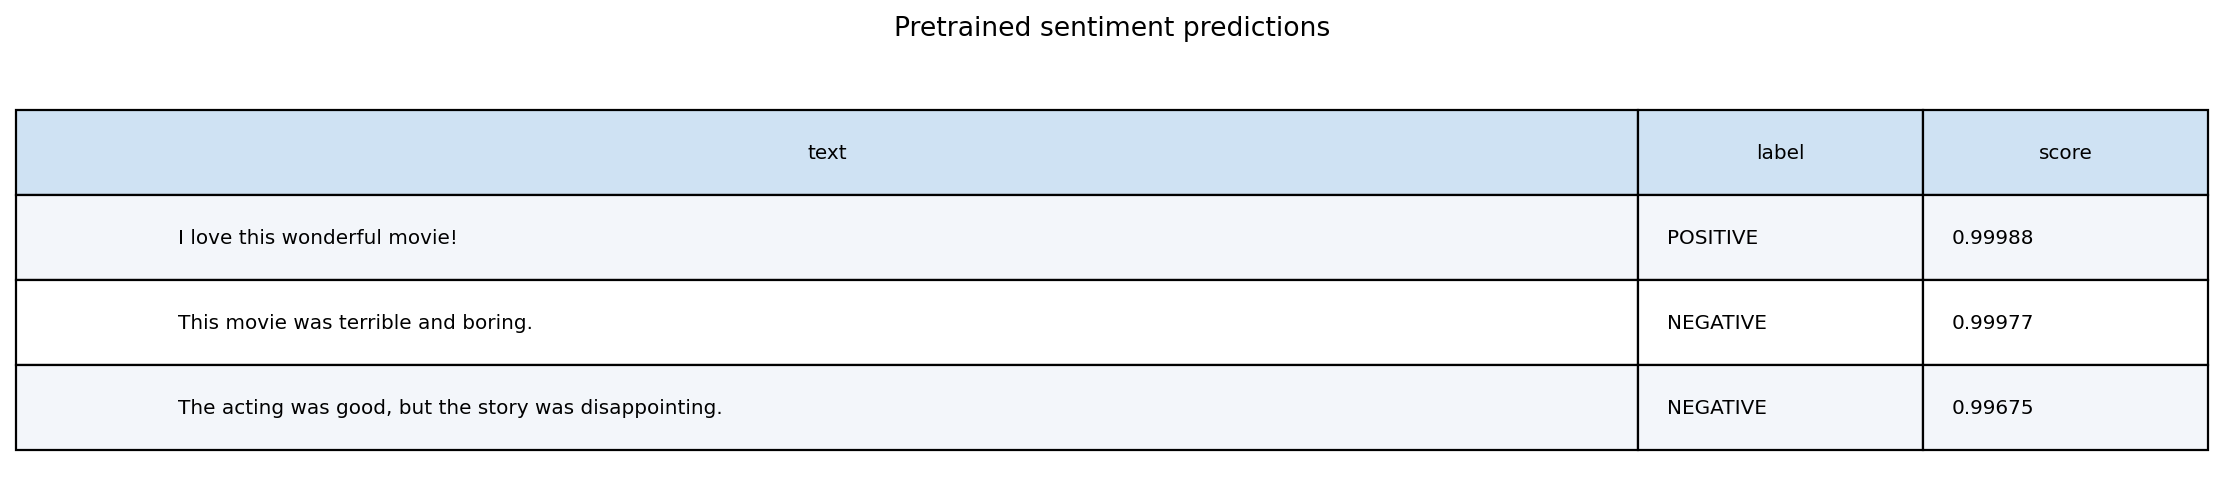

,text,label,score
0,I love this wonderful movie!,POSITIVE,0.999878
1,This movie was terrible and boring.,NEGATIVE,0.999768
2,"The acting was good, but the story was disappo...",NEGATIVE,0.996749


In [4]:
show_figure(exercise1_analysis / "sentiment_predictions.png", "Xác suất và nhãn sentiment trên ba câu mẫu")
display(pd.DataFrame(ex1_summary["predictions"])[["text", "label", "score"]])

## 1.4. Pipeline và manual inference có thật sự nhất quán?

Code kiểm tra nhãn giống nhau và độ lệch score không quá `1e-5`. Tolerance nhỏ chấp nhận sai số số học của cùng pipeline; không được thay model hoặc bỏ assertion để test qua. Khi kiểm tra này thất bại, cần kiểm tra checkpoint, tokenizer, device, precision và trạng thái eval trước khi diễn giải như một khác biệt thuật toán.

Đối chiếu dùng cùng bộ ba câu: câu khen trực tiếp, câu chê trực tiếp và câu có cấu trúc “good, but … disappointing”. Câu cuối minh họa rằng sentiment phụ thuộc toàn câu, không chỉ việc xuất hiện một tính từ tích cực.

**Đối chiếu pipeline/manual được lưu thành ảnh**

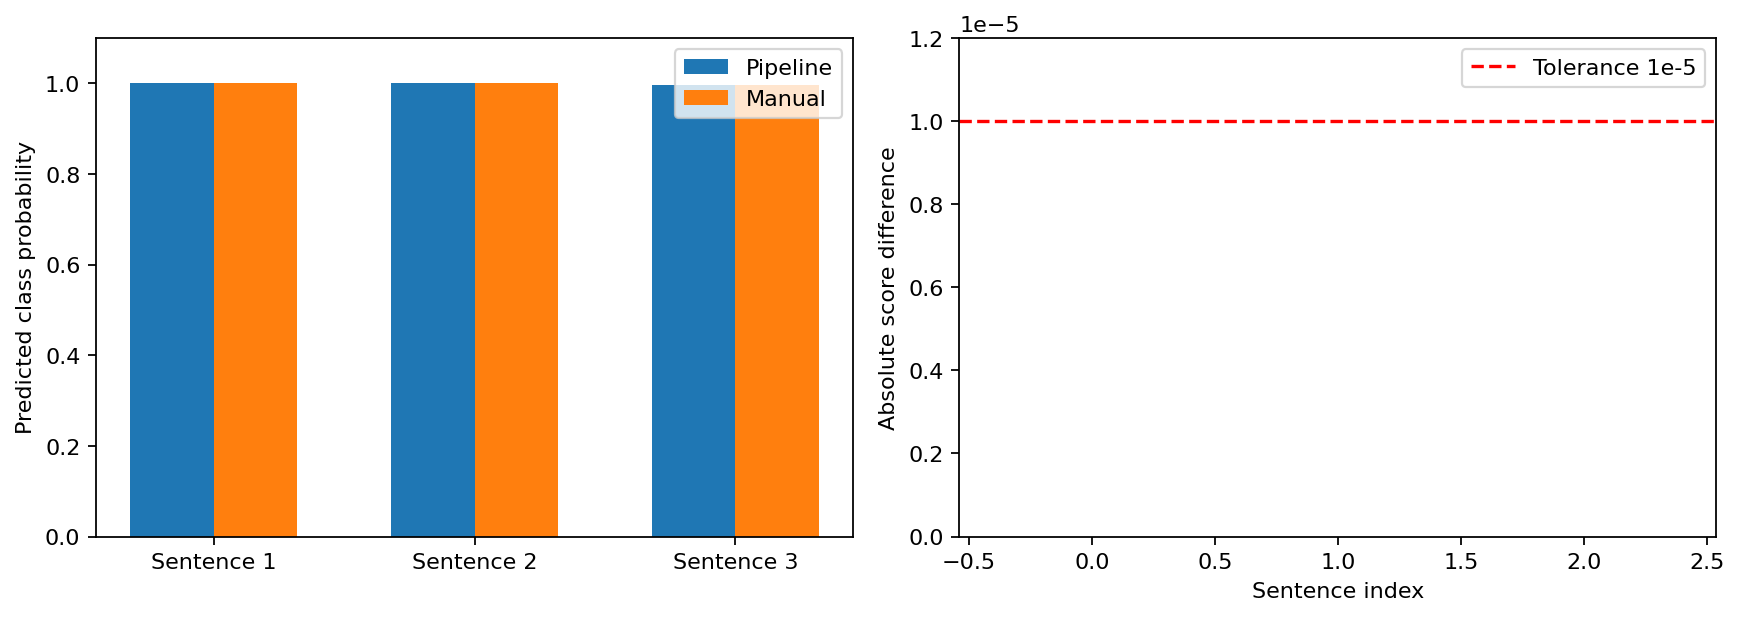

,text,pipeline_label,manual_label,pipeline_score,manual_score,difference
0,I love this wonderful movie!,POSITIVE,POSITIVE,0.999878,0.999878,0.0
1,This movie was terrible and boring.,NEGATIVE,NEGATIVE,0.999768,0.999768,0.0
2,"The acting was good, but the story was disappo...",NEGATIVE,NEGATIVE,0.996749,0.996749,0.0


In [5]:
show_figure(exercise1_analysis / "pipeline_manual_comparison.png", "Đối chiếu pipeline/manual được lưu thành ảnh")
display(pd.DataFrame(ex1_summary["comparison"]))

## 1.5. Diễn giải và giới hạn của confidence

Câu “I love this wonderful movie!” được mô hình gán Positive; “terrible and boring” được gán Negative. Ở câu có nhượng bộ, model chọn Negative. Confidence là xác suất theo model, không phải bằng chứng câu chắc chắn đúng với xác suất đó ngoài thực tế.

Các ví dụ trên chứng minh quy trình inference và đối chiếu API hoạt động. Chúng không chứng minh model đã được đánh giá tổng quát trên tiếng Việt, mỉa mai, lĩnh vực khác hoặc câu dài. Dataset/training của Exercise 1 là SST-2 của model pretrained, không phải một lần fine-tuning Rotten Tomatoes mới trong notebook này.

## 1.6. Artifacts của Exercise 1

| Artifact | Vai trò |
|---|---|
| Run gốc: `tokenizer_breakdown.json` | Token/ID/mask thực của câu mẫu |
| Run gốc: `predictions.json` | Nhãn, score và xác suất của hai phương pháp |
| Run phân tích: `summary.json` | Bảng đã chuẩn hóa để tái hiển thị |
| Run phân tích: ba PNG | Trực quan hóa được hiển thị trong notebook |
| `config.json`, snapshot, `console.log`, `manifest.json` | Truy vết điều kiện chạy và bytes của artifacts |

Hình được đọc từ file đã lưu, không chỉ tồn tại tạm trong notebook. Run phân tích giữ tham chiếu tới run inference và không ghi đè dữ liệu Kaggle gốc.

## 2.1. Data contract và phân chia vai trò

`cornell-movie-review-data/rotten_tomatoes` được dùng đầy đủ: **8.530 train, 1.066 validation, 1.066 test**. Giữ split chính thức và không lấy subset. Mỗi review có đúng một nhãn: 0 Negative, 1 Positive.

Train là dữ liệu cập nhật trọng số. Validation được dùng trong chọn checkpoint, sau đó chọn threshold của checkpoint đã chọn. Test được giữ để đánh giá cuối. Không chọn lại hyperparameters hoặc ngưỡng dựa trên việc test tăng bao nhiêu.

Run lịch sử hiện có đã hoàn thành ba epochs với quyết định argmax. Nó chưa lưu validation probabilities, nên phần threshold-selection mới không được coi là đã thực hiện trên run đó.

In [6]:
finetuning_run = finetune(config) if MODE == "train" else selected_run("finetuning")
finetuning_audit = audit_finetuning(finetuning_run)
analysis_run = ensure_analysis(finetuning_run)
analysis_summary = read_json(analysis_run / "analysis_summary.json")
analysis_tables = read_json(analysis_run / "tables.json")
print("Run fine-tuning:", finetuning_run.name)
print("Run phân tích đã lưu:", analysis_run)
print("Số dự đoán test được đối chiếu:", finetuning_audit["correct"] + finetuning_audit["incorrect"])
threshold_analysis_run = ensure_threshold_analysis(finetuning_run)
threshold_tables = read_json(threshold_analysis_run / "tables.json") if threshold_analysis_run else None
threshold_summary = read_json(threshold_analysis_run / "summary.json") if threshold_analysis_run else None
if threshold_analysis_run:
    print("Run phân tích threshold và checkpoint reload:", threshold_analysis_run)

print("Metrics argmax của run đang xem:")
display(pd.DataFrame([analysis_summary["metrics"]]))
print("Measured test loss của run đang xem:", analysis_summary["measured_test_loss"])
print("Trạng thái loss:", analysis_summary["test_loss_status"])


Run fine-tuning: 20261026T155822Z_finetuning_2c2f0401
Run phân tích đã lưu: /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261026T192100Z_analysis_388b4fff
Số dự đoán test được đối chiếu: 1066
Run phân tích threshold và checkpoint reload: /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261026T192102Z_threshold_analysis_40690c71
Metrics argmax của run đang xem:


,accuracy,binary_precision,binary_recall,binary_f1,macro_precision,macro_recall,macro_f1
0,0.839587,0.835185,0.846154,0.840634,0.839646,0.839587,0.83958


Measured test loss của run đang xem: 0.544316291809082
Trạng thái loss: measured in source test_runtime_metrics.json; reconstructed NLL is separate


## 2.2. EDA — số lượng, nhãn và độ dài review

Cần phân biệt quy mô split, cân bằng nhãn và độ dài văn bản. Kích thước train/validation/test có trong `data_statistics.json`. Toàn bộ nhãn và văn bản test có trong `all_predictions.json`, cho phép kiểm tra trực tiếp phân bố test và số từ review test. Độ dài token train là thống kê khác và có biểu đồ riêng.

Không gọi biểu đồ số từ test là độ dài token train: một từ có thể tách thành nhiều tokens. Không tự suy ra phân bố nhãn train/validation từ phân bố test khi run lịch sử chưa lưu các nhãn đó. EDA của lần chạy mới có thể mở rộng nhưng phải lưu phạm vi và nguồn dữ liệu rõ ràng.

,split,samples
0,train,8530
1,validation,1066
2,test,1066


,split,label,samples
0,train,0,4265
1,train,1,4265
2,validation,0,533
3,validation,1,533
4,test,0,533
5,test,1,533


**Phân bố nhãn của cả ba official splits**

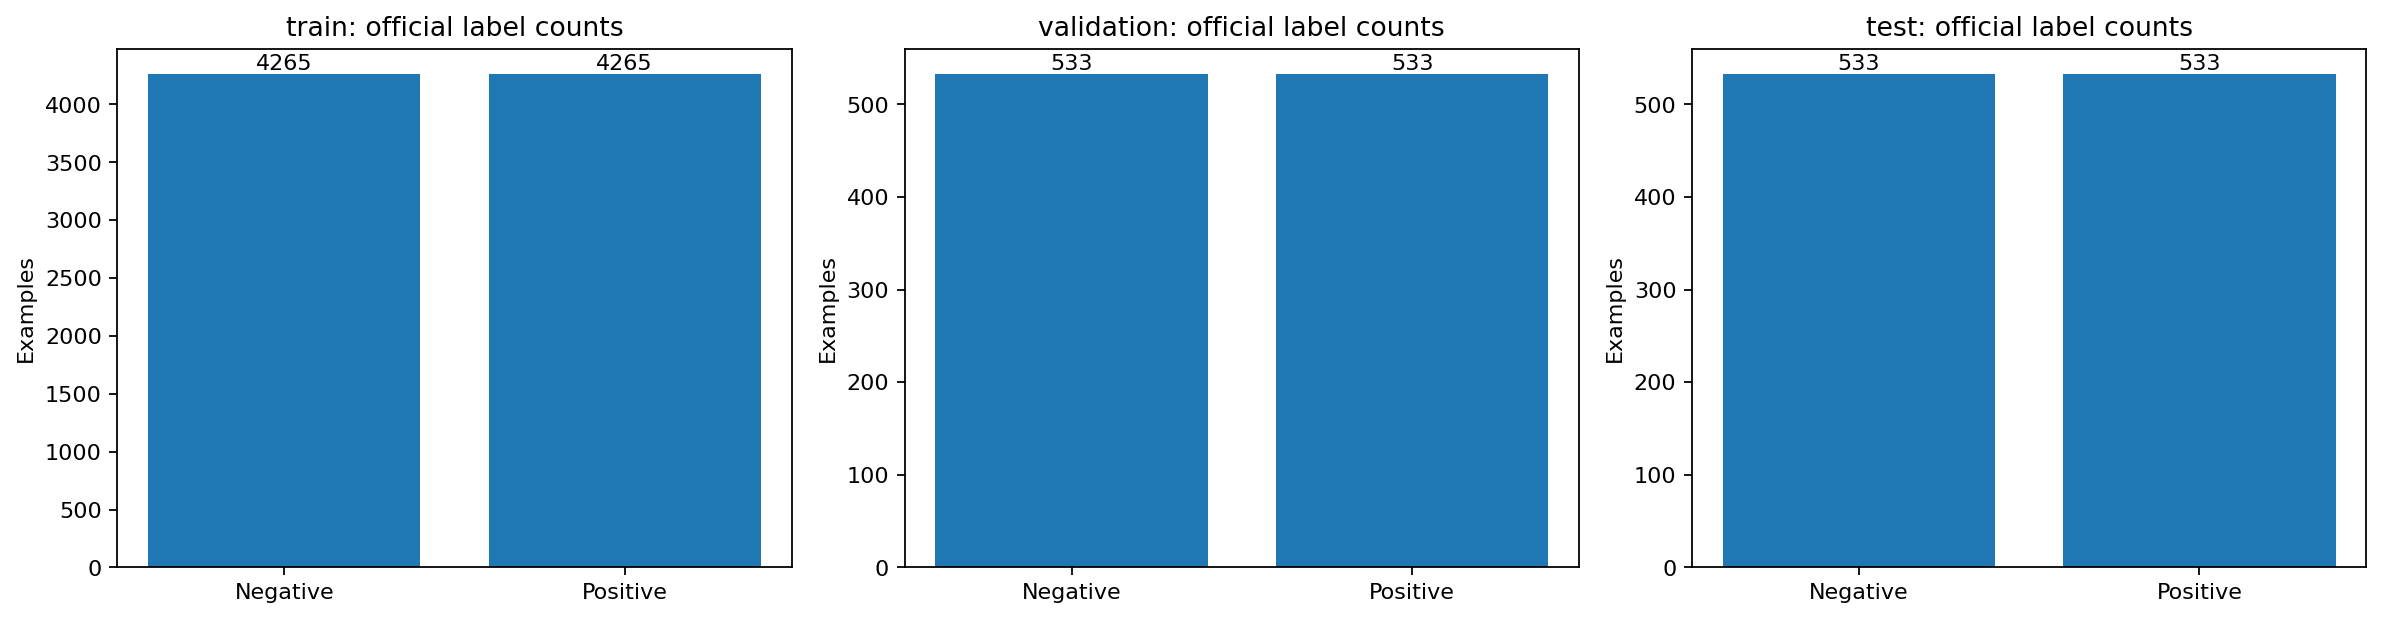

**Phân bố số từ review test, không phải token length train**

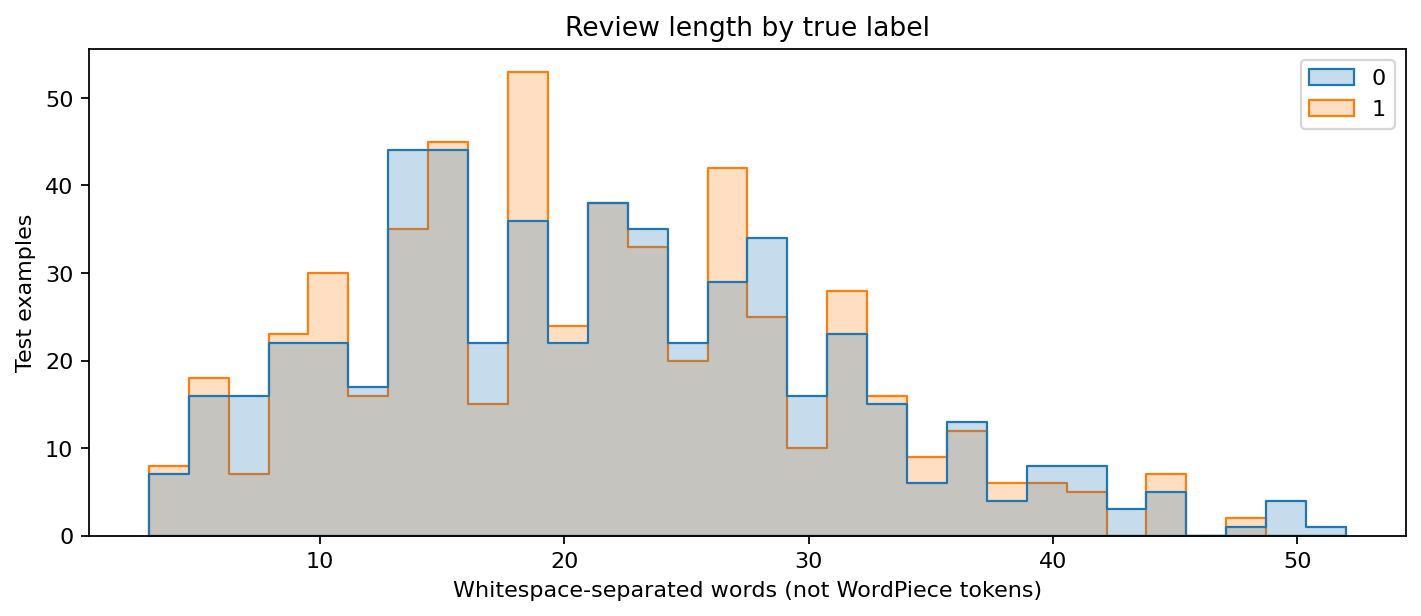

In [7]:
display(pd.DataFrame(analysis_tables["split_sizes"]))
display(pd.DataFrame(analysis_tables["label_counts"]))
show_figure(analysis_run / "class_distribution.png", "Phân bố nhãn của cả ba official splits")
show_figure(analysis_run / "review_length_distribution.png", "Phân bố số từ review test, không phải token length train")

## 2.3. Tokenization, truncation và dynamic padding

`tokenize_data` gọi tokenizer theo batch, dùng truncation và max length 128. `DataCollatorWithPadding` thực hiện padding khi lấy batch; không cần lưu mọi mẫu đã đệm đến 128 trong dataset.

```python
tokenized = dataset.map(
    lambda batch: tokenizer(batch["text"], truncation=True, max_length=128),
    batched=True,
    remove_columns=["text"],
)
collator = DataCollatorWithPadding(tokenizer)
```

Run Kaggle tham chiếu ghi train trung bình 27,37 tokens, tối đa 78 và tỉ lệ truncation 0%. Kết luận không bị cắt áp dụng cho **train đã đo**, không tự suy rộng sang split chưa thống kê. Mask giúp bỏ qua token đệm; label được collator chuyển thành `labels` để model tính loss.

,mean,max,truncated_fraction
0,27.368347,78,0.0


**Token length train trước truncation và cutoff 128**

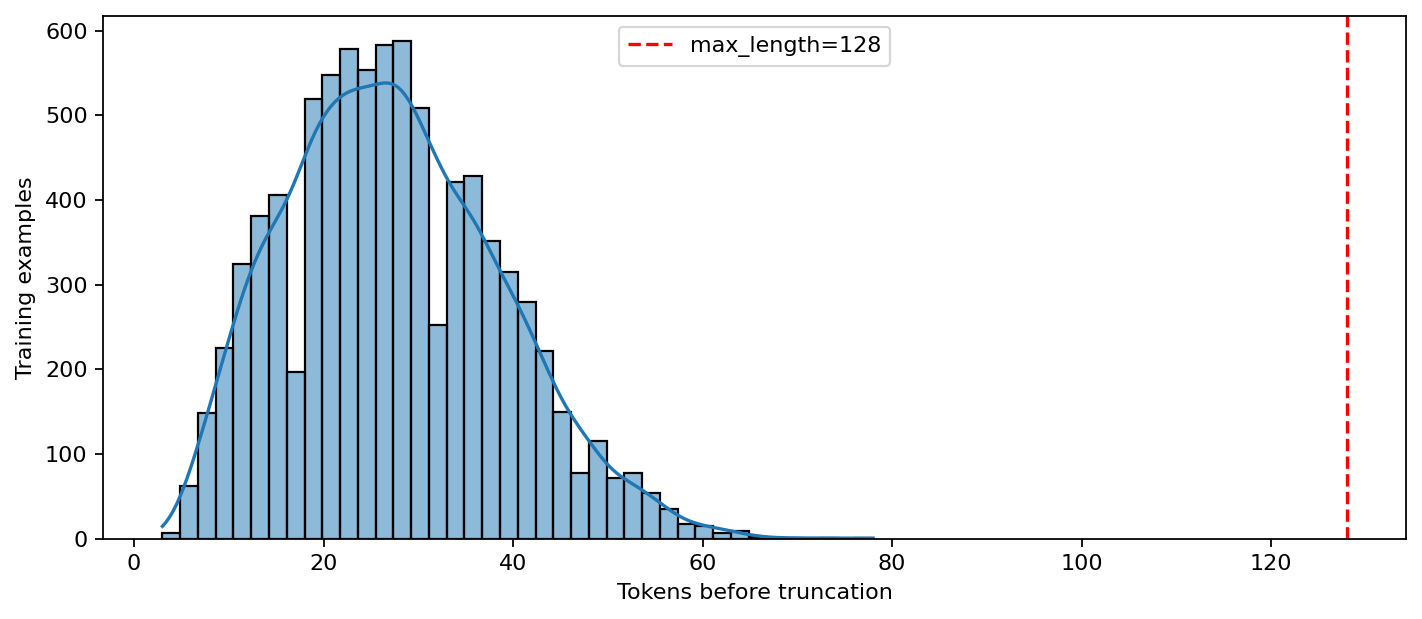

In [8]:
display(pd.DataFrame(analysis_tables["token_statistics"]))
show_figure(finetuning_run / "token_length_distribution.png", "Token length train trước truncation và cutoff 128")

## 2.4. Kiến trúc và hợp đồng tensor

Backbone DistilBERT dùng sáu transformer encoder layers, hidden size 768 và multi-head self-attention. `AutoModelForSequenceClassification` thêm pre-classifier, activation, dropout và classifier hai lớp. Đầu phân loại mới khởi tạo nên cảnh báo “weights newly initialized” khi tải backbone là bình thường.

| Giai đoạn | Tensor / cấu trúc | Ý nghĩa |
|---|---|---|
| Tokenizer/collator | `input_ids`, `attention_mask`: `(B,S)` | B review, S token sau padding |
| Labels | `(B,)`, số nguyên 0/1 | Một nhãn cho mỗi review |
| Backbone | Biểu diễn contextual theo token | Mỗi token phụ thuộc ngữ cảnh |
| Classification head | Logits `(B,2)` | Điểm số cho hai lớp |
| Loss | Scalar cross-entropy | Đại lượng tối ưu khi train |

Cross-entropy nhận **logits**, không cần softmax thủ công trước loss. Softmax dùng khi cần xác suất để vẽ ROC/PR, phân tích confidence hoặc áp threshold.

## 2.5. Sanity overfit và thiết kế training

Trước khi tốn tài nguyên cho job lớn, test ép học một batch nhỏ để xác nhận model/loss/gradient/optimizer có thể học. Bài test dùng mô hình disposable, không đem trọng số đã overfit vào fine-tuning chính.

Cấu hình hiện hành: AdamW, LR `2e-5`, weight decay `0.01`, warmup ratio `0.1`, ba epochs, batch train/eval 16/32. LR nhỏ hạn chế phá vỡ biểu diễn pretrained; warmup giúp ổn định các bước đầu. Đây là lựa chọn thực hành được chốt, không phải chứng minh tối ưu trên mọi dataset.

FP16 chỉ bật khi CUDA có sẵn; seed 42 hỗ trợ tái lập. Môi trường của run được lưu trong snapshot. Không khẳng định seed cho kết quả bit-identical trên mọi phiên bản/thiết bị.

In [9]:
display(pd.DataFrame(analysis_tables["training_config"]))
display(pd.DataFrame(analysis_tables["environment_versions"]))

,dataset_name,dataset_revision,model_name,model_revision,max_length,batch_size,eval_batch_size,learning_rate,num_train_epochs,weight_decay,warmup_ratio,fp16,threshold_selection
0,cornell-movie-review-data/rotten_tomatoes,aa13bc287fa6fcab6daf52f0dfb9994269ffea28,distilbert/distilbert-base-uncased,12040accade4e8a0f71eabdb258fecc2e7e948be,128,16,32,0.00002,3,0.01,0.1,True,"{'enabled': True, 'selection_metric': 'macro_f..."


,library,version
0,torch,2.6.0
1,transformers,4.48.3
2,datasets,3.2.0
3,evaluate,0.4.3
4,accelerate,1.3.0
5,numpy,2.2.2
6,scikit-learn,1.6.1


## 2.6. Trainer, lịch học và checkpoint selection

Trainer xử lý dataloader, forward/backward, gradient accumulation nếu cấu hình, optimizer, scheduler và evaluation. Với một GPU và batch 16, `ceil(8530/16)=534` optimizer steps mỗi epoch; ba epochs có 1.602 bước.

Cấu trúc khởi tạo tương ứng trong module (trích lược để giải thích):

```python
args = TrainingArguments(
    output_dir=str(run_path / "checkpoints"),
    learning_rate=2e-5,
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
)
trainer = Trainer(model=model, args=args,
                  train_dataset=ds["train"],
                  eval_dataset=ds["validation"],
                  data_collator=DataCollatorWithPadding(tokenizer))
trainer.train()
```

Mỗi epoch có validation và checkpoint. Tiêu chí định trước là `metric_for_best_model="accuracy"`, `load_best_model_at_end=True`. Không đổi sang chọn loss chỉ vì đã thấy kết quả test hoặc vì epoch khác có một metric trông đẹp hơn.

Bảng dưới tách loss trung bình trong quá trình tối ưu với loss đo khi model ở eval mode trên train. Dropout và thời điểm đo khác nhau khiến hai giá trị không nhất thiết bằng nhau.

,epoch,step,optimization_loss,train_eval_loss,train_accuracy,validation_loss,validation_accuracy
0,1.0,534,0.4609,0.293893,0.880774,0.403606,0.822702
1,2.0,1068,0.2597,0.126099,0.959789,0.378666,0.841463
2,3.0,1602,0.1515,0.093490,0.972098,0.489638,0.843340


**Learning curves: train/validation loss và accuracy**

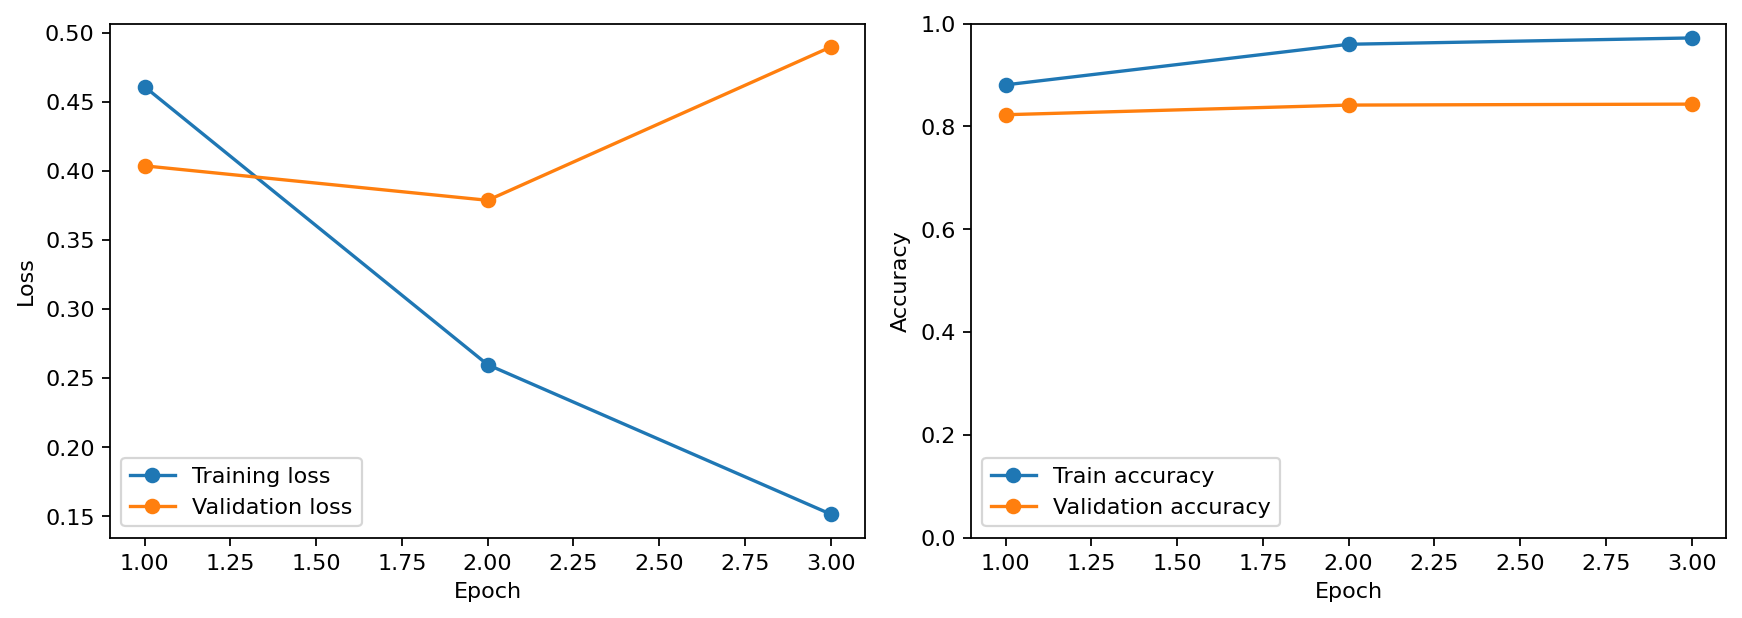

In [10]:
display(pd.DataFrame(analysis_tables["epoch_history"]))
show_figure(finetuning_run / "learning_curves.png", "Learning curves: train/validation loss và accuracy")

### Đọc đường học, không chỉ liệt kê ảnh

Ở run Kaggle tham chiếu, train accuracy tăng từ khoảng 88,08% lên 97,21%, trong khi validation tăng từ 82,27% lên 84,33%. Validation loss giảm ở epoch 2 nhưng tăng ở epoch 3. Đây là dấu hiệu overfitting, không phải bằng chứng cứ train thêm là test sẽ tốt hơn.

Epoch 3 được chọn theo validation accuracy; epoch 2 có validation loss thấp hơn. Chênh accuracy validation giữa hai epoch cuối chỉ tương ứng hai mẫu. Báo cáo giữ nguyên tiêu chí selection và ghi rõ giới hạn của một seed.

## 2.7. Quét threshold cho binary classification

Argmax trên hai xác suất tương đương ngưỡng 0,5 khi không có tie. Trong nhánh threshold dùng quy ước **Positive nếu $p_1\geq t$**; ở đúng tie, quy ước này khác argmax chọn index nhỏ nhất.

Giảm ngưỡng thường tăng recall và số False Positives; tăng ngưỡng thường giảm False Positives nhưng có thể bỏ sót thêm Positive. Không có một ngưỡng “tốt nhất” độc lập mục tiêu.

Quy trình mới: lấy probabilities trên **validation của checkpoint đã chọn**, quét grid định trước, chọn Macro F1 cao nhất, tie-break gần 0,5 rồi ngưỡng nhỏ hơn, lưu `decision_threshold.json`, sau đó cố định ngưỡng để đánh giá test. Không đưa nhãn test vào hàm chọn threshold.

```python
selection = select_validation_threshold(
    validation_labels, validation_positive_probabilities,
    split="validation",
)
frozen_threshold = selection["selected_threshold"]
test_predictions = (test_positive_probabilities >= frozen_threshold).astype(int)
```

Đoạn minh họa dùng hai tập đầu vào tách biệt. Hàm selection từ chối `split="test"`; việc tái dùng test labels dưới tên validation vẫn là lỗi phương pháp mà kiểm tra string không tự phát hiện được. Vì vậy cả code guard lẫn provenance/split contract đều cần thiết.

**Kết quả đã thực thi:** run `20261026T155822Z_finetuning_2c2f0401` dùng đủ 1.066 mẫu validation của checkpoint đã chọn, quét 19 ngưỡng từ 0,05 đến 0,95, chọn **0,8** theo Macro F1. Validation Macro F1 tăng từ **0,843279** ở 0,5 lên **0,852663** ở 0,8. Validation sweep là phase trong cùng run fine-tuning, sau checkpoint selection và trước test; không cập nhật weights ở bước chọn ngưỡng.


,method,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,Reference threshold 0.5,0.5,0.84334,0.830325,0.863039,0.82364,0.17636,0.846366,0.843279,439,94,73,460,533,533,1066
1,Selected threshold 0.8,0.8,0.85272,0.867188,0.833021,0.87242,0.12758,0.849761,0.852663,465,68,89,444,533,533,1066


**Quét 19 threshold trên validation; policy được đóng băng tại 0,8**

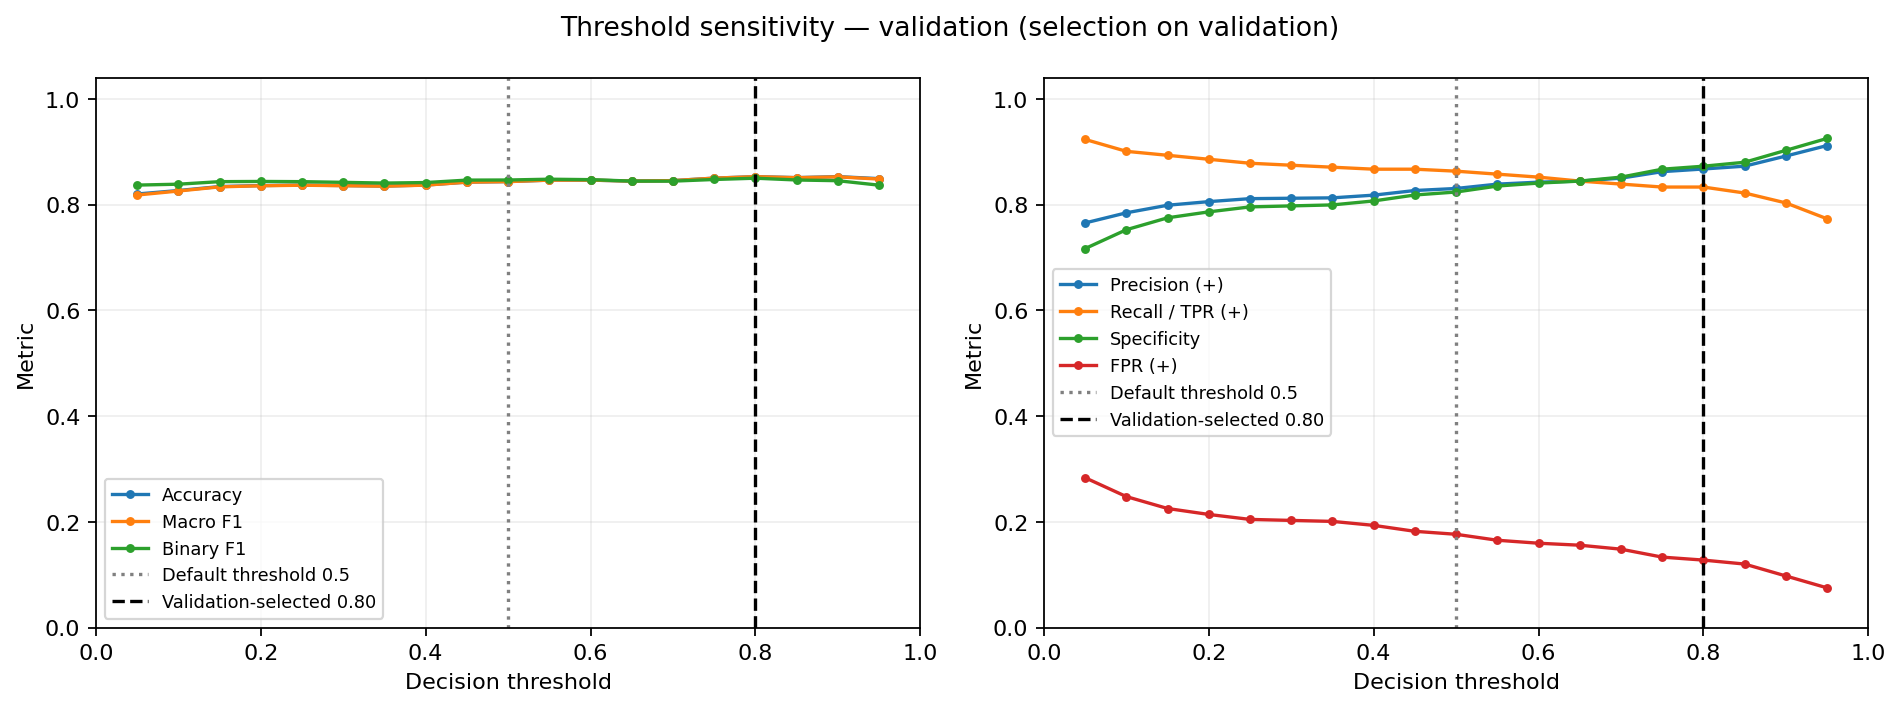

**Validation: so sánh threshold tham chiếu với threshold đã chọn**

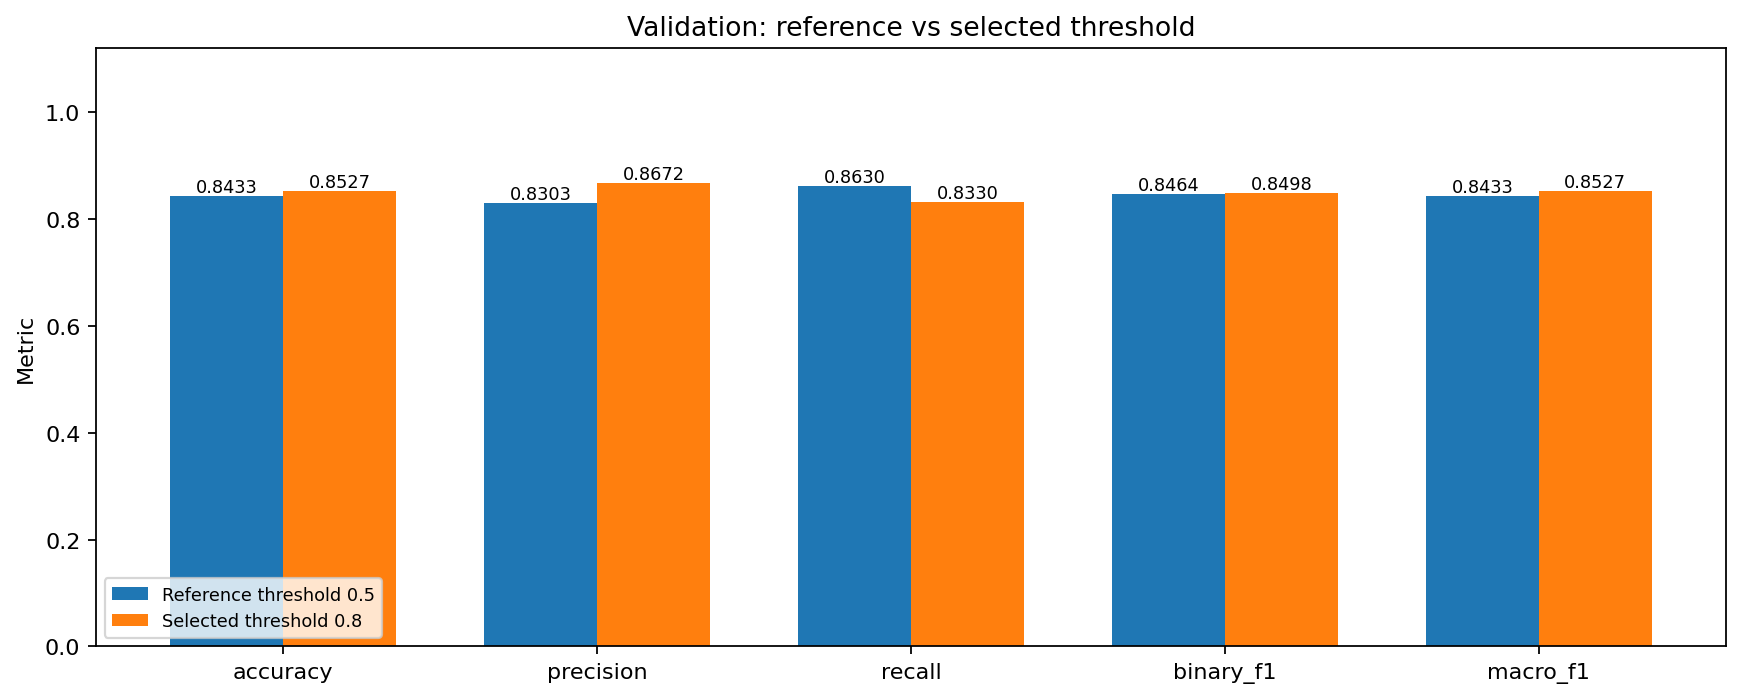

,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,0.05,0.819887,0.765163,0.923077,0.716698,0.283302,0.836735,0.817949,382,151,41,492,533,533,1066
1,0.10,0.826454,0.784314,0.900563,0.752345,0.247655,0.838428,0.825496,401,132,53,480,533,533,1066
2,0.15,0.833959,0.798658,0.893058,0.774859,0.225141,0.843224,0.833377,413,120,57,476,533,533,1066
3,0.20,0.835835,0.805461,0.885553,0.786116,0.213884,0.843610,0.835428,419,114,61,472,533,533,1066
4,0.25,0.836773,0.811092,0.878049,0.795497,0.204503,0.843243,0.836494,424,109,65,468,533,533,1066
5,0.30,0.835835,0.811847,0.874296,0.797373,0.202627,0.841915,0.835592,425,108,67,466,533,533,1066
6,0.35,0.834897,0.812609,0.870544,0.799250,0.200750,0.840580,0.834687,426,107,69,464,533,533,1066
7,0.40,0.836773,0.817699,0.866792,0.806754,0.193246,0.841530,0.836626,430,103,71,462,533,533,1066
8,0.45,0.842402,0.826476,0.866792,0.818011,0.181989,0.846154,0.842308,436,97,71,462,533,533,1066
9,0.50,0.843340,0.830325,0.863039,0.823640,0.176360,0.846366,0.843279,439,94,73,460,533,533,1066


**Test sensitivity diagnostic lịch sử; không dùng để chọn policy**

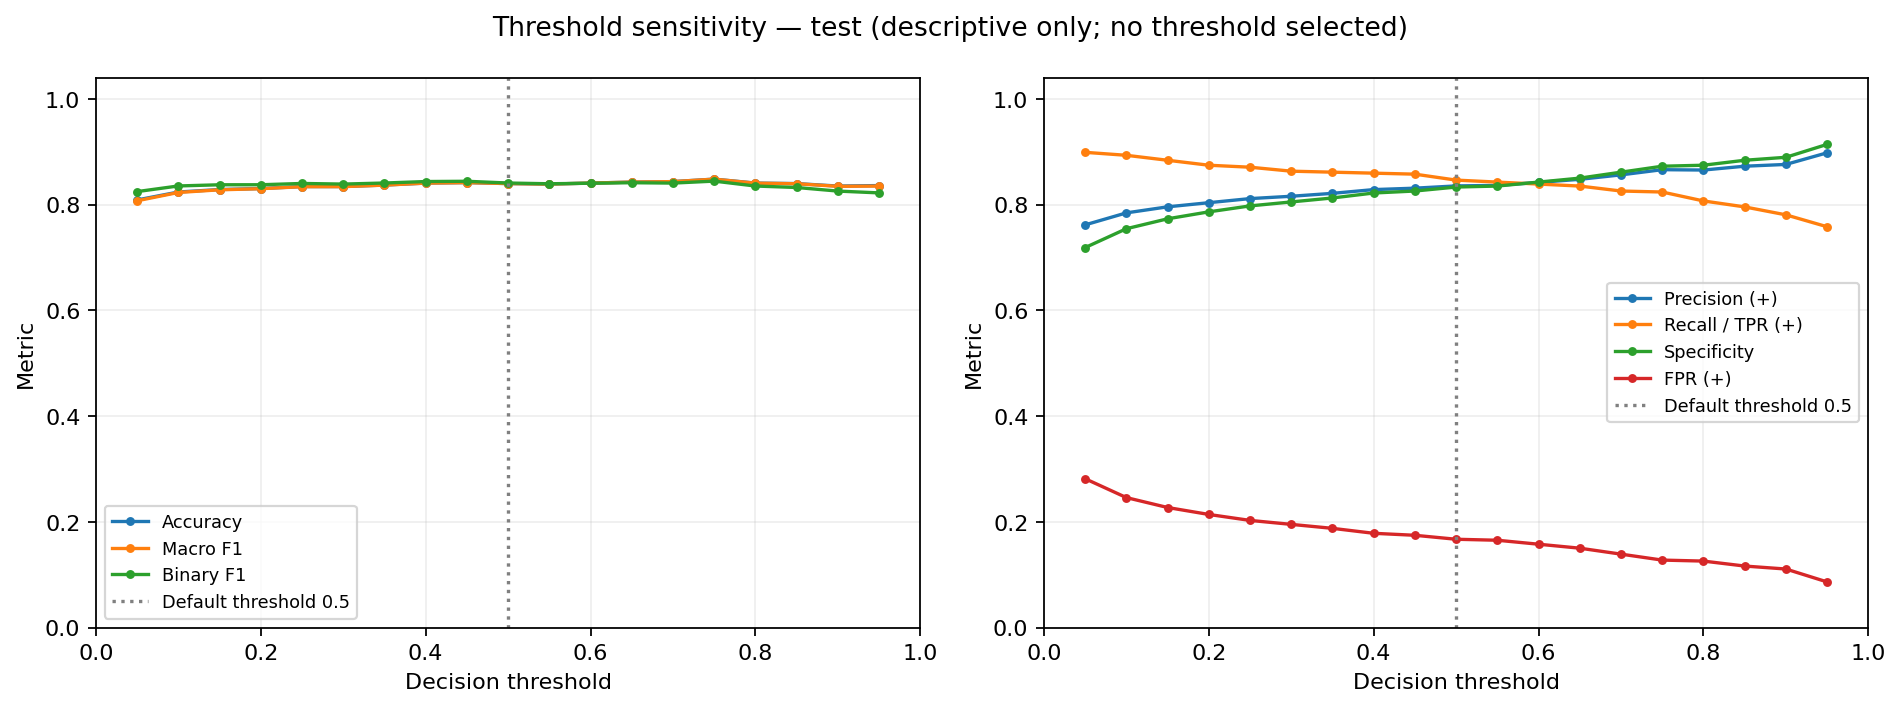

In [11]:
decision_path = finetuning_run / "decision_threshold.json"
if threshold_analysis_run:
    display(pd.DataFrame(threshold_tables["validation_comparison"]))
    show_figure(threshold_analysis_run / "validation_threshold_curves.png",
                "Quét 19 threshold trên validation; policy được đóng băng tại 0,8")
    show_figure(threshold_analysis_run / "validation_comparison.png",
                "Validation: so sánh threshold tham chiếu với threshold đã chọn")
    display(pd.DataFrame(threshold_tables["validation_grid"]))
elif decision_path.is_file():
    decision = read_json(decision_path)
    display(pd.DataFrame([decision["baseline_metrics"], decision["selected_metrics"]]))
    display(pd.DataFrame(decision["curve"]))
    show_figure(finetuning_run / "validation_threshold/threshold_curves.png",
                "Threshold sweep trên validation của run mới")
else:
    display(Markdown("Run này chưa có policy validation. Khôi phục checkpoint rồi chạy select_threshold.py; không chọn ngưỡng từ test."))

show_figure(analysis_run / "threshold_test_diagnostic/threshold_curves.png",
            "Test sensitivity diagnostic lịch sử; không dùng để chọn policy")

### Phân biệt selection, evaluation và diagnostic

Selection chỉ đọc validation; `20261026T160058Z_evaluation_07c24854` đọc policy đã đóng băng và đánh giá đủ 1.066 mẫu test. Bản policy lưu trong evaluation và inference phải giống selection, có SHA256 gắn với weights gốc. Module [threshold_evidence.py](../src/threshold_evidence.py) đối chiếu cả ba run và tính lại metrics; [threshold_analysis.py](../src/threshold_analysis.py) lưu bảng/ảnh so sánh trong run `threshold_analysis`.

Đường test diagnostic lịch sử chỉ mô tả độ nhạy, không chọn ngưỡng và không thay policy. Test đã được quan sát trong quá trình phát triển, nên không gọi lần đánh giá bổ sung này là một benchmark mù mới. Notebook `view` kiểm tra bằng chứng; không thực thi model khi checkpoint được lưu riêng.


## 2.8. Đánh giá tổng thể và baseline

Accuracy đo tỉ lệ đúng; Precision Positive trả lời “trong các dự đoán Positive, bao nhiêu đúng?”; Recall trả lời “trong Positive thực, bao nhiêu được phát hiện?”. F1 là trung bình điều hòa Precision/Recall. Macro F1 trung bình đều F1 hai lớp, khác Binary F1 chỉ xét lớp Positive.

Baseline hằng Negative trên test cân bằng đạt Accuracy 50%, Macro F1 33,33%. Đây là baseline tính từ nhãn đã lưu, không phải accuracy giả định của backbone với classifier khởi tạo ngẫu nhiên. So sánh dưới đây dùng cùng test để mô tả mức cải thiện; không dùng test để chọn mô hình.

,model,accuracy,binary_precision,binary_recall,binary_f1,macro_precision,macro_recall,macro_f1
0,Constant NEGATIVE,0.500000,0.000000,0.000000,0.000000,0.250000,0.500000,0.333333
1,Fine-tuned DistilBERT (argmax),0.839587,0.835185,0.846154,0.840634,0.839646,0.839587,0.839580


**So sánh model với baseline hằng trên cùng test**

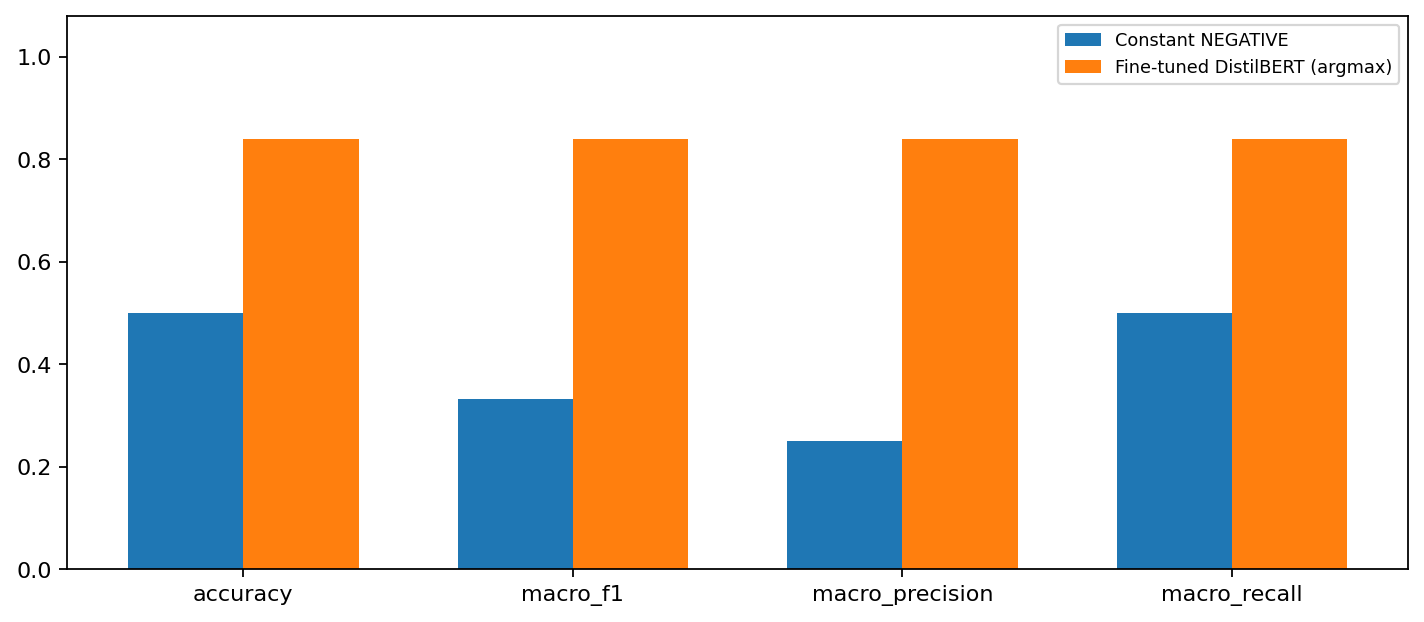

**Accuracy và Binary Precision/Recall/F1 của run gốc**

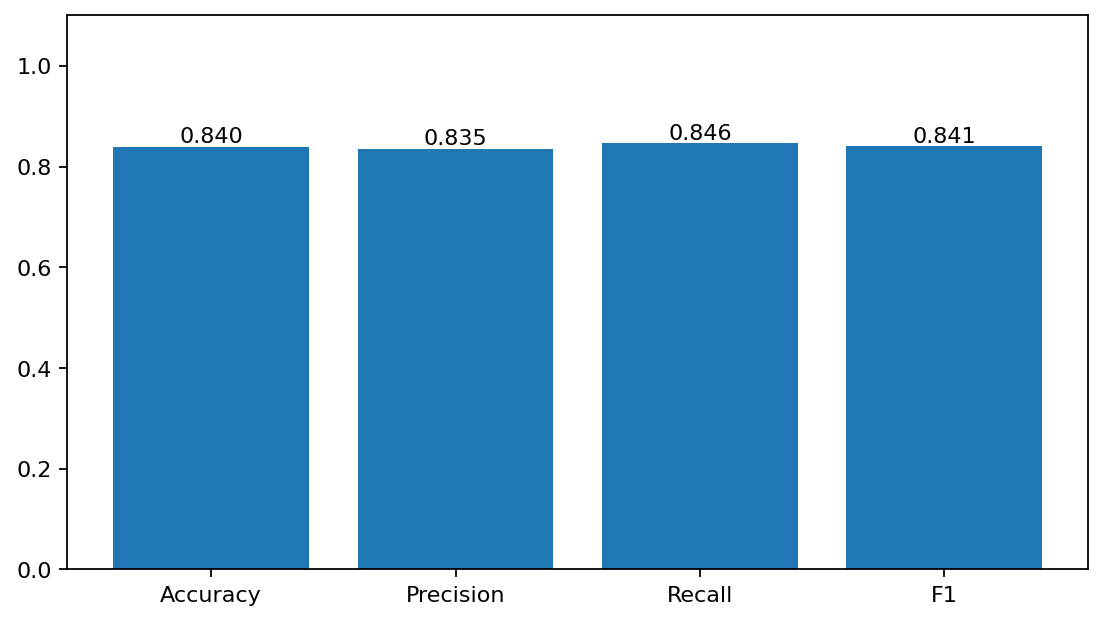

In [12]:
display(pd.DataFrame(analysis_tables["metrics_comparison"]))
show_figure(analysis_run / "metric_comparison.png", "So sánh model với baseline hằng trên cùng test")
show_figure(finetuning_run / "metrics_bar.png", "Accuracy và Binary Precision/Recall/F1 của run gốc")

### Test tại policy cố định: lợi ích nhỏ và đánh đổi lỗi

Cùng checkpoint, cùng 1.066 mẫu test: argmax đúng 895 mẫu, policy 0,8 đúng 896 mẫu. Positive Precision tăng **83,52% → 86,52%**, Recall giảm **84,62% → 80,68%**; Binary F1 giảm **84,06% → 83,50%**. Macro F1 tăng nhẹ **83,9580% → 84,0343%**. Không quét lại để tối ưu test.

Loss đo sau reload là **0,5442678** cho cùng probabilities ở cả hai quy tắc. Nó khác reconstructed NLL của probabilities FP16 lịch sử (~0,5442964); fine-tuning đã đo test loss 0,5443163, còn evaluation sau reload đo 0,5442678; giữ riêng nguồn và precision.


,method,accuracy,precision,recall,binary_f1,macro_f1,threshold,specificity,FPR,TN,FP,FN,TP,negative_support,positive_support,sample_count,selection_split,selection_performed_on_test
0,Argmax,0.839587,0.835185,0.846154,0.840634,0.839580,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Validation threshold 0.8,0.840525,0.865191,0.806754,0.834951,0.840343,0.8,0.874296,0.125704,466.0,67.0,103.0,430.0,533.0,533.0,1066.0,validation,False


**Test metrics của argmax và policy validation đã đóng băng**

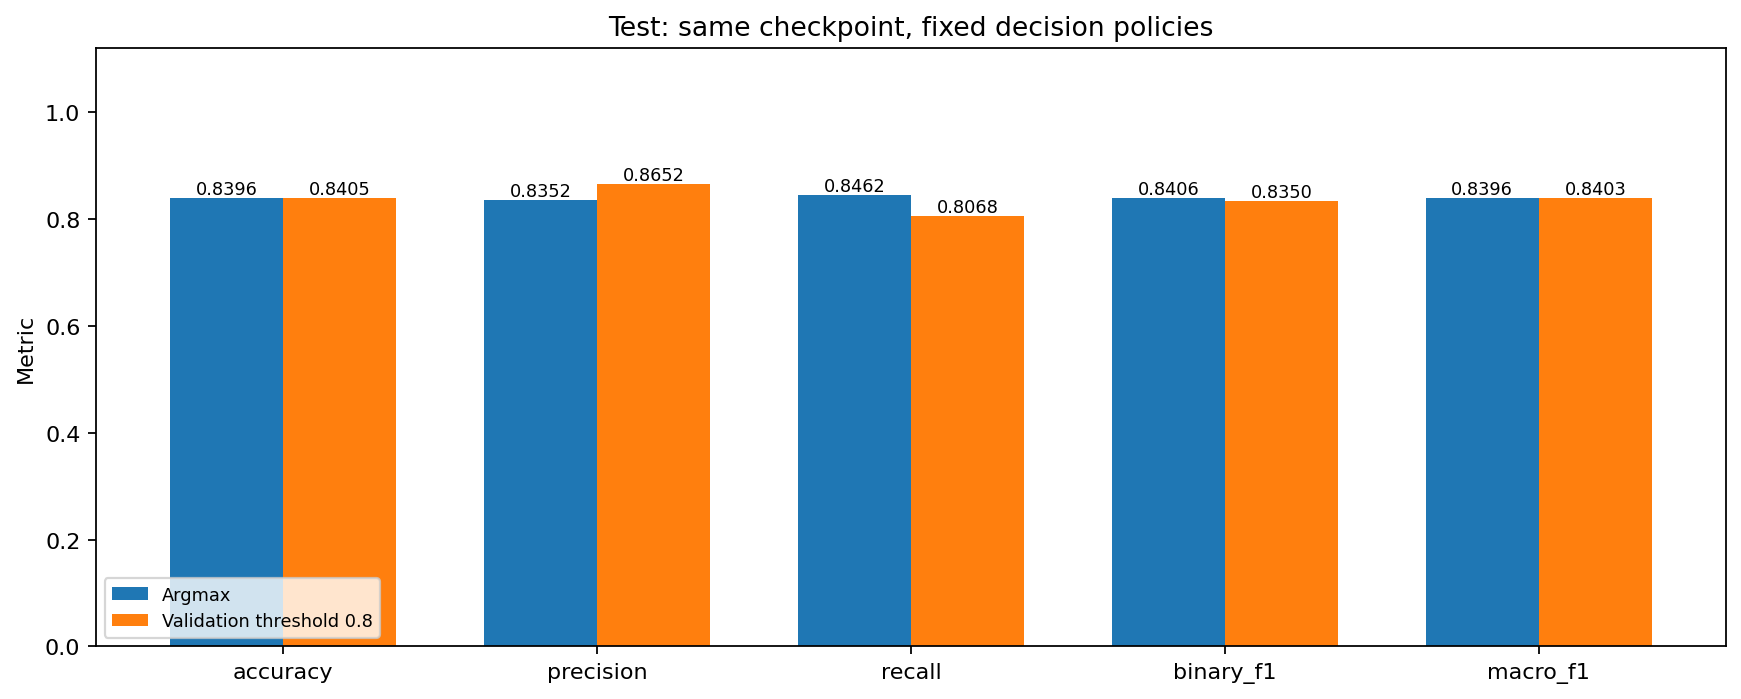

**Hai confusion matrices cùng thang màu và cùng test support**

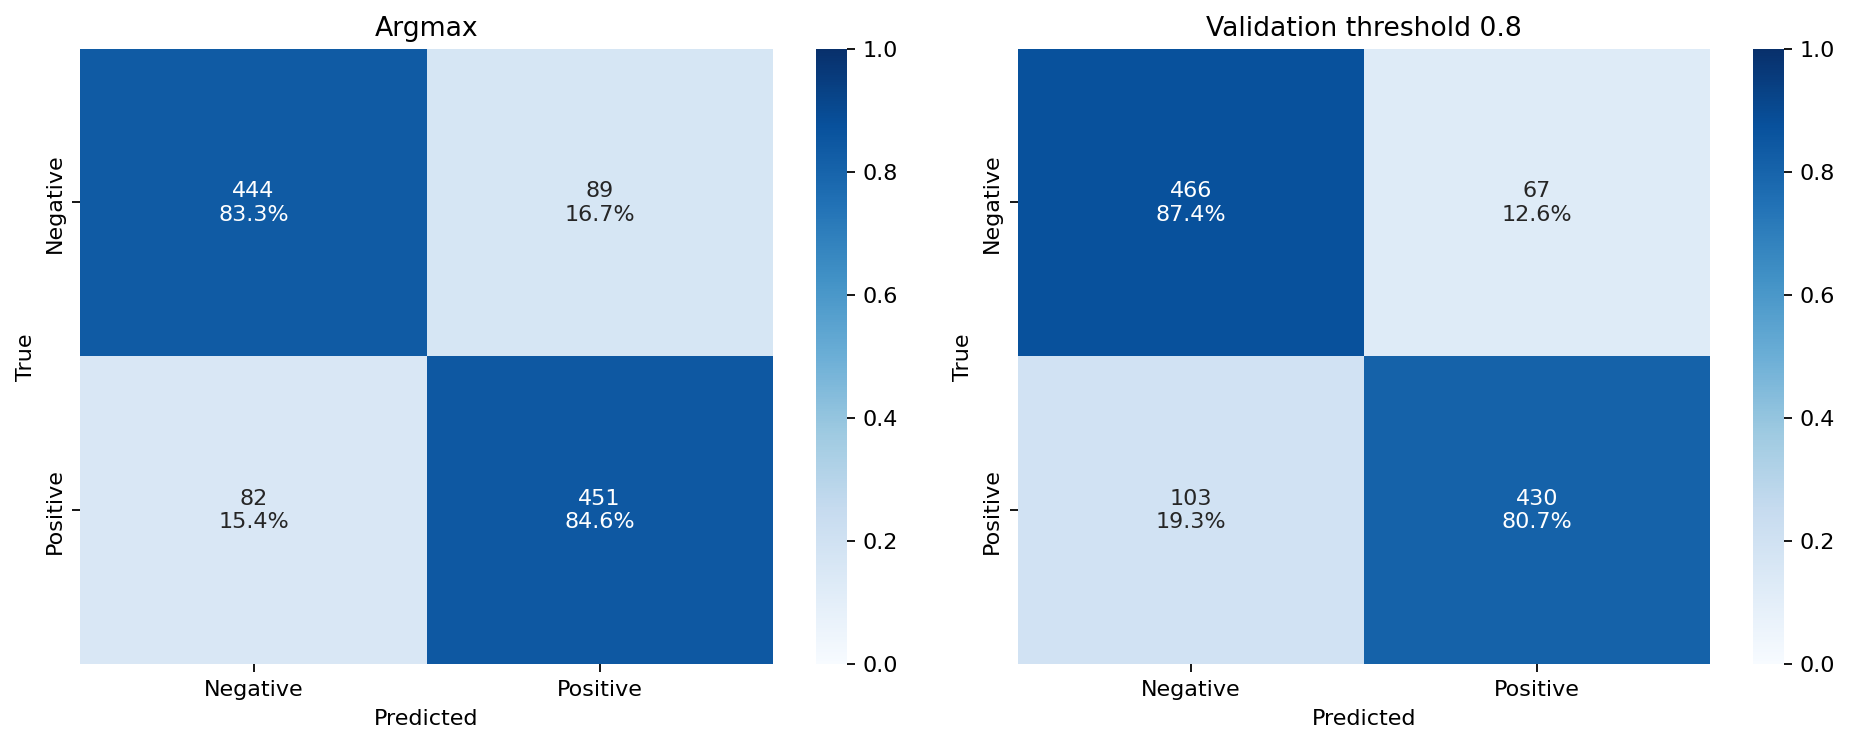

**22 lỗi được sửa, 21 lỗi mới phát sinh: tăng một mẫu đúng**

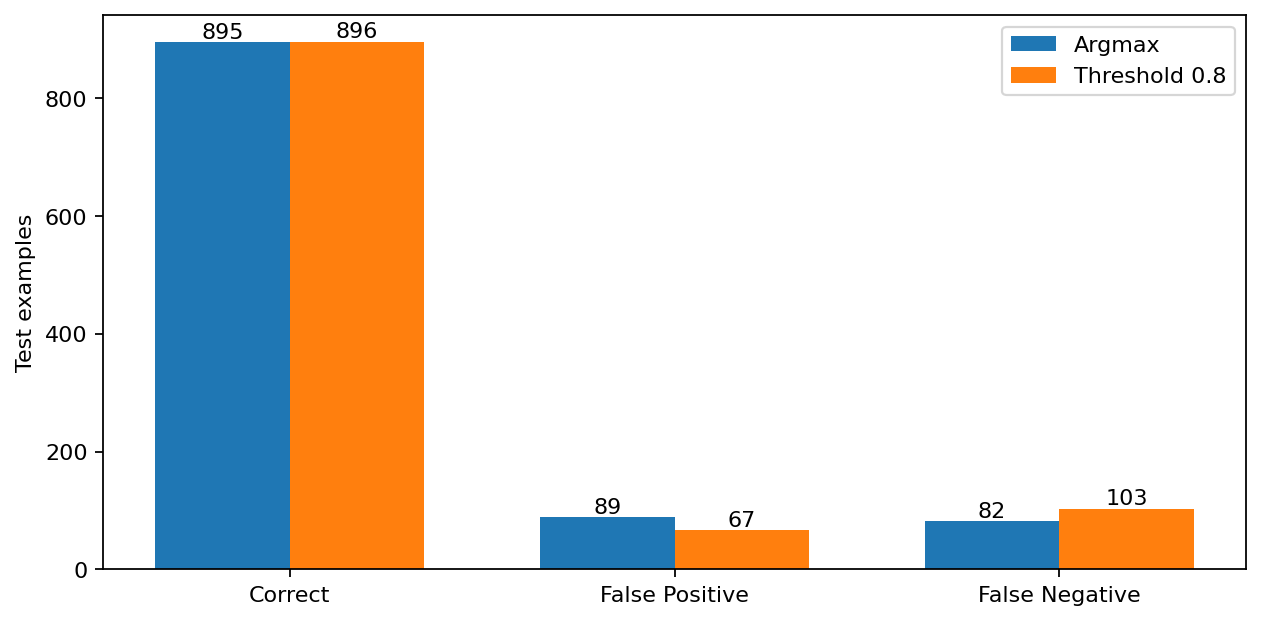

Measured test loss sau reload: 0.5442677736282349


In [13]:
if threshold_analysis_run:
    display(pd.DataFrame(threshold_tables["test_comparison"]))
    show_figure(threshold_analysis_run / "test_comparison.png", "Test metrics của argmax và policy validation đã đóng băng")
    show_figure(threshold_analysis_run / "confusion_comparison.png", "Hai confusion matrices cùng thang màu và cùng test support")
    show_figure(threshold_analysis_run / "error_tradeoff.png", "22 lỗi được sửa, 21 lỗi mới phát sinh: tăng một mẫu đúng")
    print("Measured test loss sau reload:", threshold_summary["test_loss"])

elif analysis_tables.get("training_threshold"):
    own_threshold = analysis_tables["training_threshold"]
    display(pd.DataFrame(own_threshold["test_comparison"]))
    show_figure(analysis_run / "training_threshold_metrics.png", "Run mới: test metrics tại argmax và policy validation của chính run này")
    show_figure(analysis_run / "training_threshold_confusion.png", "Run mới: confusion matrix tại threshold đã cố định")
    print("Measured test loss của run mới:", analysis_summary["measured_test_loss"])


## 2.9. Confusion matrix và metric từng lớp

Confusion matrix dùng hàng là nhãn thật, cột là dự đoán. Với Positive là lớp dương: TP=451, TN=444, FP=89, FN=82 ở run tham chiếu. Accuracy bằng `(TP+TN)/N`; FPR bằng `FP/(FP+TN)`.

Hình có count và tỷ lệ chuẩn hóa theo từng hàng, không chuẩn hóa toàn ma trận. TPR của Negative thấp hơn Positive; số Negative đoán nhầm Positive là 89, lớn hơn 82 ở chiều ngược lại. Bảng one-vs-rest cho từng lớp làm rõ lớp nào dễ bị bỏ sót và lớp nào dễ nhận False Positives.

,label,precision,recall_TPR,F1,FPR,support
0,NEGATIVE,0.844106,0.833021,0.838527,0.153846,533
1,POSITIVE,0.835185,0.846154,0.840634,0.166979,533


**Confusion matrix: số lượng và tỷ lệ theo hàng**

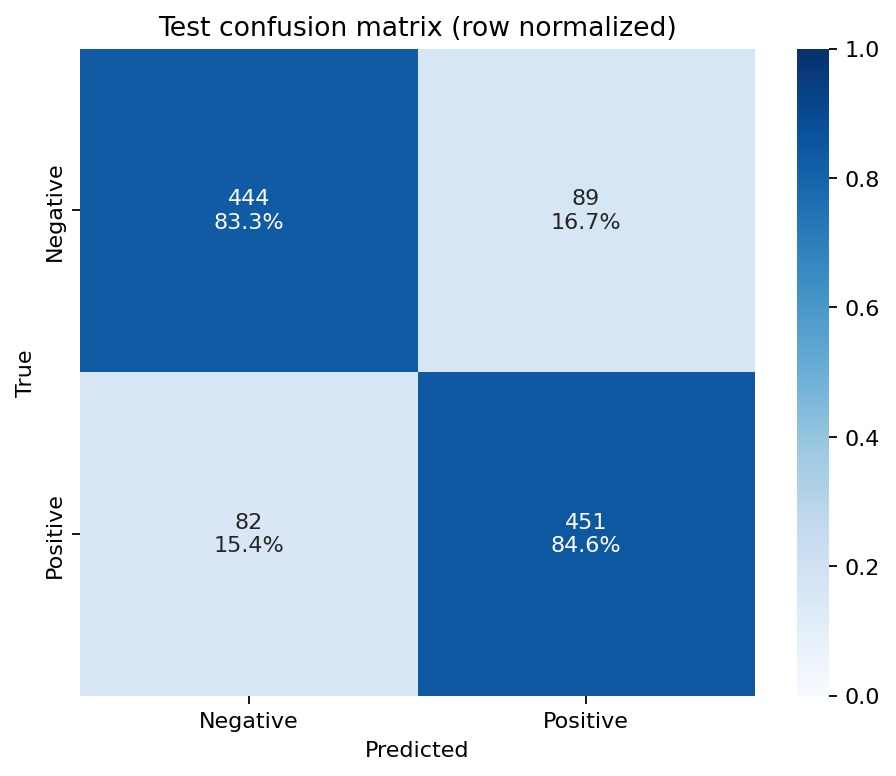

**Precision, Recall/TPR, F1 và FPR từng lớp**

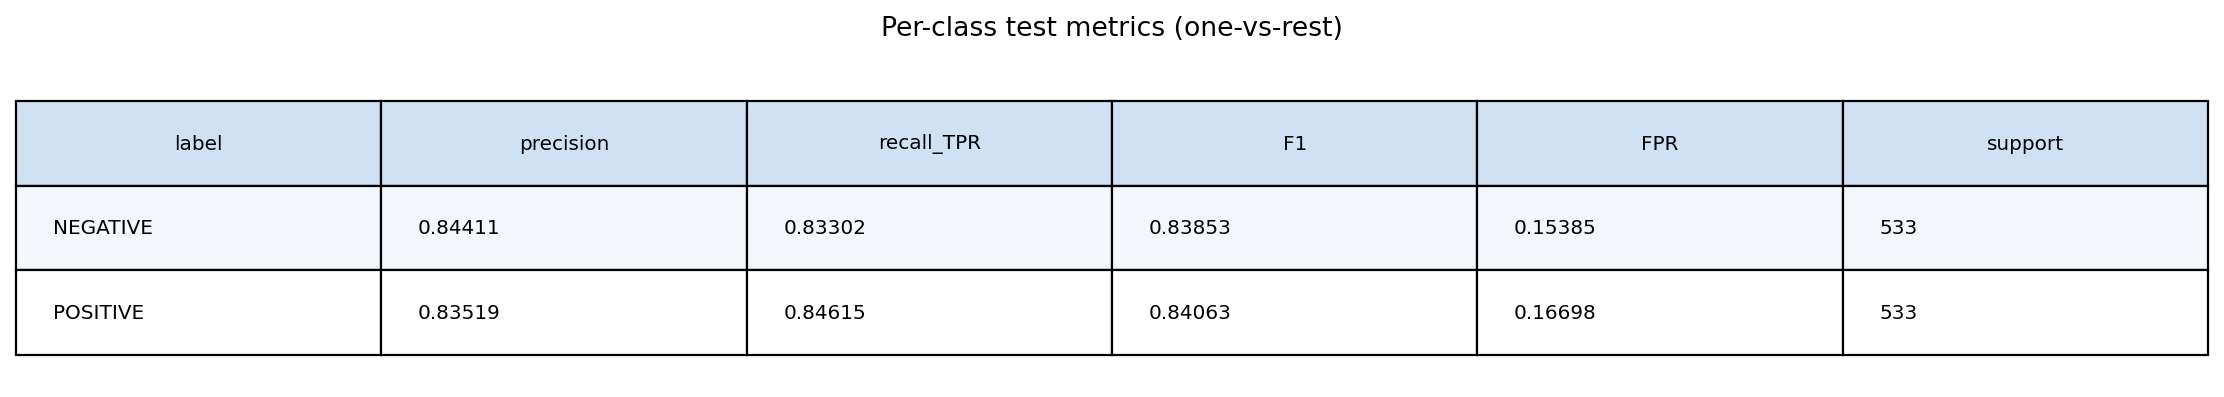

In [14]:
display(pd.DataFrame(analysis_tables["per_class_metrics"]))
show_figure(finetuning_run / "confusion_matrix.png", "Confusion matrix: số lượng và tỷ lệ theo hàng")
show_figure(analysis_run / "per_class_metrics.png", "Precision, Recall/TPR, F1 và FPR từng lớp")

## 2.10. ROC, Precision–Recall và cách hiểu AUC

ROC vẽ TPR theo FPR khi thay threshold. ROC-AUC đo khả năng xếp hạng Positive cao hơn Negative, không phải accuracy tại một threshold. Precision–Recall tập trung vào chất lượng phát hiện Positive; Average Precision tổng hợp precision theo recall, không đồng nhất với ROC-AUC.

Các curve test ở đây là **mô tả** từ xác suất test đã lưu. Không chọn lại checkpoint hoặc threshold bằng cách tìm điểm đẹp nhất trên các curve test.

**Test ROC và Precision–Recall từ probabilities thật**

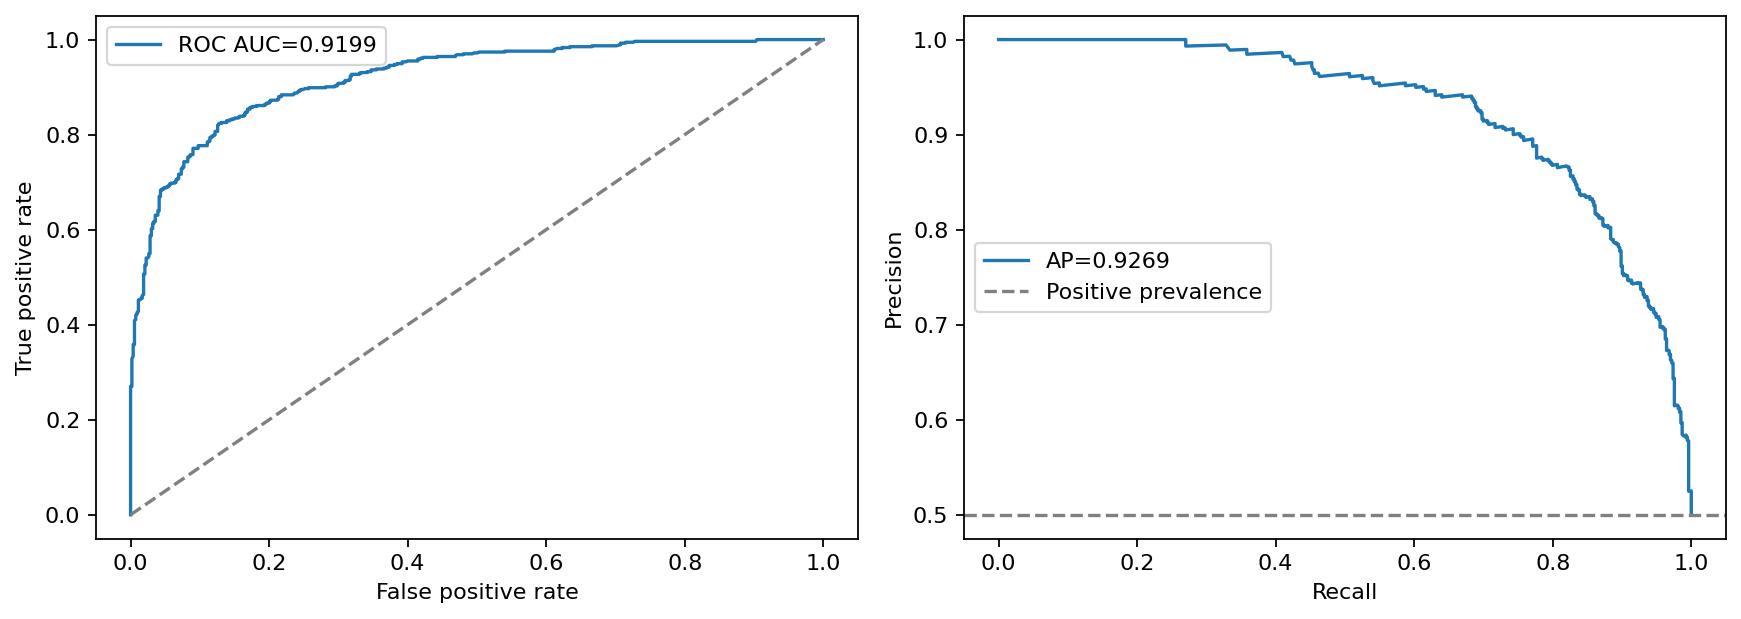

ROC-AUC: 0.9199493820598474
Average Precision: 0.9268528694509572


In [15]:
show_figure(analysis_run / "roc_pr_curves.png", "Test ROC và Precision–Recall từ probabilities thật")
print("ROC-AUC:", analysis_summary["roc_auc"])
print("Average Precision:", analysis_summary["average_precision"])

## 2.11. Confidence, phân bố xác suất và calibration

Hai mô hình có cùng accuracy vẫn có thể đưa ra confidence khác nhau. Reliability diagram so sánh confidence với tỷ lệ đúng trong từng bin; ECE tổng hợp khoảng cách theo trọng số bin. Giá trị ECE phụ thuộc cách chia bin và không phải bảo đảm phổ quát. Brier score đo sai số bình phương của xác suất Positive so với nhãn 0/1.

Biểu đồ xác suất giúp nhìn mức phân tách hai lớp và những dự đoán gần biên. Các lỗi có confidence cao cho thấy tự tin không bảo đảm đúng; chỉ đọc vài ví dụ sai không đủ kết luận calibration, nên cần xem cả biểu đồ và thước đo trên toàn bộ test đã lưu.

**Phân bố xác suất Positive theo nhãn thật**

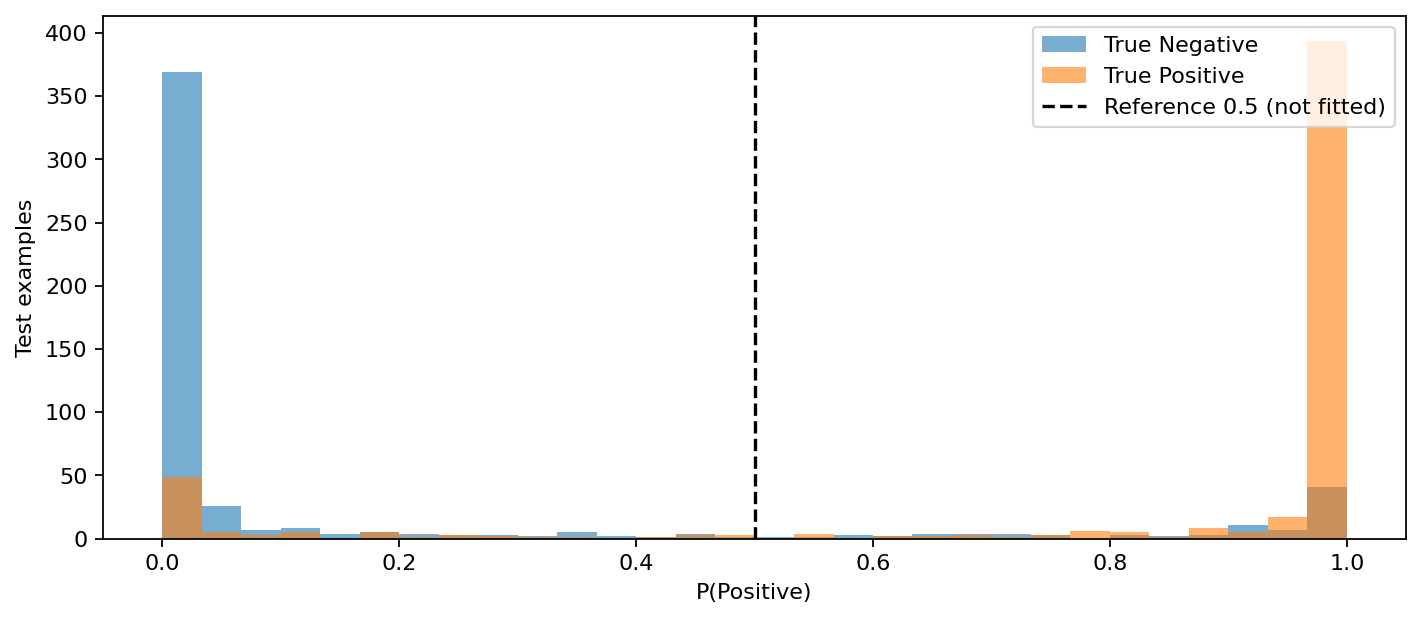

**Reliability / calibration diagnostic trên test**

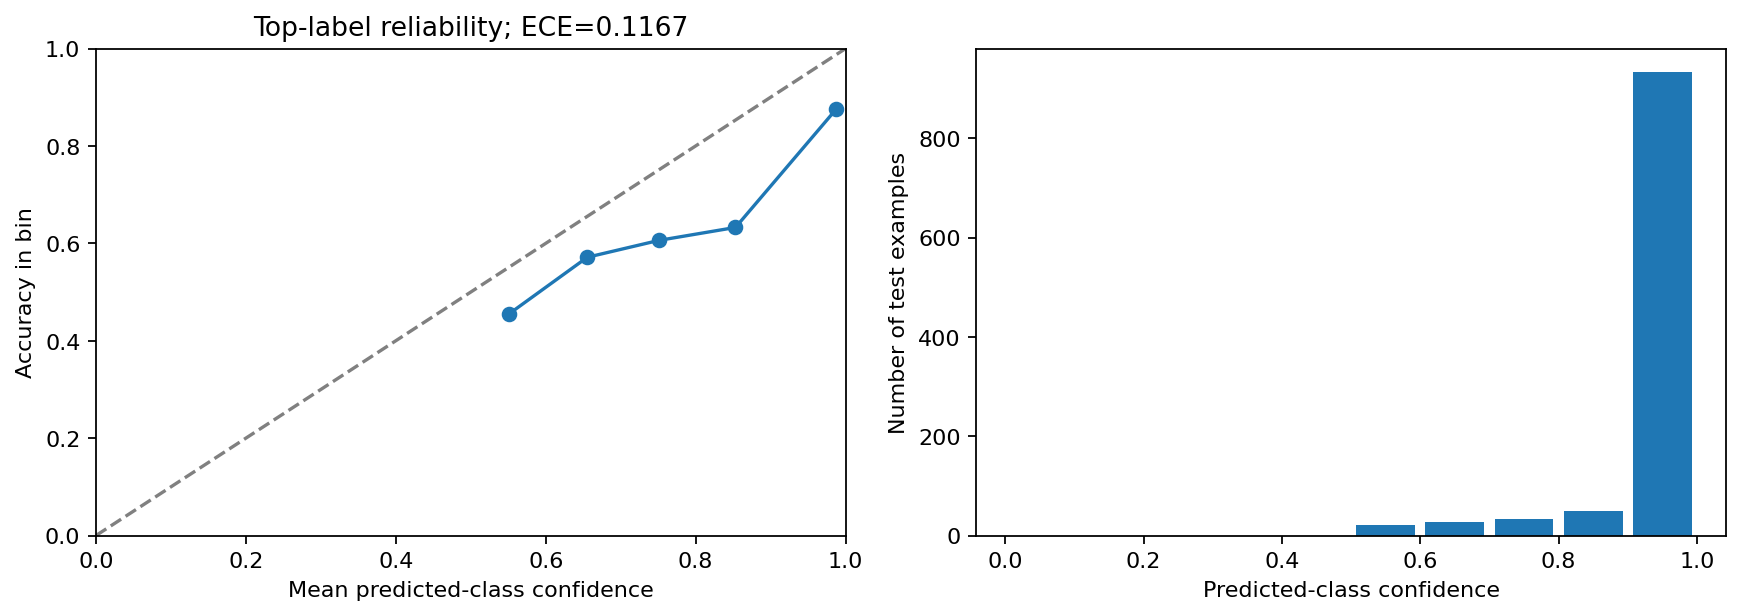

Confidence ECE: 0.11673777216370963
Brier score: 0.13614091824837452


In [16]:
show_figure(analysis_run / "probability_distribution.png", "Phân bố xác suất Positive theo nhãn thật")
show_figure(analysis_run / "calibration_curve.png", "Reliability / calibration diagnostic trên test")
print("Confidence ECE:", analysis_summary["confidence_ece"])
print("Brier score:", analysis_summary["brier_score"])

## 2.12. Phân tích định tính các lỗi

Các mẫu được chọn theo confidence cao của cả nhóm đúng/sai và cả hai nhãn, không phải một mẫu ngẫu nhiên đại diện test. Diễn giải ngôn ngữ dưới đây là giả thuyết, không phải bằng chứng về nguyên nhân bên trong attention hay classifier.

- **Hey Arnold:** “barely feature length” là chê, nhưng “appealing” và lời khen animation có thể làm tín hiệu tích cực lấn át. Điểm khó là trộn hai chiều cảm xúc.
- **Disney:** “entertains … perverse pleasure … scrape the bottom …” mang tính mỉa mai. Một từ như “entertains” không đủ để quyết định sentiment của cả câu.
- **Story is almost an afterthought:** “afterthought”, “inexplicable” có vẻ tiêu cực, nhưng câu được dataset gán Positive trong đánh giá trải nghiệm thị giác. Không tự kết luận nhãn sai chỉ vì câu mơ hồ.
- **The Wild Thornberrys:** “rivalry”, “chaos” mô tả nội dung gia đình, còn “anyone can relate” thể hiện đồng cảm tích cực. Từ vựng cốt truyện khác với thái độ của người nhận xét.

**Ví dụ đúng/sai có confidence cao; xanh đúng, đỏ sai**

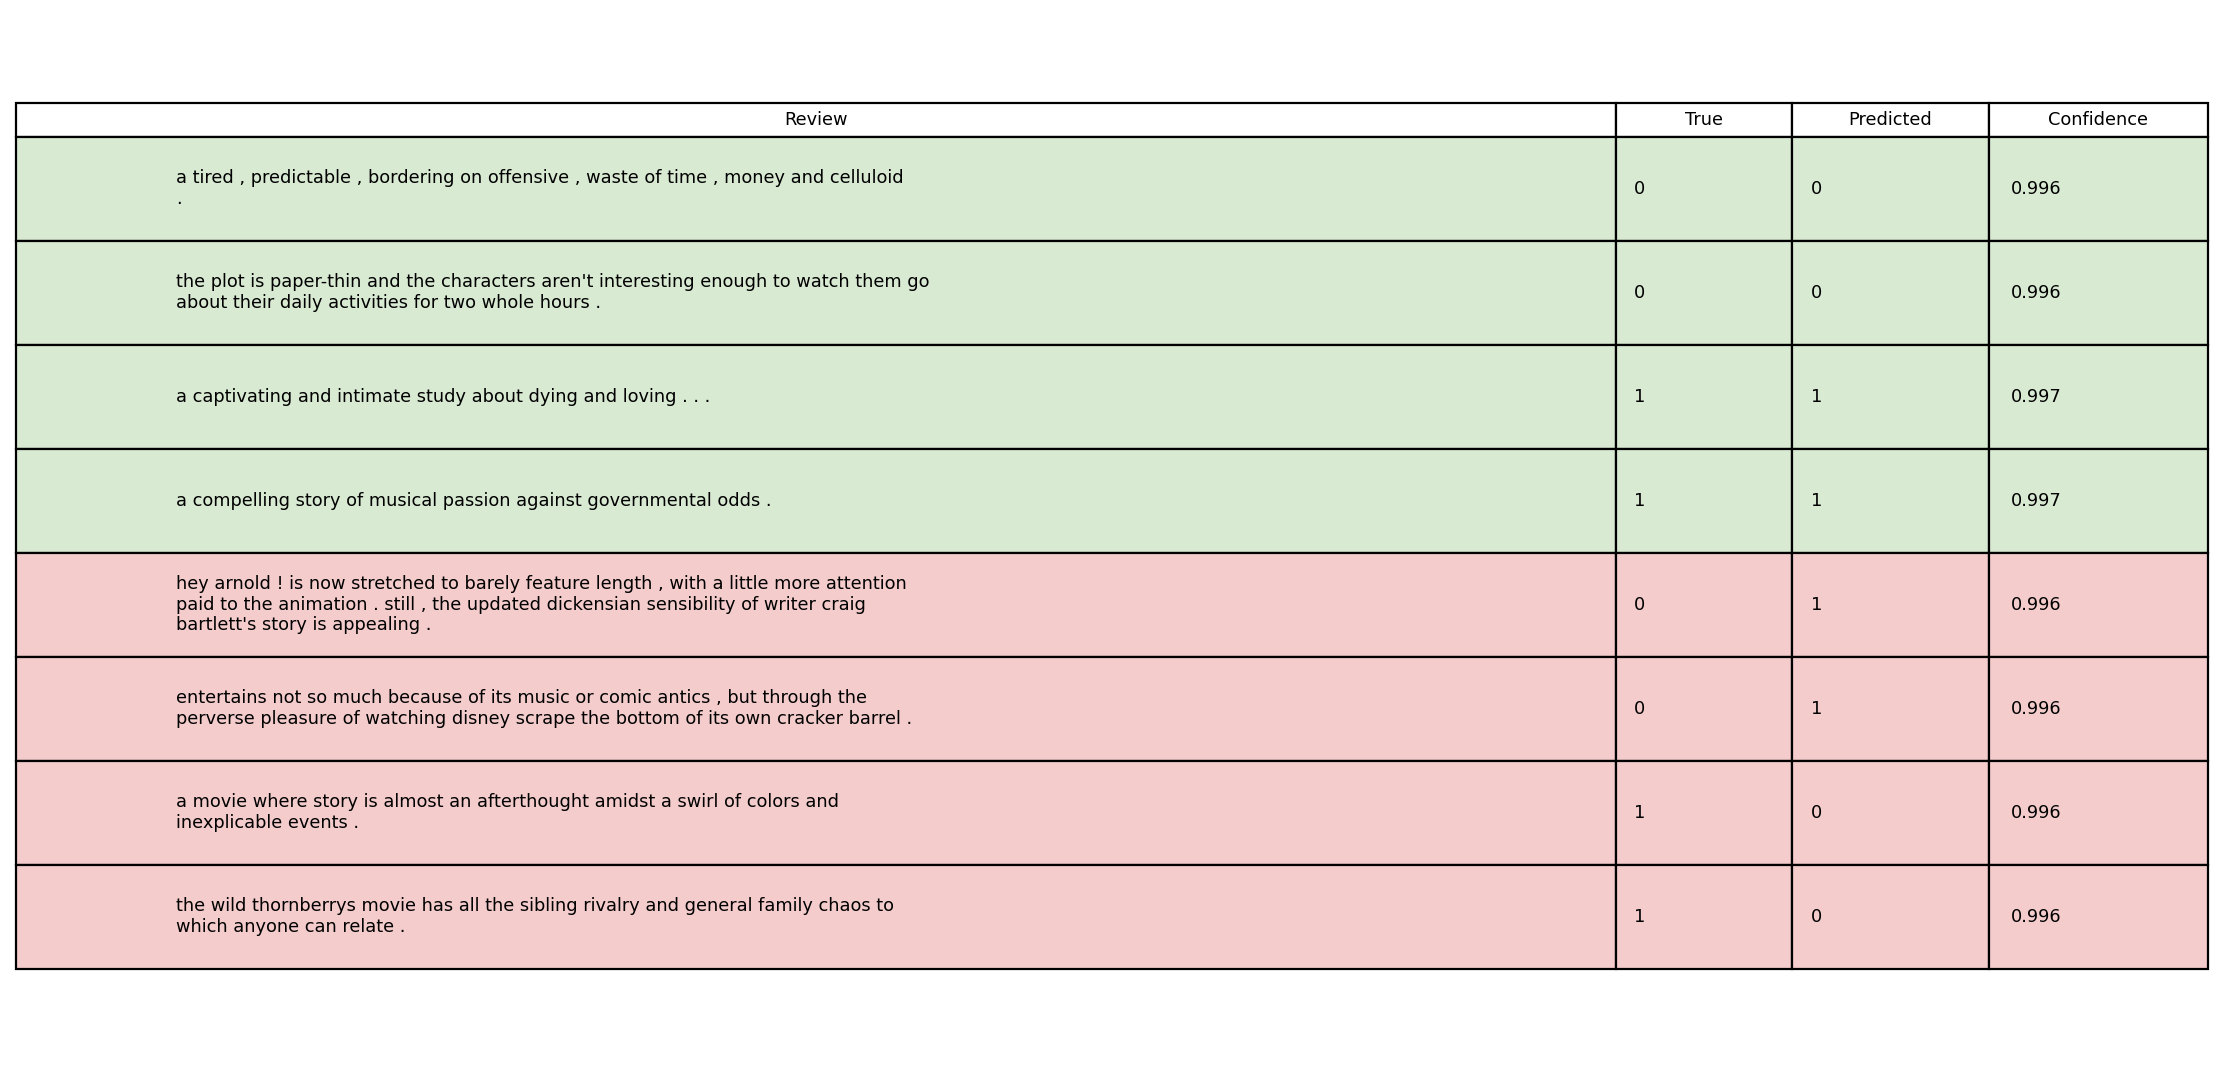

,index,text,true_label,predicted_label,confidence
0,823,"a tired , predictable , bordering on offensive...",0,0,0.996413
1,1017,the plot is paper-thin and the characters aren...,0,0,0.996322
2,85,a captivating and intimate study about dying a...,1,1,0.997054
3,465,a compelling story of musical passion against ...,1,1,0.997025
4,1014,hey arnold ! is now stretched to barely featur...,0,1,0.996078
5,939,entertains not so much because of its music or...,0,1,0.995826
6,219,a movie where story is almost an afterthought ...,1,0,0.995609
7,470,the wild thornberrys movie has all the sibling...,1,0,0.995609


In [17]:
show_figure(finetuning_run / "sample_predictions.png", "Ví dụ đúng/sai có confidence cao; xanh đúng, đỏ sai")
display(pd.DataFrame(read_json(finetuning_run / "sample_predictions.json")))

### Những dự đoán thay đổi và sử dụng policy khi inference

Bảng dưới lấy hai ví dụ thật mỗi nhóm: lỗi được sửa, lỗi mới phát sinh, quyết định không đổi; đây là mẫu minh họa có chủ đích. Khi tăng ngưỡng lên 0,8, các câu có xác suất Positive từ 0,5 đến dưới 0,8 chuyển sang Negative. Model weights không đổi.

Inference bổ sung dùng đúng policy và checkpoint gốc. Câu có hai vế tương phản được gán Negative, xác suất Negative khoảng 0,99333. Một ví dụ không đo được accuracy ngoài phân phối; chỉ chứng minh dòng sử dụng policy và xuất artifact.


,method,label,precision,recall_TPR,F1,FPR,support
0,Argmax,NEGATIVE,0.844106,0.833021,0.838527,0.153846,533
1,Argmax,POSITIVE,0.835185,0.846154,0.840634,0.166979,533
2,Threshold 0.8,NEGATIVE,0.818981,0.874296,0.845735,0.193246,533
3,Threshold 0.8,POSITIVE,0.865191,0.806754,0.834951,0.125704,533


**Precision, Recall/TPR, F1, FPR từng lớp ở hai policy**

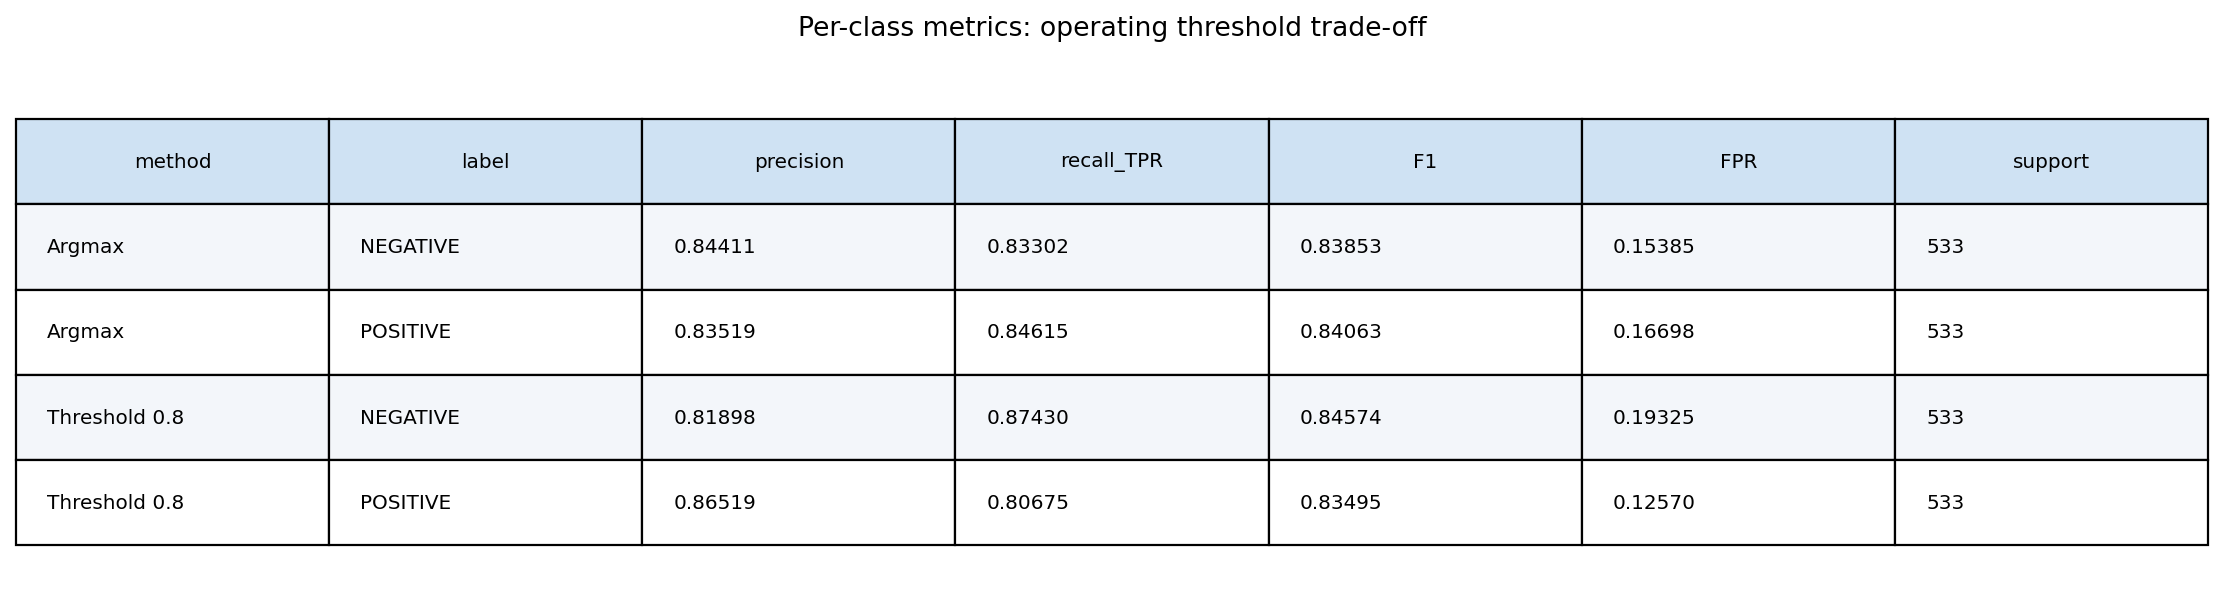

**Ví dụ bị tác động bởi threshold: đọc cả lỗi sửa được và lỗi phát sinh**

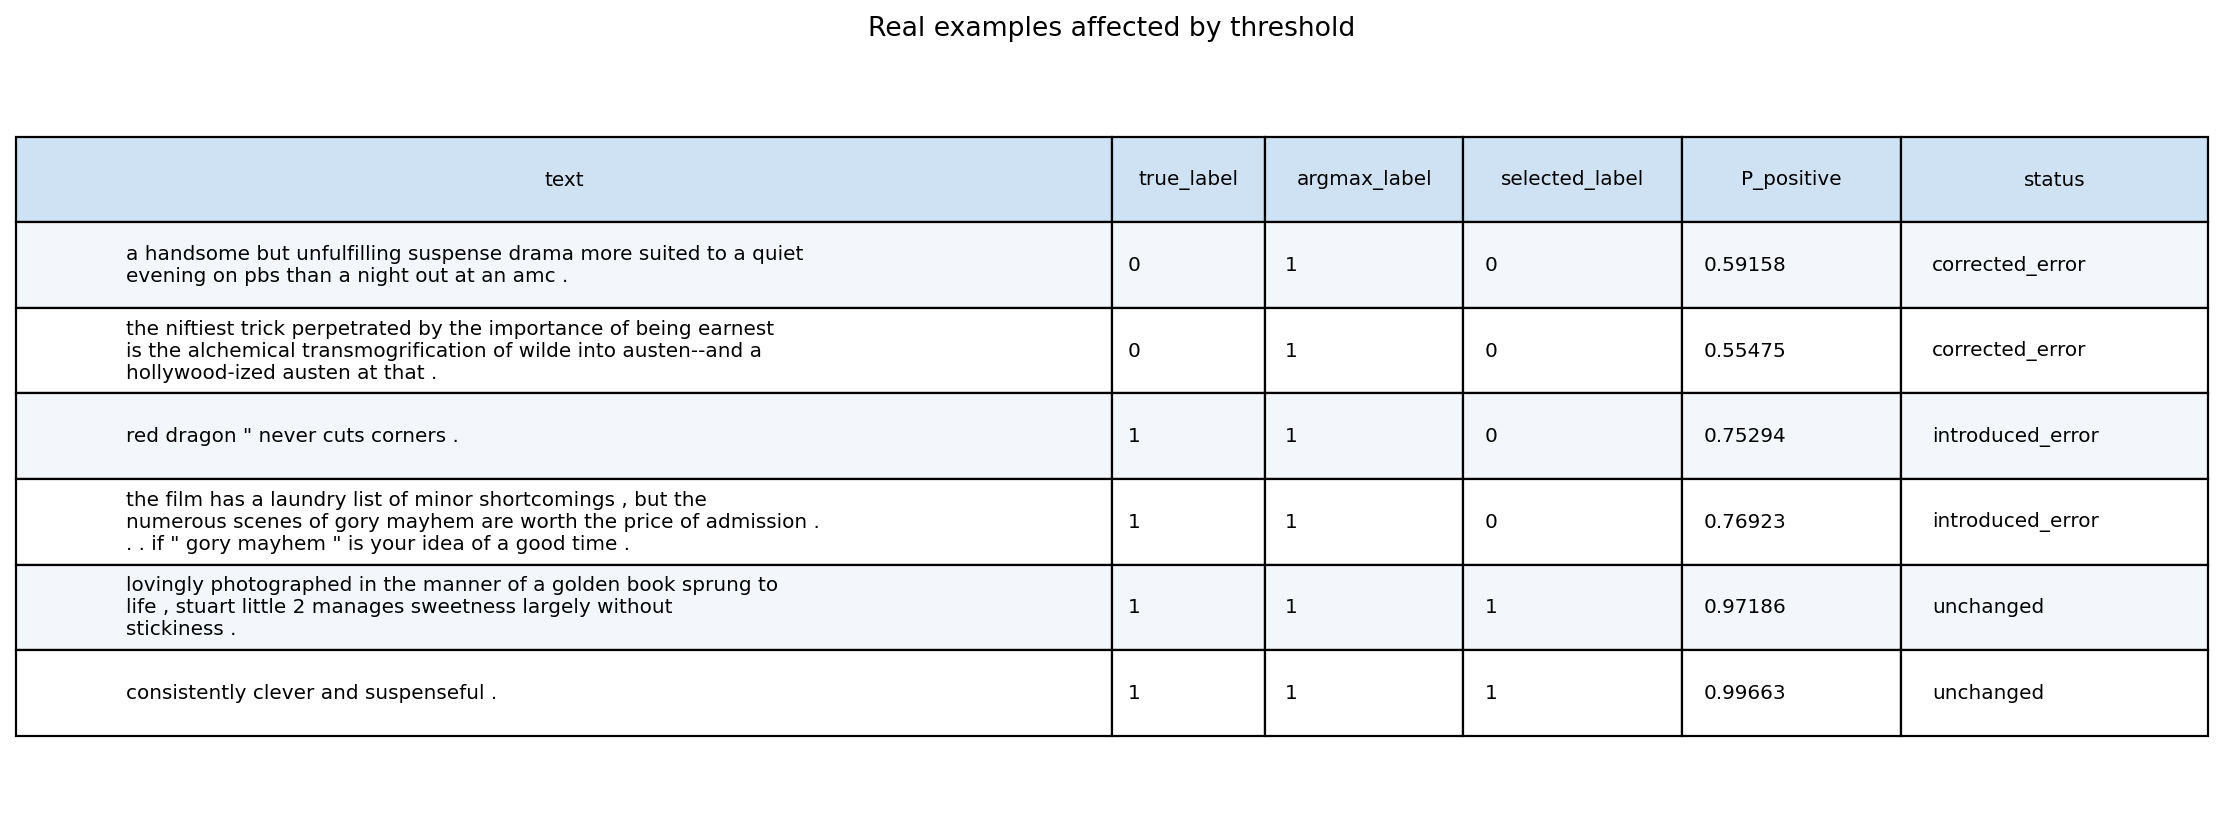

**Hai điểm vận hành trên ROC/PR của cùng probabilities sau reload**

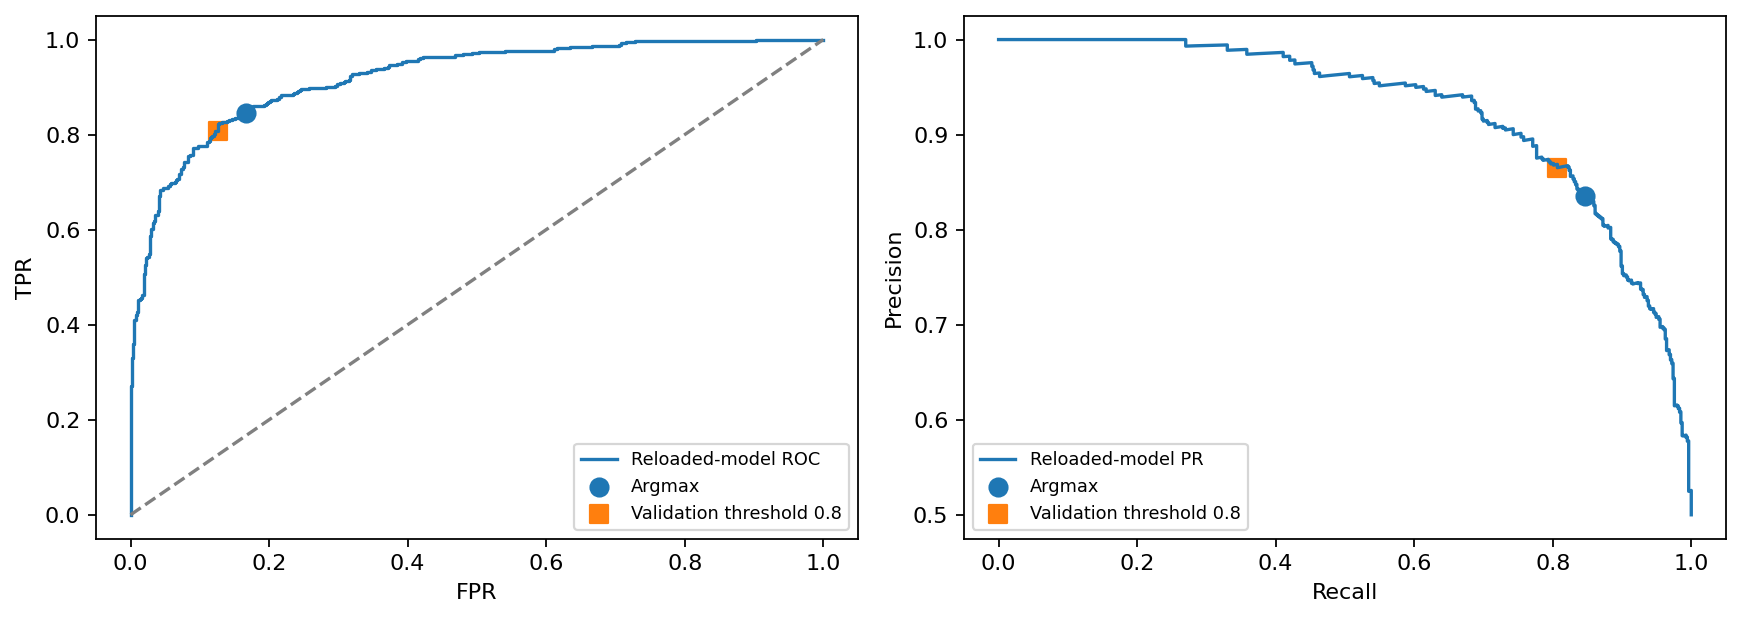

**Inference thật từ checkpoint và policy validation 0,8**

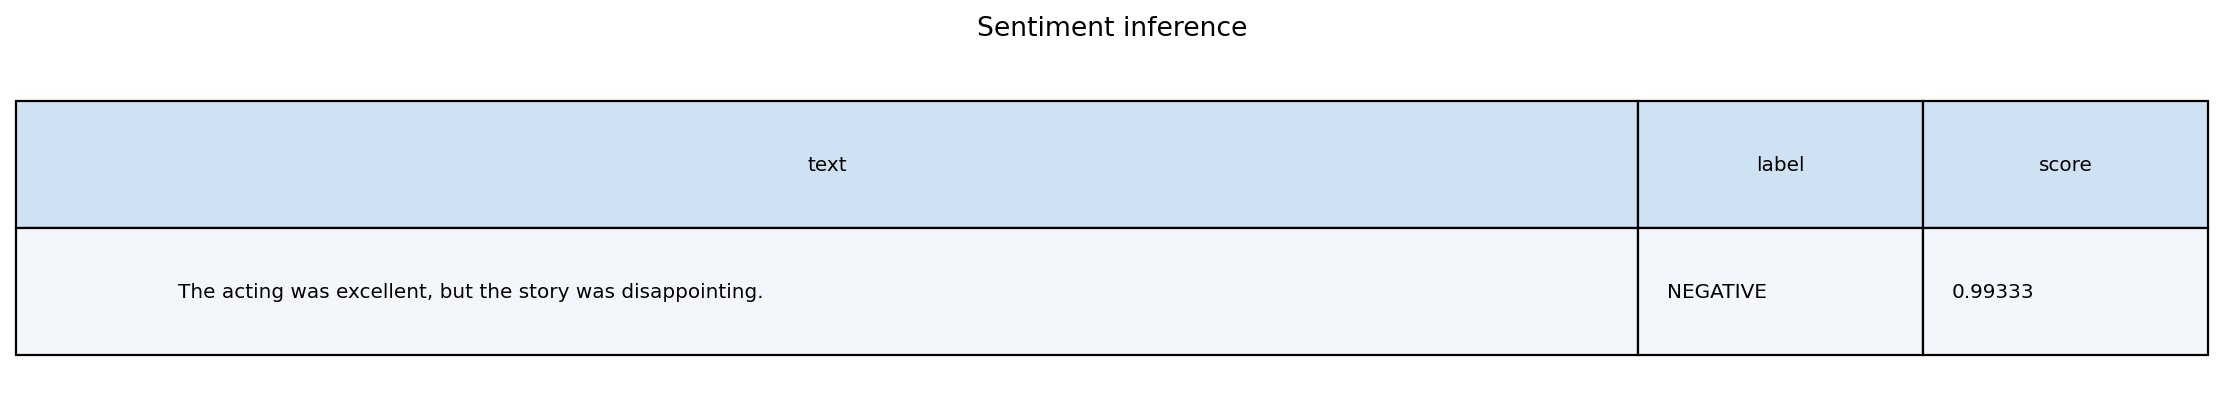

Nguồn run và kết luận đã lưu: /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261026T192102Z_threshold_analysis_40690c71/summary.json


In [18]:
if threshold_analysis_run:
    display(pd.DataFrame(threshold_tables["per_class_comparison"]))
    show_figure(threshold_analysis_run / "per_class_comparison.png", "Precision, Recall/TPR, F1, FPR từng lớp ở hai policy")
    show_figure(threshold_analysis_run / "changed_predictions.png", "Ví dụ bị tác động bởi threshold: đọc cả lỗi sửa được và lỗi phát sinh")
    show_figure(threshold_analysis_run / "operating_points.png", "Hai điểm vận hành trên ROC/PR của cùng probabilities sau reload")
    show_figure(threshold_analysis_run / "inference_result.png", "Inference thật từ checkpoint và policy validation 0,8")
    print("Nguồn run và kết luận đã lưu:", threshold_analysis_run / "summary.json")

elif analysis_tables.get("training_threshold"):
    display(pd.DataFrame(analysis_tables["training_threshold"]["per_class_comparison"]))
    show_figure(analysis_run / "training_threshold_per_class.png", "Run mới: so sánh Precision, Recall/TPR, F1 và FPR từng lớp")
    print("Policy của run mới:", finetuning_run / "decision_threshold.json")
    print("Chạy infer.py với best_model của run này để tạo artifact inference riêng.")


## 2.13. Save/load, artifact và kiểm chứng

Mỗi run có config, môi trường, console log, status, metadata và SHA256 manifest. Kaggle đã lưu checkpoint tốt nhất và ghi `reload_check.json`: trọng số khớp chính xác, forward đối chiếu trong cùng CPU FP32. GitHub không giữ trọng số lớn; notebook view chỉ đọc bằng chứng đã lưu, không tải lại model lần nữa.

Audit độc lập kiểm tra hash của file hiện có, 1.066 index test, phân bố nhãn 533/533, probability hợp lệ, nhãn argmax và tính lại bảy metrics. SHA256 chứng minh bytes giữ nguyên so với manifest, không chứng minh một thí nghiệm đúng về khoa học. Training run kiểm tra weights/save-load; evaluation run tải lại checkpoint trên Kaggle và đánh giá đủ test. Measured test loss là 0,5442677736; loss phụ thuộc probabilities, không phụ thuộc ngưỡng quyết định. Bản audit training/evaluation/inference kiểm tra 46 file nguồn hiện có và tính lại loss gần khớp từ probabilities với tolerance số học.

Tất cả hình mới được lưu trong run phân tích và tất cả bảng có file nguồn JSON. Không dùng một hình chỉ nằm tạm trong notebook làm bằng chứng duy nhất.

In [19]:
display(pd.DataFrame(analysis_tables["artifact_catalog"]))
print("Bằng chứng reload đã chạy trên Kaggle:")
display(read_json(finetuning_run / "reload_check.json"))
print("Tóm tắt phân tích đã lưu:", analysis_run / "analysis_summary.json")
print("Bảng đã lưu:", analysis_run / "tables.json")

,file,source_run
0,confusion_matrix.png,20261026T155822Z_finetuning_2c2f0401
1,learning_curves.png,20261026T155822Z_finetuning_2c2f0401
2,metrics_bar.png,20261026T155822Z_finetuning_2c2f0401
3,sample_predictions.png,20261026T155822Z_finetuning_2c2f0401
4,token_length_distribution.png,20261026T155822Z_finetuning_2c2f0401


Bằng chứng reload đã chạy trên Kaggle:


{'weights_exact_match': True,
 'execution': 'CPU FP32, clean forward methods',
 'predictions': [{'text': 'lovingly photographed in the manner of a golden book sprung to life , stuart little 2 manages sweetness largely without stickiness .',
   'label': 'POSITIVE',
   'score': 0.9718583226203918,
   'probabilities': [0.02814166434109211, 0.9718583226203918]}]}

Tóm tắt phân tích đã lưu: /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261026T192100Z_analysis_388b4fff/analysis_summary.json
Bảng đã lưu: /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261026T192100Z_analysis_388b4fff/tables.json


## 2.14. Kết luận và câu hỏi tự kiểm tra

Run Kaggle tham chiếu đạt Accuracy **83,96%**, Binary F1 **84,06%** và Macro F1 **83,96%**, đúng 895/1.066 mẫu. Đề không đặt ngưỡng 85%; yêu cầu quan trọng là thực hiện đúng quy trình và diễn giải trung thực. Đã thấy dấu hiệu overfitting nên không kết luận train càng lâu càng tốt.

1. Vì sao epoch 3 được chọn dù epoch 2 có validation loss thấp hơn?
2. Vì sao không chọn threshold có test F1 cao nhất từ đường diagnostic?
3. Vì sao ROC-AUC, Average Precision và Accuracy có thể khác nhau?
4. Vì sao Binary F1 và Macro F1 không hoàn toàn giống nhau?
5. Vì sao confidence gần 1 vẫn có thể sai?
6. File nào cho phép tính lại metrics và file nào cần để chạy inference thật?
7. Khi MODE=view có hình mới, chúng được lưu ở đâu và có thay raw run không?

Các giới hạn còn lại: dataset revision đã pin SHA; chưa có audit duplicate toàn bộ splits trong artifacts lịch sử; checkpoint lưu ngoài Git. Validation threshold selection và full-test reload đã có bằng chứng riêng; không đồng nhất chúng với training run lịch sử. Không biến các mục chưa thực thi thành kết quả đã đạt.

Policy 0,8 đạt test Accuracy **84,0525%**, Macro F1 **84,0343%**, Binary F1 **83,4951%**. FP giảm 89 xuống 67, FN tăng 82 lên 103. Chỉ thêm một mẫu đúng không đủ kết luận cải thiện đáng kể; Macro F1 validation là mục tiêu selection đã định trước, không đổi mục tiêu sau khi thấy test. Vì sao tăng threshold có thể tăng Precision nhưng giảm Recall và Binary F1?


## Artifact dùng cho report

Hình và bảng đã hiển thị tại từng phase được lưu dưới `outputs/`. Bộ `outputs/published/` giữ bản xuất từ những run chọn tại `config/report.json`: có bảng metrics, toàn bộ PNG và provenance. Dùng `scripts/publish_artifacts.py` khi cần xuất lại; không tải model, train hoặc dựng lại đồ thị cho thao tác này.


In [20]:
published = LAB / "outputs/published"
if (published / "metrics_summary.json").is_file():
    display(pd.DataFrame(read_json(published / "metrics_summary.json").get("historical_three_epoch_test_comparison", read_json(published / "metrics_summary.json")["test_comparison"])))
    print("Bộ hình và bảng cho report:", published / "index.md")
    print("Nguồn run:", published / "source_runs.json")
else:
    print("Chọn run trong config/report.json và chạy scripts/publish_artifacts.py.")


,policy,accuracy,precision,recall,binary_f1,macro_f1,test_loss
0,Argmax,0.839587,0.835185,0.846154,0.840634,0.839580,0.544268
1,Validation threshold 0.8,0.840525,0.865191,0.806754,0.834951,0.840343,0.544268


Bộ hình và bảng cho report: /workspace/Lab-DL-completion/labs/lab03/outputs/published/index.md
Nguồn run: /workspace/Lab-DL-completion/labs/lab03/outputs/published/source_runs.json


# Phiên mở rộng — Study 10 epoch đã chạy thật

Phần sau trình bày đủ kết quả study mới, tách biệt với lịch sử phía trên.

# Lab03 — Kết quả Kaggle: ba cấu hình, mỗi cấu hình đủ 10 epoch

Đây là notebook trình bày **kết quả đã chạy thật**, không phải template training. Chạy **Run All** ở `MODE="view"` để đọc artifacts offline, không tải model/dataset, không cần GPU. Training nằm trong [04_kaggle_10epoch_study.ipynb](04_kaggle_10epoch_study.ipynb).

Study: `20261026T184219Z_study_94f2ba7b`, nguồn code `ca58b27`. Đã kiểm tra 128 file của review ZIP khớp SHA256 và toàn bộ hash source khớp phiên chạy. Cả ba candidate hoàn tất 10 epoch; checkpoint winner là **LR=3e-5, step 1700, epoch ≈3,184**, threshold validation **0,5**. Test đúng **889/1.066**, Accuracy **83,3959%**, Macro-F1 **83,3952%**.

**Kết luận cần giữ đúng:** study hơn baseline TF-IDF nhưng không hơn kết quả lịch sử 3 epoch trên cùng test. Không chọn lại candidate hay threshold theo test. Hoàn thành 10 epoch không có nghĩa lấy weights epoch 10.

## Roadmap phase và module tham chiếu

| Phase | Câu hỏi | Module / file | Evidence và visualize |
|---|---|---|---|
| P0 | Có đúng code và đúng dữ liệu đã chạy không? | [study_evidence.py](../src/study_evidence.py), [runs.py](../src/utils/runs.py) | SHA256, fingerprints, source revision |
| P1 | Pretrained sentiment vận hành thế nào? | [classifier.py](../src/models/classifier.py), [analysis.py](../src/analysis.py) | token heatmap, probabilities, pipeline/manual |
| P2 | Dữ liệu có cân bằng, trùng nội dung hay bị cắt không? | [loader.py](../src/datasets/loader.py), [study.py](../src/study.py) | class counts, token histogram, overlap audit |
| P3 | Baseline học thật đạt mức nào? | [study.py](../src/study.py): fit_text_baseline | C validation table, TF-IDF test comparison |
| P4 | Model học thế nào trong 10 epoch? | [trainer.py](../src/training/trainer.py), [plots.py](../src/utils/plots.py) | 3 epoch curves + 3 step dashboards |
| P5 | Checkpoint nào thắng và vì sao? | [study.py](../src/study.py): choose_candidate | candidate table, Macro-F1/loss trajectories |
| P6 | Threshold có cần khác 0,5 không? | [thresholds.py](../src/training/thresholds.py) | validation sweep và frozen policy |
| P7 | Chất lượng trên test và từng lớp? | [workflow.py](../src/workflow.py), [study_evidence.py](../src/study_evidence.py) | metrics, confusion matrices, per-class table |
| P8 | Ranking, confidence và bất định? | [study.py](../src/study.py): prediction_diagnostics | ROC/PR, reliability, bootstrap CI |
| P9 | Có tốt hơn run cũ không? | [study_review.py](../src/study_review.py) | paired test comparison, overfitting diagnostics |
| P10 | Mô hình sai ở đâu, inference dùng policy gì? | [study.py](../src/study.py), [decision.py](../src/decision.py) | error samples, inference table và PNG |
| P11 | Lấy artifact viết report ra sao? | [publish_artifacts.py](../scripts/publish_artifacts.py) | outputs/published/, tables.json, review_summary.json |

Tham chiếu [description](../description_lab_03.md), [walkthrough](../walkthrough_lab_03.md), [DL training](../../../docs/dl_training.md). Các ảnh hiển thị chính là PNG đã lưu dưới `outputs/`; bảng có records nguồn, không dựng lại bằng suy đoán.

In [21]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown

LAB = next((p / "labs/lab03" if (p / "labs/lab03/src/workflow.py").is_file() else p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "labs/lab03/src/workflow.py").is_file() or (p / "src/workflow.py").is_file()), None)
assert LAB is not None, "Hãy mở notebook bên trong repository Lab-DL."
sys.path.insert(0, str(LAB.parents[1]))
from labs.lab03.src.evidence import selected_run, read_json
from labs.lab03.src.study_evidence import audit_study
from labs.lab03.src.study_review import ensure_study_review
from labs.lab03.src.epoch_presentation import ensure_epoch_presentation
SHOW_STEP_DIAGNOSTICS = False

study_run = selected_run("study", root=LAB)
study_audit = audit_study(study_run, root=LAB)
study_review = ensure_study_review(study_run, root=LAB)
epoch_presentation = ensure_epoch_presentation(study_run, root=LAB)
study_tables = read_json(study_review / "tables.json")
study_summary = read_json(study_review / "review_summary.json")
print("Study:", study_run.name, "Audit:", study_audit["status"])
print("Không train, không tải weights, không chọn lại threshold.")

def show_study_image(path, caption):
    path = Path(path)
    assert path.is_file(), f"Thiếu artifact: {path}"
    display(Markdown(caption))
    display(Image(filename=str(path)))

Study: 20261026T184219Z_study_94f2ba7b Audit: passed
Không train, không tải weights, không chọn lại threshold.


## P1 — Exercise 1: tokenizer, pipeline và manual forward

Mô hình SST-2 pretrained chỉ phục vụ Exercise 1. Exercise 2 dùng DistilBERT base với classification head mới, không lấy model đã fine-tune SST-2 để giả thành huấn luyện từ base. Pipeline và manual softmax được đối chiếu trên cùng input/model; không có học weights ở phase này.

,text,label,score,probabilities
0,I love this wonderful movie!,POSITIVE,0.999878,"[0.0001224386360263452, 0.9998775720596313]"
1,This movie was terrible and boring.,NEGATIVE,0.999768,"[0.9997683167457581, 0.00023167315521277487]"
2,"The acting was good, but the story was disappo...",NEGATIVE,0.996749,"[0.9967492818832397, 0.0032507420983165503]"


**Exercise 1 — pipeline_manual_comparison.png**

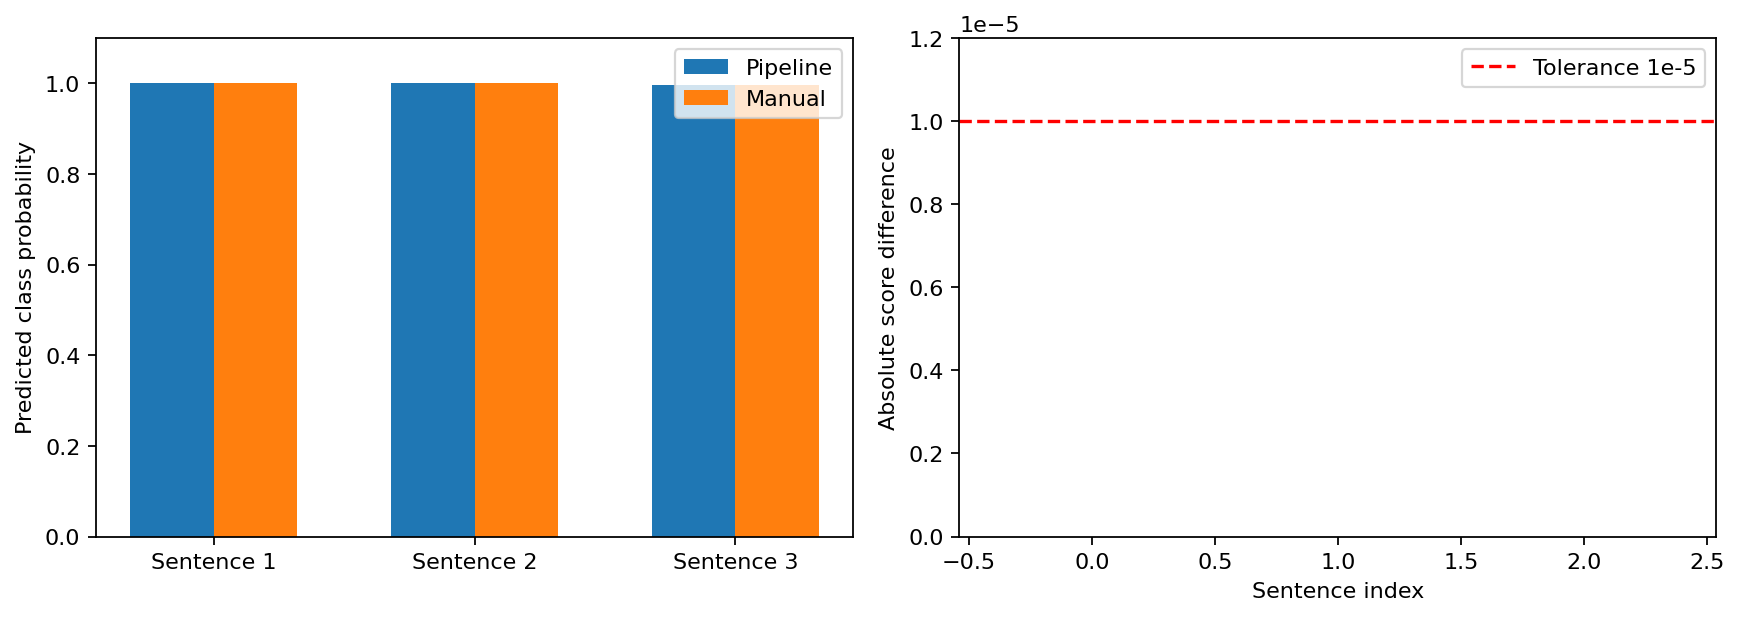

**Exercise 1 — sentiment_predictions.png**

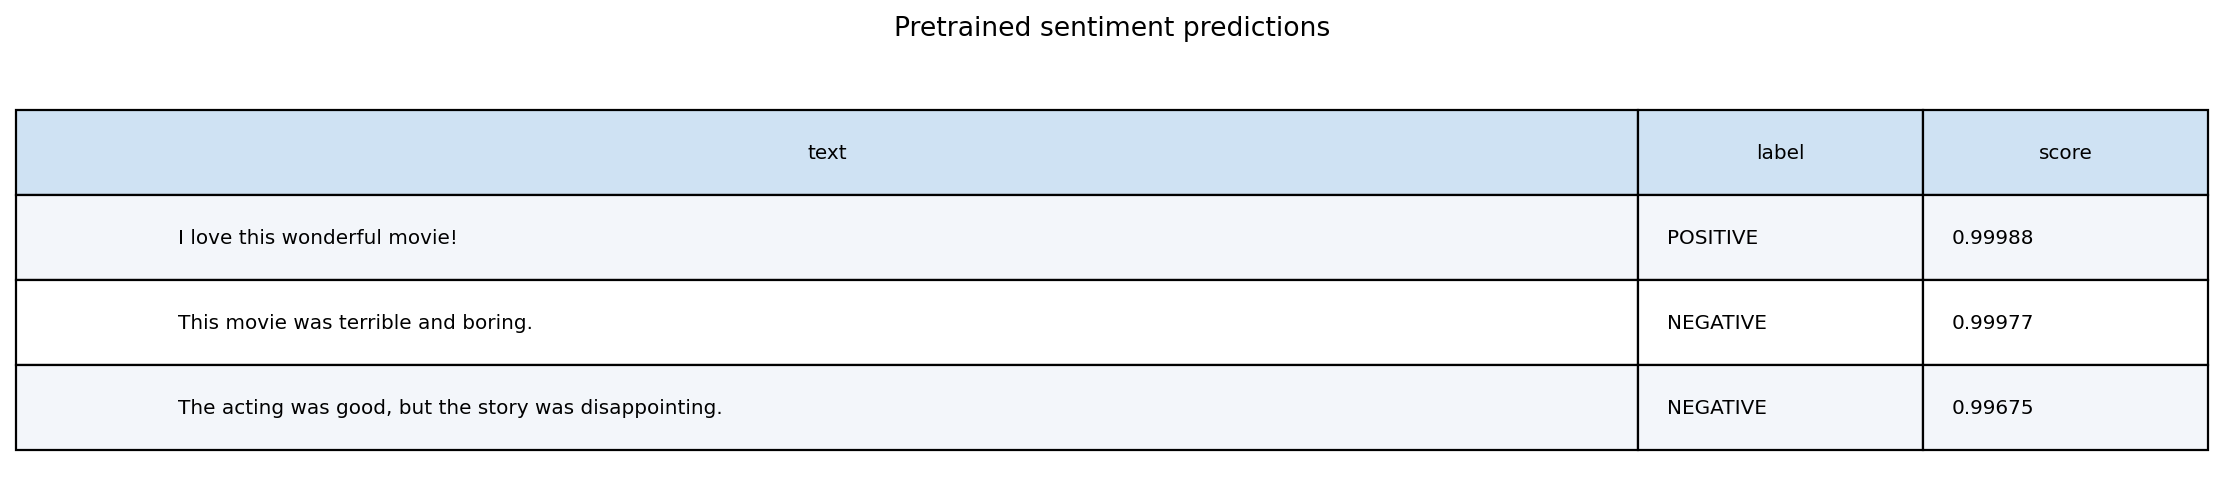

**Exercise 1 — tokenizer_table.png**

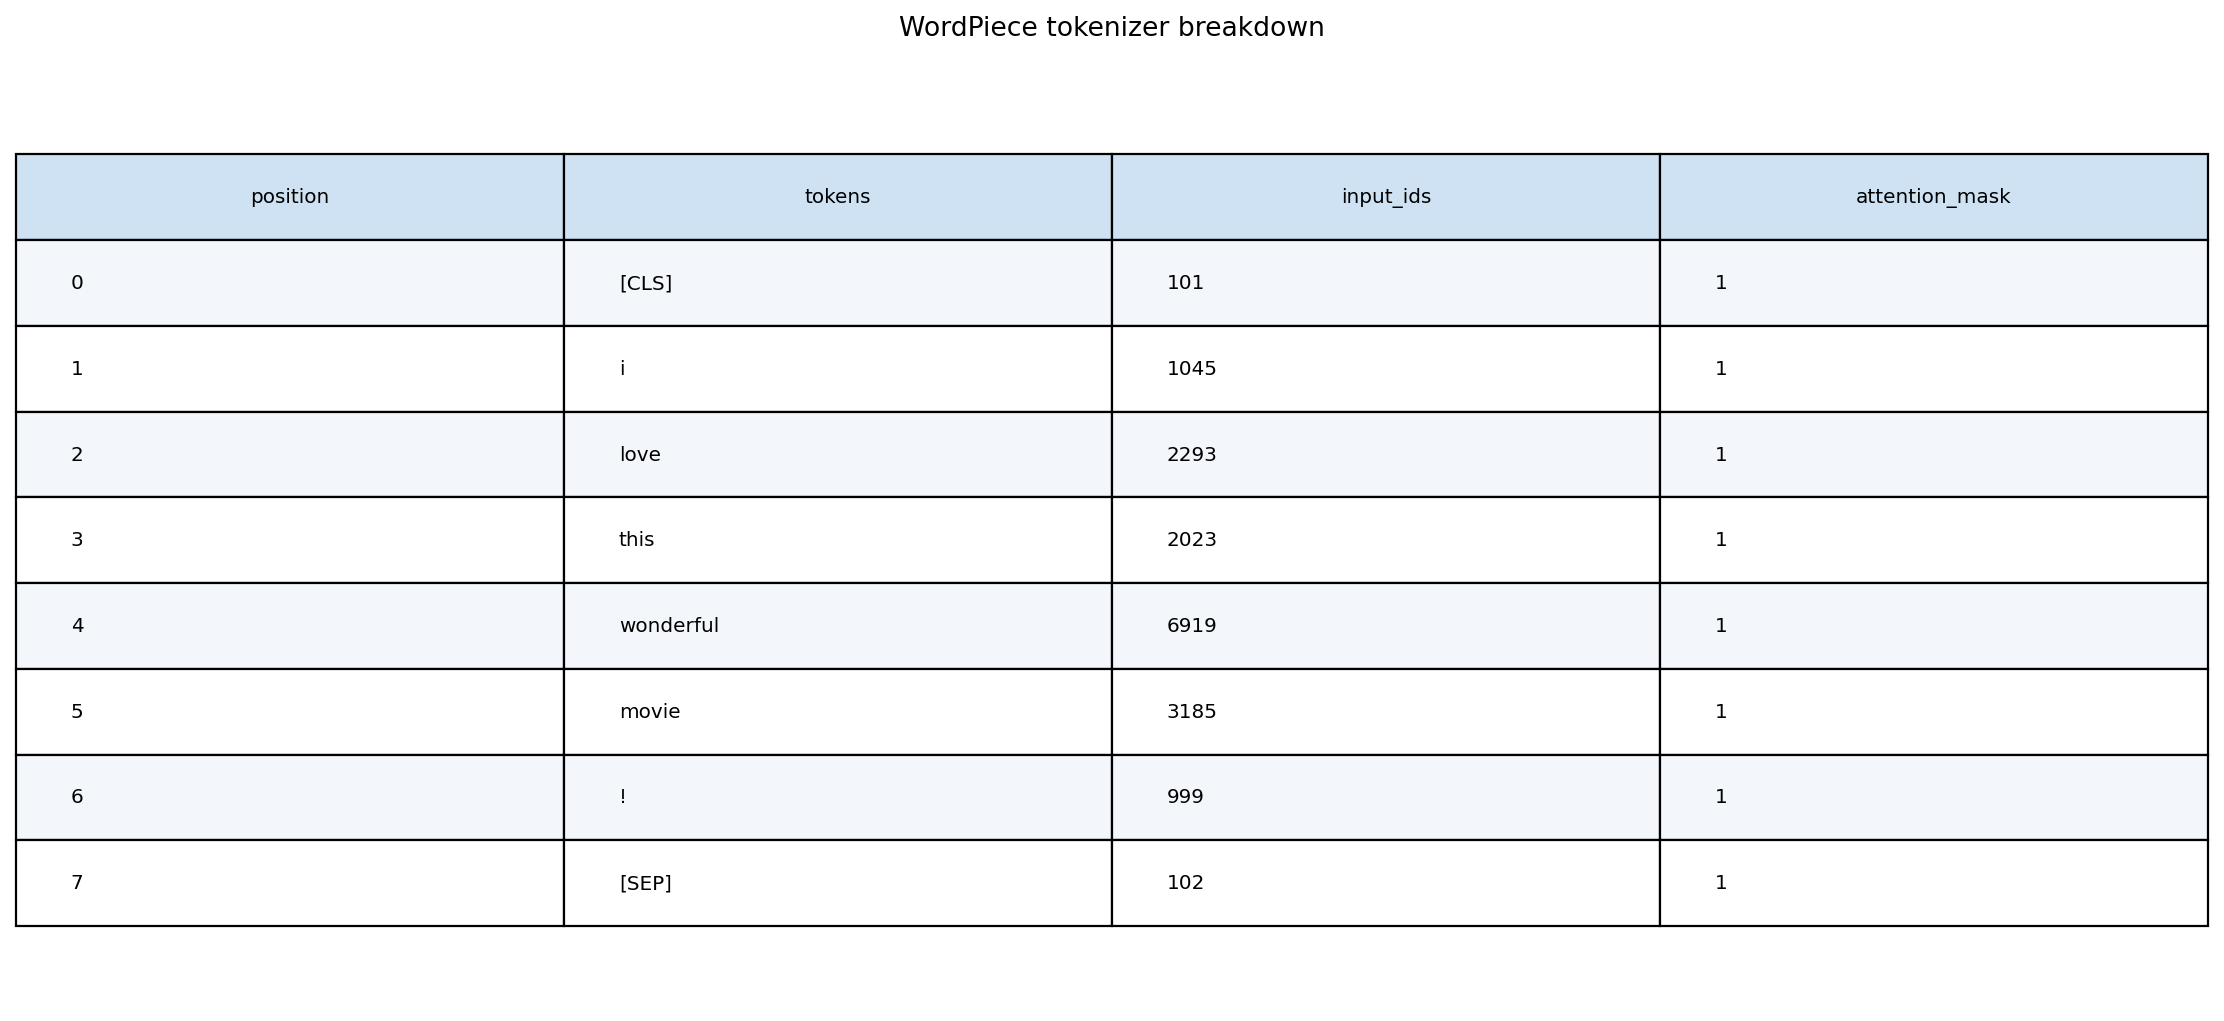

In [22]:
study_exercise1 = LAB / "outputs/runs/20261026T184202Z_exercise1_de76a80c"
study_exercise1_analysis = LAB / "outputs/runs/20261026T184207Z_exercise1_analysis_5406bc6c"
display(pd.DataFrame(read_json(study_exercise1 / "predictions.json")["manual"]))
for path in sorted(study_exercise1_analysis.glob("*.png")):
    show_study_image(path, f"**Exercise 1 — {path.name}**")

## P2 — Full official splits và kiểm toán nội dung

Dữ liệu gồm **8.530 train / 1.066 validation / 1.066 test**; train có 4.265 mẫu mỗi lớp, validation/test có 533 mẫu mỗi lớp. Max length 128; token dài nhất trong train là 78 nên không có train review bị truncation ở cutoff này. Không suy ra test cũng không bị cắt chỉ từ thống kê train.

Audit exact và casefold-whitespace ghi **0 duplicate nội bộ và 0 overlap giữa mọi cặp split**. Đây là hai phép kiểm cụ thể, không chứng minh không có paraphrase, near duplicate hoặc contamination từ pretraining.

,split,samples
0,train,8530
1,validation,1066
2,test,1066


{'mean': 27.368347010550995, 'max': 78, 'truncated_fraction': 0.0}

{'exact': {'within_split_duplicates': {'train': 0, 'validation': 0, 'test': 0},
  'cross_split_overlaps': {'train__validation': 0,
   'train__test': 0,
   'validation__test': 0}},
 'casefold_whitespace': {'within_split_duplicates': {'train': 0,
   'validation': 0,
   'test': 0},
  'cross_split_overlaps': {'train__validation': 0,
   'train__test': 0,
   'validation__test': 0}}}

**Full official class counts**

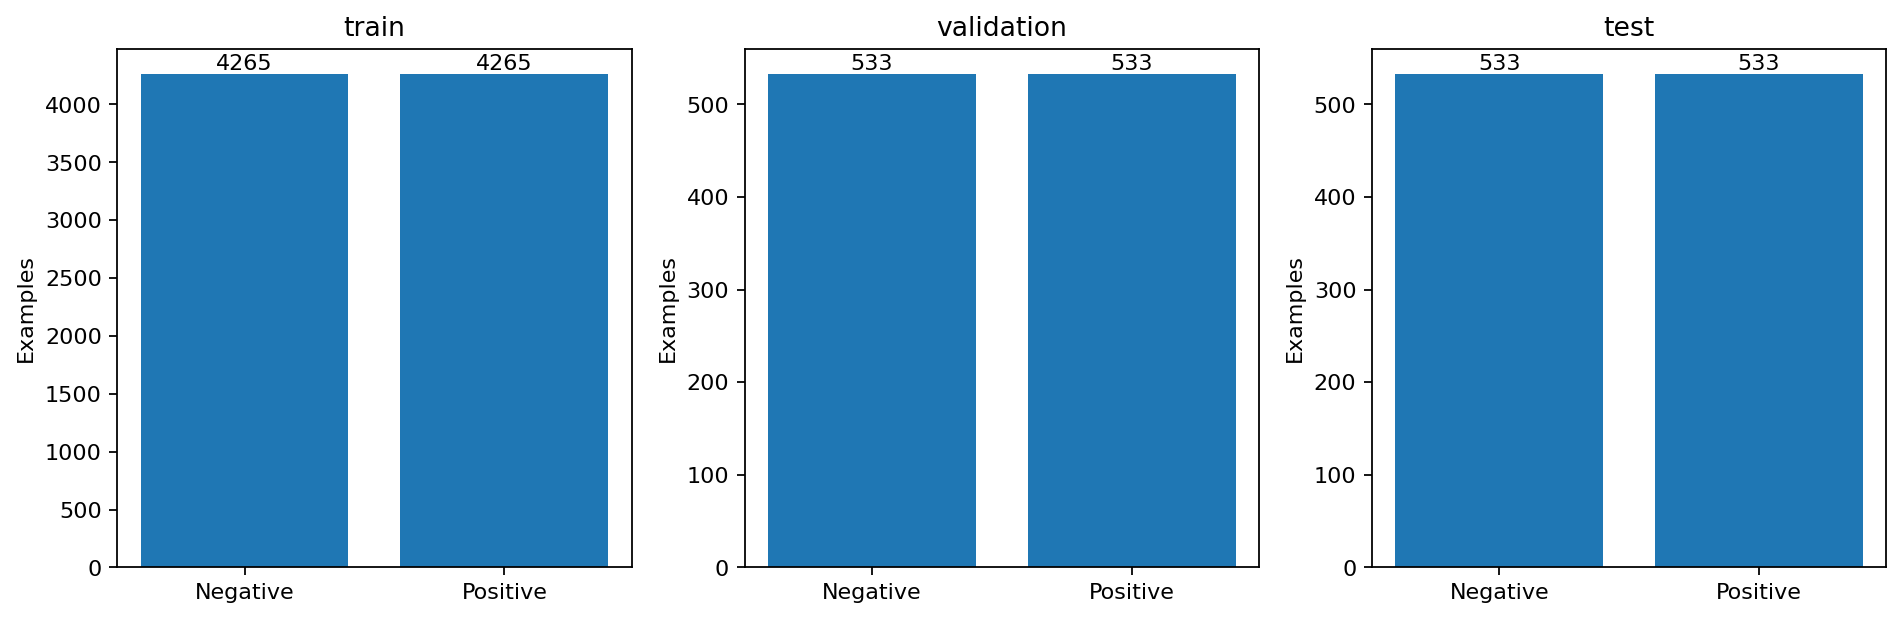

**Độ dài train trước truncation; cutoff=128**

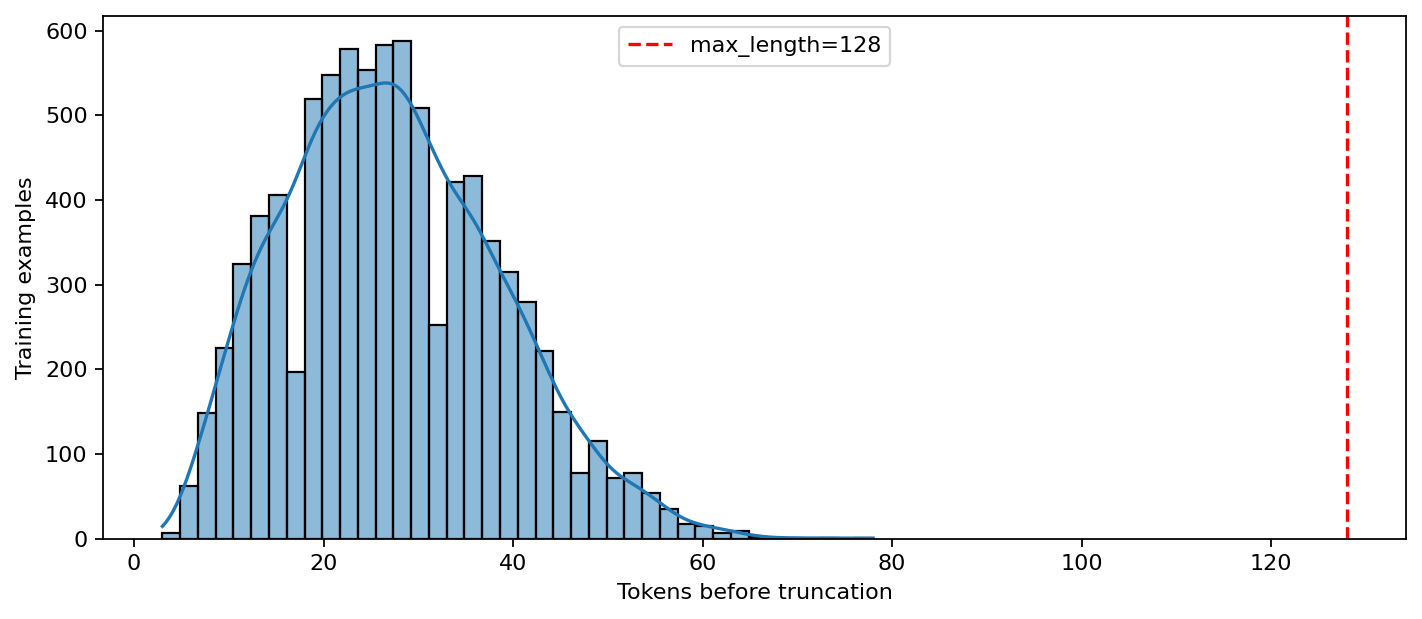

In [23]:
study_winner = LAB / "outputs/runs" / study_summary["winner"]["run_id"]
study_stats = read_json(study_winner / "data_statistics.json")
display(pd.DataFrame([{"split":k,"samples":v} for k,v in study_stats["split_sizes"].items()]))
display(study_stats["train_token_lengths"])
display(read_json(study_run / "split_overlap_audit.json"))
show_study_image(study_run / "class_distribution.png", "**Full official class counts**")
show_study_image(study_winner / "token_length_distribution.png", "**Độ dài train trước truncation; cutoff=128**")

## P3 — Baseline TF-IDF + Logistic Regression

Vocabulary/IDF chỉ fit train; word unigram/bigram, sublinear TF, min_df=2, tối đa 50.000 features. C grid `[0.1, 1, 10]` chọn trên validation Macro-F1, không dựa test. **C=10** thắng với validation Macro-F1 ≈0,748561. Không refit train+validation sau selection để giữ validation cho threshold.

Baseline đạt test Accuracy **78,2364%** ở 0,5 và **78,7054%** với threshold validation 0,4. Threshold 0,4 tăng recall Positive nhưng tăng FP và giảm precision. Đừng bỏ baseline hoặc operating point kém hơn khỏi báo cáo.

,C,accuracy,binary_precision,binary_recall,binary_f1,macro_precision,macro_recall,macro_f1,loss,selection_split
0,0.1,0.722326,0.713514,0.742964,0.727941,0.722706,0.722326,0.722208,0.645547,validation
1,1.0,0.748593,0.740472,0.765478,0.752768,0.748877,0.748593,0.748521,0.536022,validation
2,10.0,0.748593,0.743119,0.759850,0.751391,0.748719,0.748593,0.748561,0.488585,validation


,model,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,TF-IDF + logistic regression (0.5),0.5,0.782364,0.786667,0.774859,0.789869,0.210131,0.780718,0.782352,421,112,120,413,533,533,1066
1,TF-IDF + validation threshold,0.4,0.787054,0.754153,0.851782,0.722326,0.277674,0.800000,0.786158,385,148,79,454,533,533,1066
2,DistilBERT (0.5),0.5,0.833959,0.838403,0.827392,0.840525,0.159475,0.832861,0.833952,448,85,92,441,533,533,1066
3,DistilBERT + validation threshold,0.5,0.833959,0.838403,0.827392,0.840525,0.159475,0.832861,0.833952,448,85,92,441,533,533,1066


**Test comparison của các policy đã chốt trên validation**

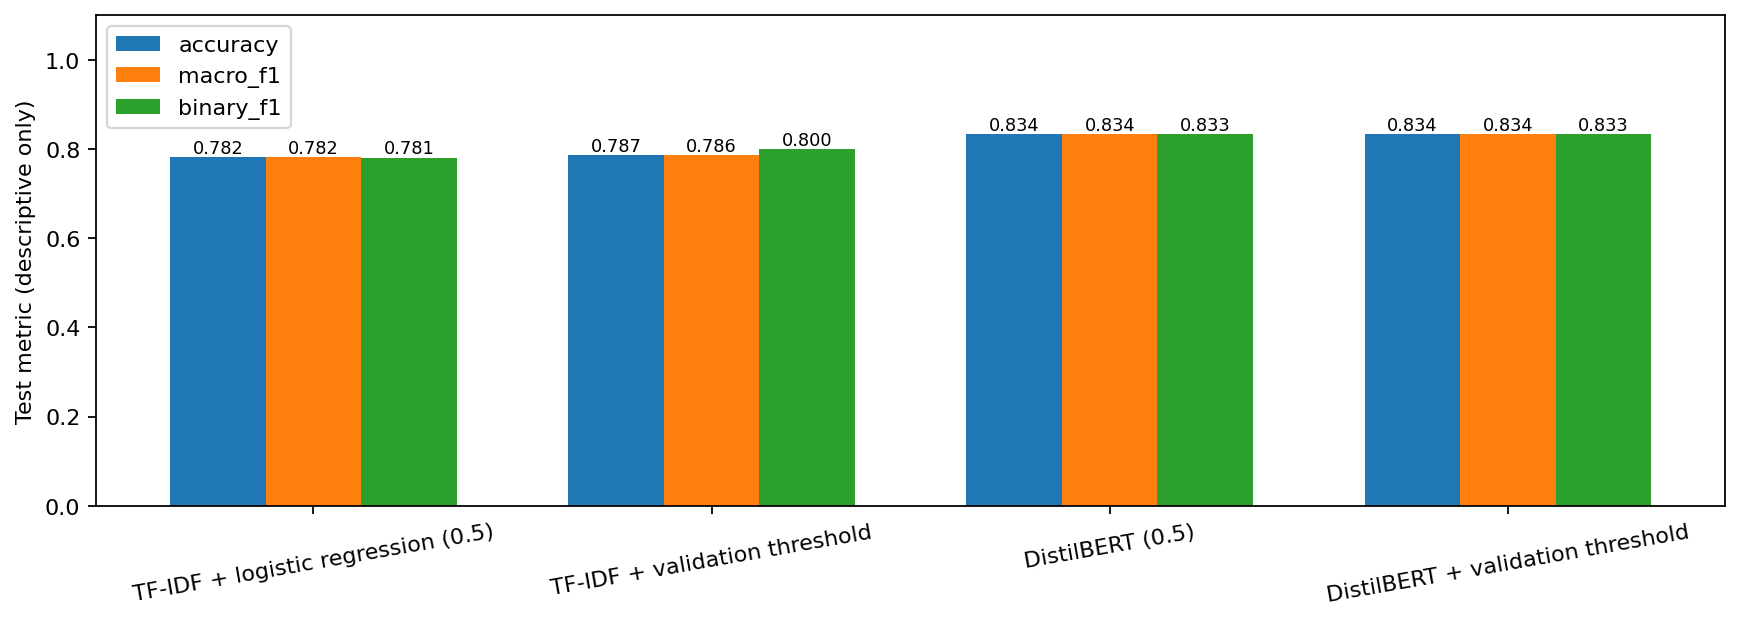

In [24]:
study_baseline_rows = read_json(study_run / "baseline_validation_candidates.json")
display(pd.DataFrame([{k:v for k,v in r.items() if not isinstance(v,list)} for r in study_baseline_rows]))
display(pd.DataFrame(read_json(study_run / "test_comparison.json")))
show_study_image(study_run / "baseline_model_comparison.png", "**Test comparison của các policy đã chốt trên validation**")

## P4 — Học đủ 10 epoch, quan sát theo step

Mỗi candidate có **5.340 Trainer global steps**, 63 mốc validation và 10 lần train-eval cuối epoch. AMP bỏ qua 5/4/5 optimizer updates ở ba LR; số updates thành công là 5.335/5.336/5.335. Không gọi global steps là tất cả đều đã cập nhật weights thành công.

Loss hình epoch đo train và validation ở chế độ eval, dropout tắt. Optimization loss hình step là trung bình cửa sổ trong lúc weights đang đổi, không cùng measurement context. Đường dọc đánh dấu checkpoint được chọn; các mốc sau vẫn chạy đến đủ epoch 10.

**Cách hiển thị đã chỉnh:** biểu đồ chính lấy đúng mốc cuối các epoch 1–10, mỗi đường 10 điểm. Đây là vẽ lại từ history gốc, không train lại, không sửa weights và không làm biến mất overfitting. Dashboard theo step mặc định ẩn (`SHOW_STEP_DIAGNOSTICS=False`).

,run_id,learning_rate,selection_split,macro_f1,loss,completed_epochs,best_step,best_epoch,lowest_validation_loss,lowest_loss_epoch,lowest_loss_macro_f1,final_train_accuracy,final_train_eval_loss,final_validation_macro_f1,final_validation_loss,global_steps,successful_optimizer_updates,amp_skipped_optimizer_steps,validation_milestones,train_runtime_seconds
0,20261026T184223Z_candidate_4b1da858,0.00001,validation,0.849906,0.755625,10.0,3200,5.992509,0.354226,1.685393,0.838603,0.997069,0.017905,0.843339,0.915719,5340,5335,5,63,461.3409
1,20261026T185017Z_candidate_202c0434,0.00002,validation,0.848920,0.747378,10.0,2100,3.932584,0.371871,1.872659,0.836519,0.999883,0.000844,0.843328,1.168640,5340,5336,4,63,457.4038
2,20261026T185804Z_candidate_8308037d,0.00003,validation,0.856473,0.702748,10.0,1700,3.183521,0.368855,1.000000,0.834882,1.000000,0.000044,0.842388,1.241744,5340,5335,5,63,454.3989


### LR=1e-05: best step 3200, epoch 5.993

,run_id,learning_rate,epoch,step,train_eval_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1
0,20261026T184223Z_candidate_4b1da858,0.00001,1.0,534,0.361184,0.846424,0.409649,0.815197,0.813718
1,20261026T184223Z_candidate_4b1da858,0.00001,2.0,1068,0.196510,0.931067,0.364261,0.843340,0.843316
2,20261026T184223Z_candidate_4b1da858,0.00001,3.0,1602,0.116793,0.962954,0.407902,0.836773,0.836726
3,20261026T184223Z_candidate_4b1da858,0.00001,4.0,2136,0.070221,0.981243,0.523578,0.842402,0.842374
4,20261026T184223Z_candidate_4b1da858,0.00001,5.0,2670,0.044462,0.988746,0.682248,0.840525,0.840516
5,20261026T184223Z_candidate_4b1da858,0.00001,6.0,3204,0.030209,0.993904,0.762776,0.848030,0.847987
6,20261026T184223Z_candidate_4b1da858,0.00001,7.0,3738,0.023675,0.995662,0.810585,0.839587,0.839536
7,20261026T184223Z_candidate_4b1da858,0.00001,8.0,4272,0.020152,0.996600,0.886487,0.843340,0.843316
8,20261026T184223Z_candidate_4b1da858,0.00001,9.0,4806,0.018848,0.996952,0.922118,0.839587,0.839570
9,20261026T184223Z_candidate_4b1da858,0.00001,10.0,5340,0.017905,0.997069,0.915719,0.843340,0.843339


**Đúng 10 điểm cuối epoch: train-eval và validation**

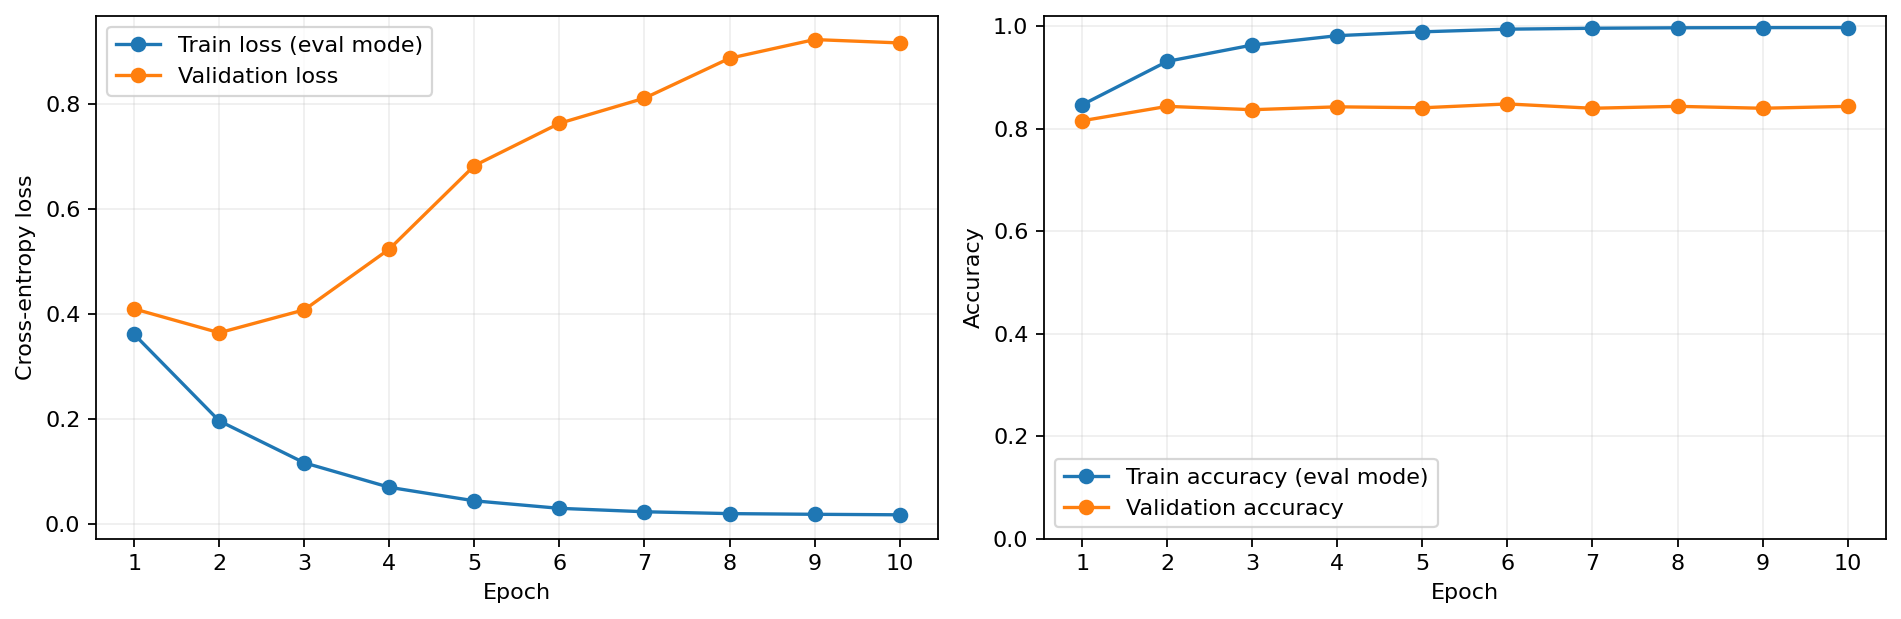

### LR=2e-05: best step 2100, epoch 3.933

,run_id,learning_rate,epoch,step,train_eval_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1
0,20261026T185017Z_candidate_202c0434,0.00002,1.0,534,0.284754,0.890856,0.375641,0.833959,0.833662
1,20261026T185017Z_candidate_202c0434,0.00002,2.0,1068,0.139032,0.951817,0.401150,0.839587,0.839484
2,20261026T185017Z_candidate_202c0434,0.00002,3.0,1602,0.055867,0.982415,0.515694,0.839587,0.839586
3,20261026T185017Z_candidate_202c0434,0.00002,4.0,2136,0.027041,0.993318,0.798238,0.836773,0.836703
4,20261026T185017Z_candidate_202c0434,0.00002,5.0,2670,0.013019,0.996835,0.858950,0.834897,0.834860
5,20261026T185017Z_candidate_202c0434,0.00002,6.0,3204,0.005685,0.998945,1.010918,0.838649,0.838603
6,20261026T185017Z_candidate_202c0434,0.00002,7.0,3738,0.001735,0.999766,1.061436,0.842402,0.842322
7,20261026T185017Z_candidate_202c0434,0.00002,8.0,4272,0.001151,0.999766,1.119127,0.840525,0.840520
8,20261026T185017Z_candidate_202c0434,0.00002,9.0,4806,0.000924,0.999883,1.158766,0.835835,0.835823
9,20261026T185017Z_candidate_202c0434,0.00002,10.0,5340,0.000844,0.999883,1.168640,0.843340,0.843328


**Đúng 10 điểm cuối epoch: train-eval và validation**

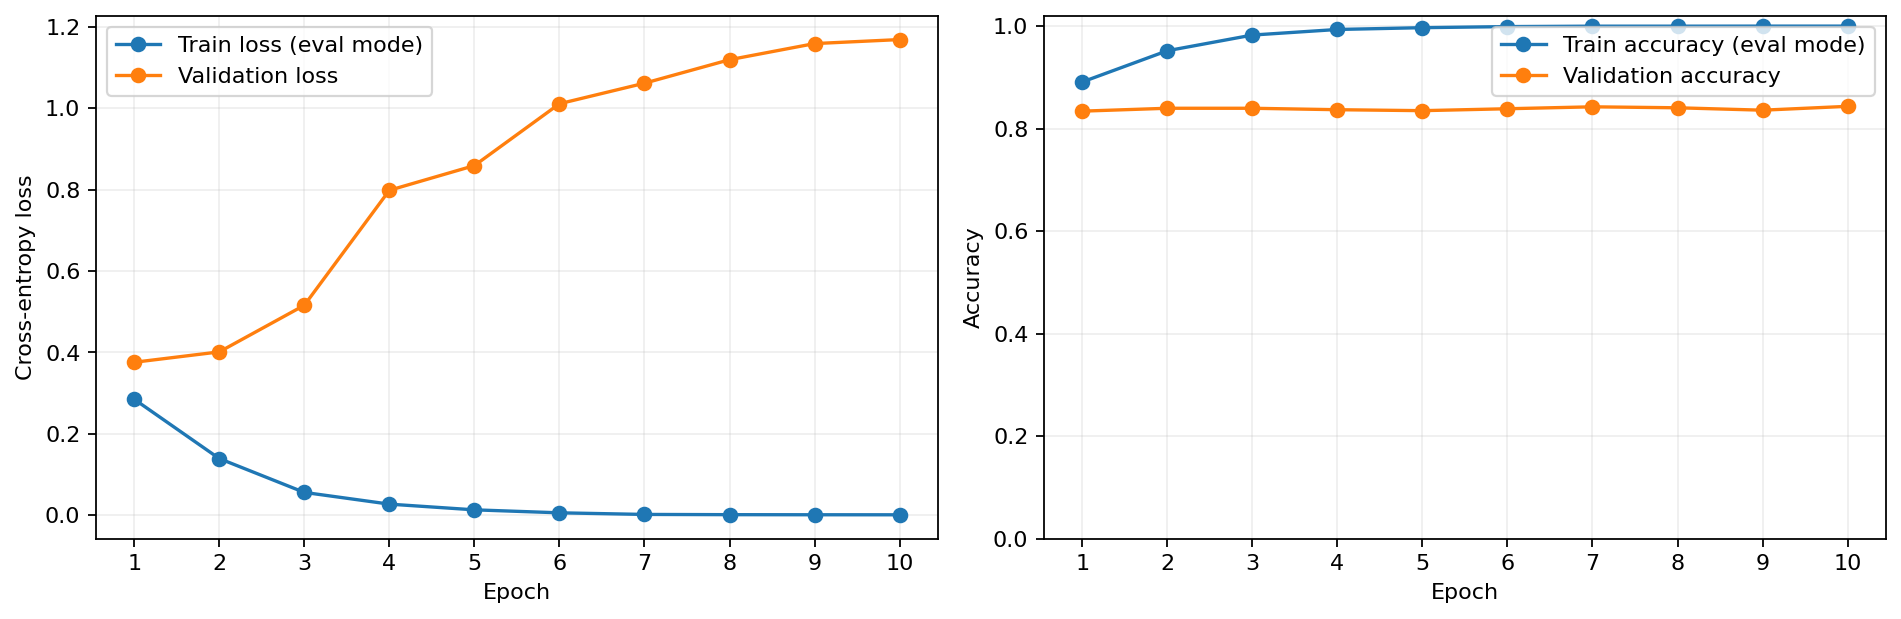

### LR=3e-05: best step 1700, epoch 3.184

,run_id,learning_rate,epoch,step,train_eval_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1
0,20261026T185804Z_candidate_8308037d,0.00003,1.0,534,0.252050,0.903048,0.368855,0.834897,0.834882
1,20261026T185804Z_candidate_8308037d,0.00003,2.0,1068,0.112389,0.962134,0.401104,0.843340,0.843339
2,20261026T185804Z_candidate_8308037d,0.00003,3.0,1602,0.049154,0.983118,0.538902,0.837711,0.836988
3,20261026T185804Z_candidate_8308037d,0.00003,4.0,2136,0.018800,0.995311,0.802981,0.839587,0.839248
4,20261026T185804Z_candidate_8308037d,0.00003,5.0,2670,0.005281,0.999179,0.958392,0.833959,0.833906
5,20261026T185804Z_candidate_8308037d,0.00003,6.0,3204,0.002950,0.999414,1.118980,0.836773,0.836690
6,20261026T185804Z_candidate_8308037d,0.00003,7.0,3738,0.001412,0.999648,1.150906,0.839587,0.839468
7,20261026T185804Z_candidate_8308037d,0.00003,8.0,4272,0.000568,0.999883,1.208887,0.841463,0.841457
8,20261026T185804Z_candidate_8308037d,0.00003,9.0,4806,0.000055,1.000000,1.204243,0.846154,0.846153
9,20261026T185804Z_candidate_8308037d,0.00003,10.0,5340,0.000044,1.000000,1.241744,0.842402,0.842388


**Đúng 10 điểm cuối epoch: train-eval và validation**

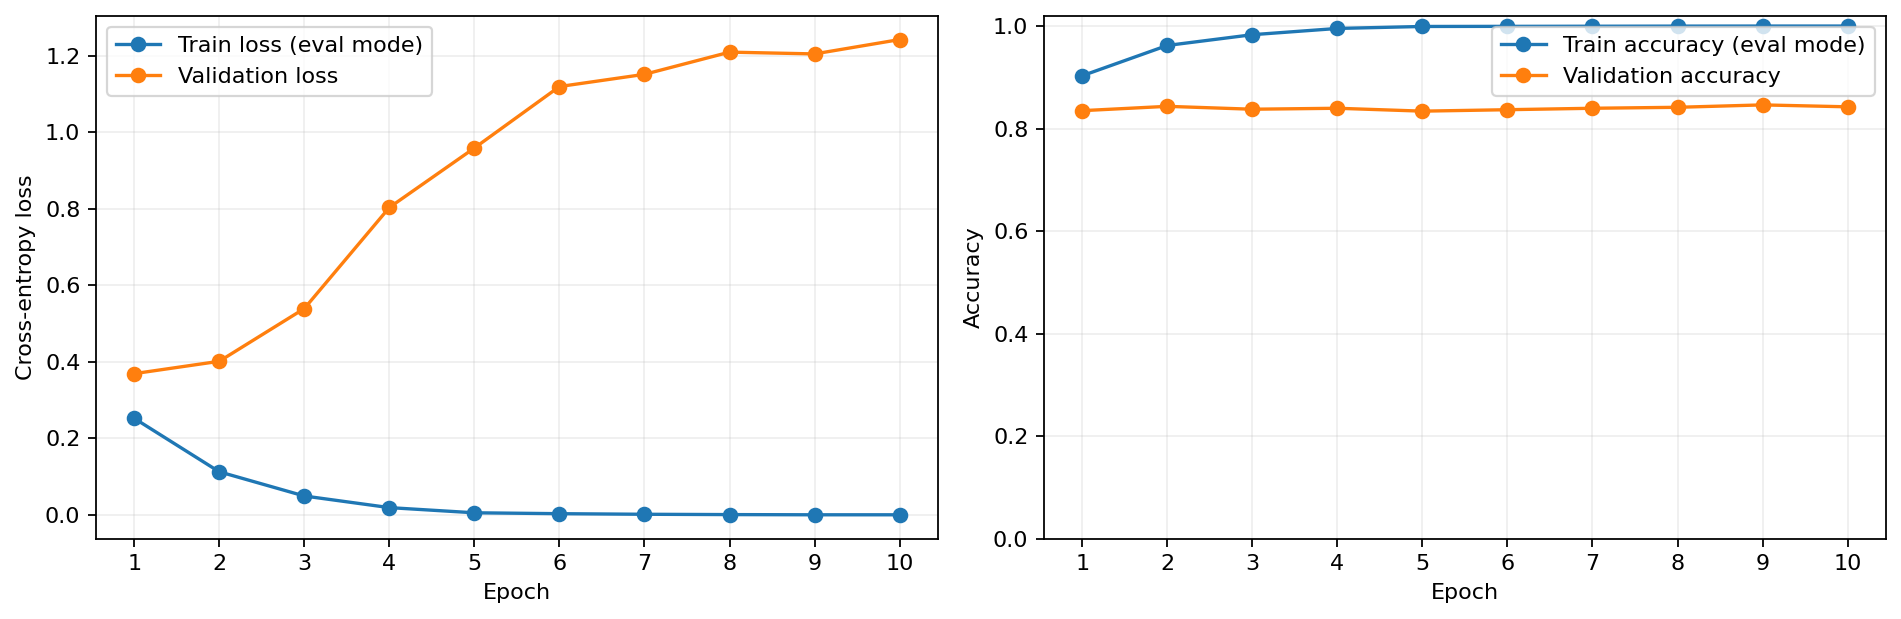

In [25]:
display(pd.DataFrame(study_tables["candidates"]))
for candidate in study_tables["candidates"]:
    source = LAB / "outputs/runs" / candidate["run_id"]
    display(Markdown(f"### LR={candidate['learning_rate']:g}: best step {candidate['best_step']}, epoch {candidate['best_epoch']:.3f}"))
    display(pd.DataFrame([r for r in study_tables["epochs"] if r["run_id"] == candidate["run_id"]]))
    show_study_image(epoch_presentation / candidate["run_id"] / "learning_curves.png", "**Đúng 10 điểm cuối epoch: train-eval và validation**")
    if SHOW_STEP_DIAGNOSTICS:
        show_study_image(source / "step_learning_curves.png", "**Dashboard bổ sung theo step**")

## P5 — Checkpoint winner và dấu hiệu overfitting

LR `3e-5` thắng bằng validation Macro-F1 **85,6473%**, tại **step 1700 / epoch 3,184**, validation loss **0,702748**. Loss thấp nhất của candidate này là **0,368855 tại epoch 1**, nhưng criterion đã chốt là Macro-F1, không phải loss. Không đổi criterion sau khi đã thấy test.

Tại epoch 10, winner đạt **100% train accuracy**, train-eval loss ≈0,0000441, còn validation Macro-F1 ≈84,2388% và loss ≈1,241744. Đây là dấu hiệu học thuộc train và confidence xấu đi trên validation. 100% train accuracy không phải bằng chứng đạt 100% trên dữ liệu mới. Bộ raw/normalized overlap không phát hiện giao nhau, nhưng chưa kiểm tra near-duplicate hoặc pretraining contamination.

**Ba learning rate trên cùng validation**

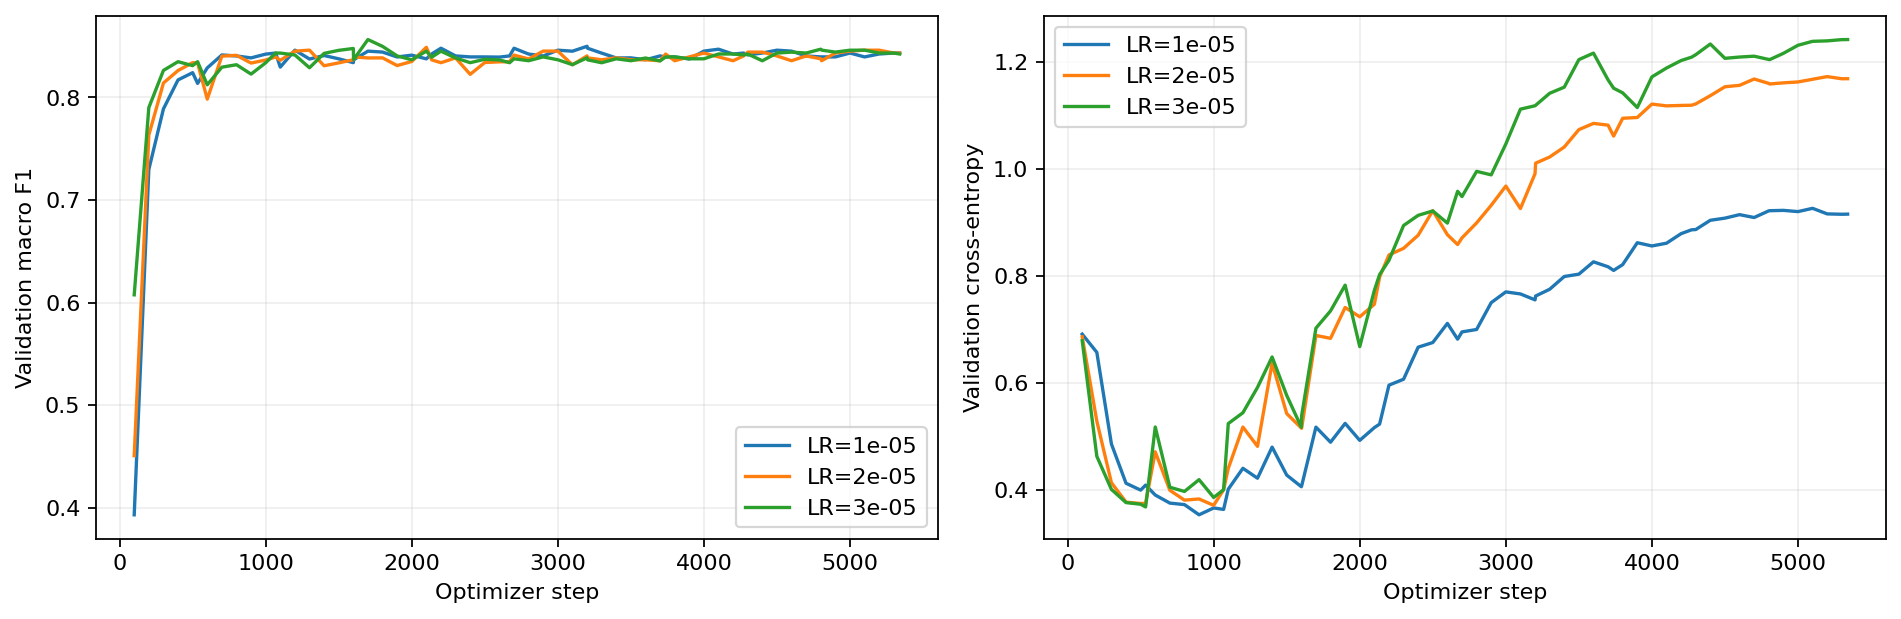

**Best checkpoint khác weights epoch cuối**

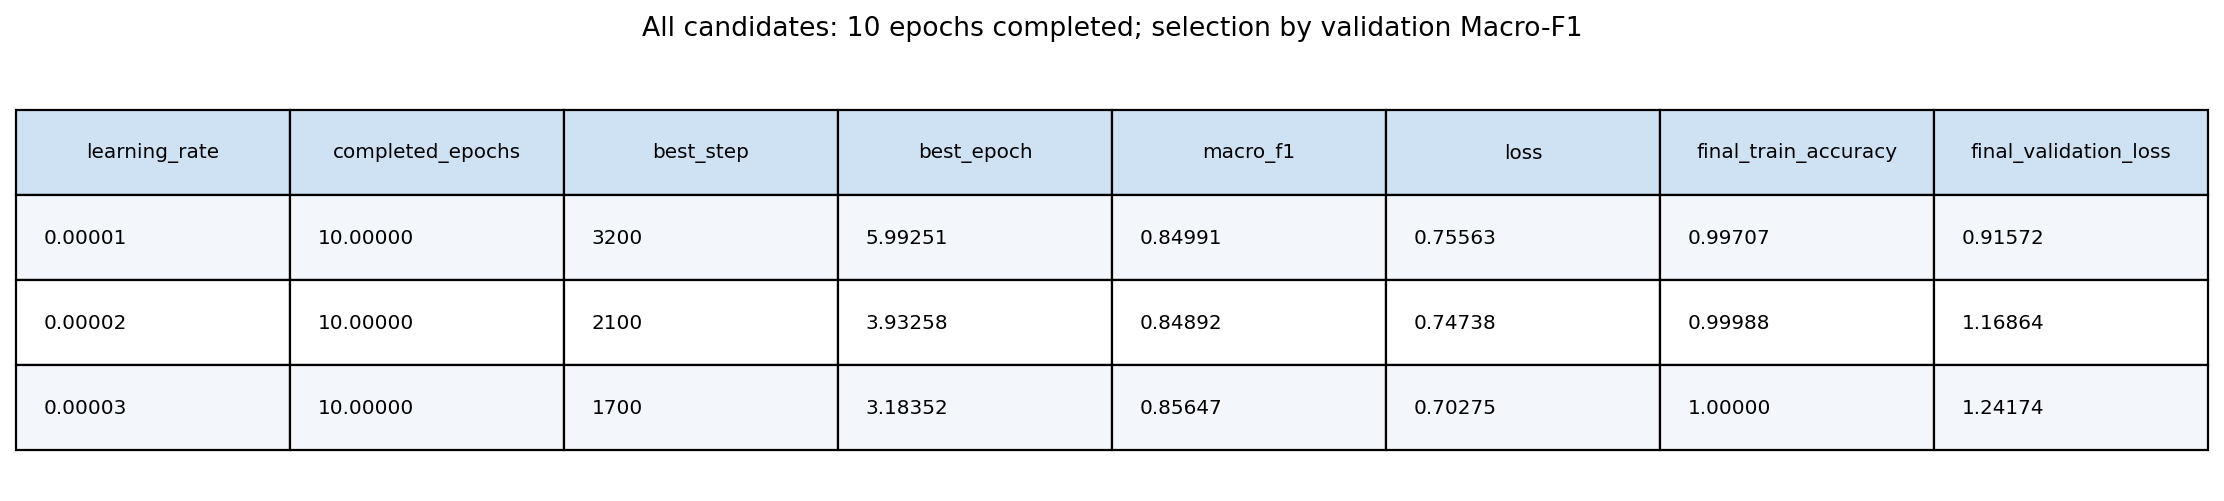

**Generalization gap và validation loss qua đủ 10 epoch**

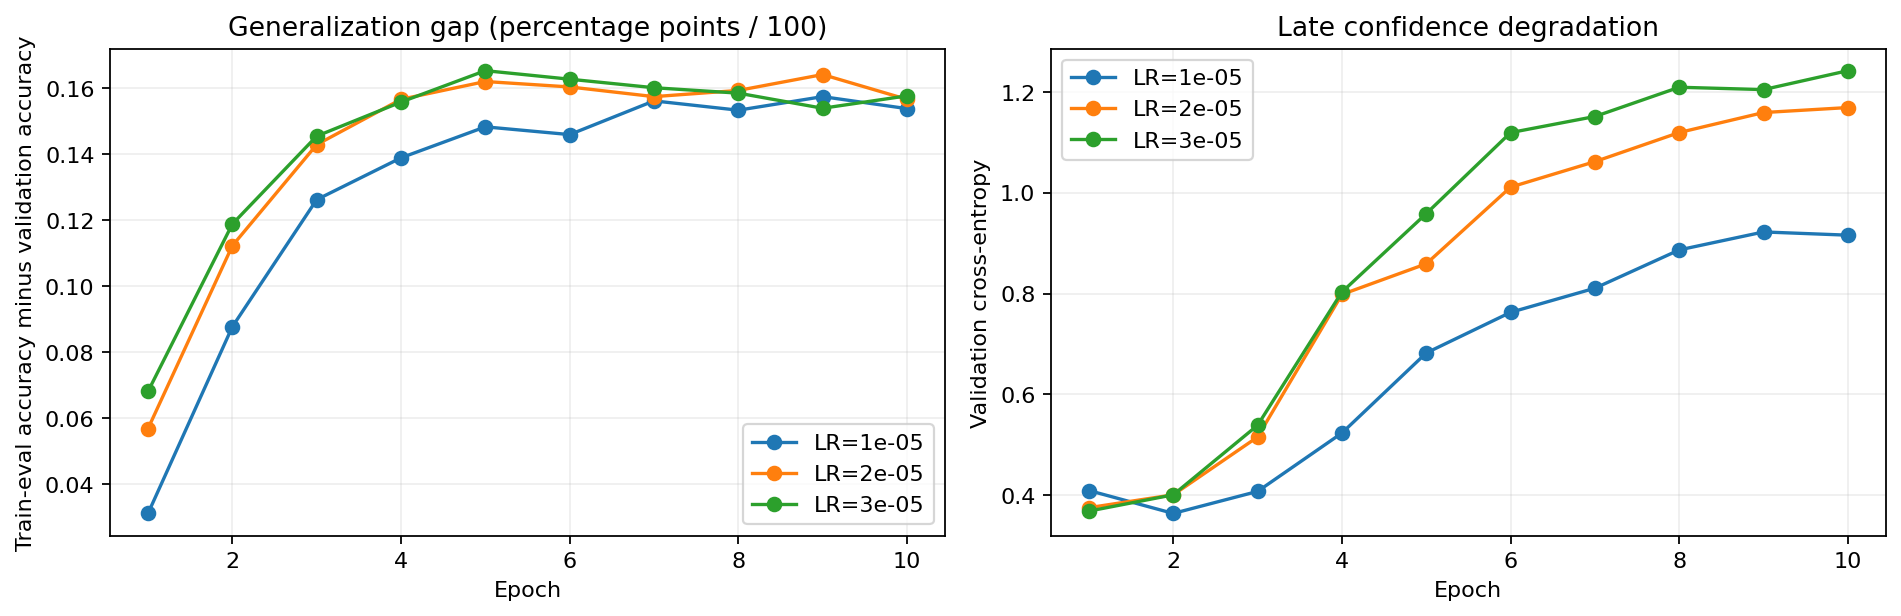

{'winner': {'run_id': '20261026T185804Z_candidate_8308037d',
  'learning_rate': 3e-05,
  'selection_split': 'validation',
  'macro_f1': 0.8564726691922859,
  'loss': 0.7027483582496643,
  'completed_epochs': 10.0,
  'best_step': 1700},
 'threshold': 0.5,
 'selection_split': 'validation',
 'test_used_for_selection': False,
 'candidate_manifest_sha256': '20b5707b2b344f8386f1e929460fd6824da7794ef575bb32ce6a94d093fff705',
 'prior_test_exposure': 'The historical 3-epoch test report was already inspected; this is not a new untouched benchmark.'}

In [26]:
show_study_image(study_run / "candidate_validation_comparison.png", "**Ba learning rate trên cùng validation**")
show_study_image(study_review / "candidate_summary.png", "**Best checkpoint khác weights epoch cuối**")
show_study_image(study_review / "overfitting_diagnostics.png", "**Generalization gap và validation loss qua đủ 10 epoch**")
display(read_json(study_run / "frozen_selection.json"))

## P6 — Threshold validation vẫn có thể là 0,5

Grid đã quét đủ **19 điểm 0,05…0,95**, objective validation Macro-F1; tie-break gần 0,5 rồi nhỏ hơn. Winner chọn **0,5**. Quét threshold không bắt buộc phải tìm ra một threshold khác 0,5 và không bảo đảm nâng test score.

Policy giữ checkpoint SHA256 và validation fingerprint. Review ZIP không có weights nên kiểm toán tại đây xác minh policy liên kết với hash trong manifest, không giả vờ đã chạy lại model. Candidate LR=1e-5 chọn threshold 0,6 nhưng không được đánh giá test để chọn lại winner.

,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,0.05,0.846154,0.824253,0.879925,0.812383,0.187617,0.851180,0.845978,433,100,64,469,533,533,1066
1,0.10,0.849906,0.832442,0.876173,0.823640,0.176360,0.853748,0.849803,439,94,66,467,533,533,1066
2,0.15,0.846154,0.832432,0.866792,0.825516,0.174484,0.849265,0.846088,440,93,71,462,533,533,1066
3,0.20,0.850844,0.840000,0.866792,0.834897,0.165103,0.853186,0.850806,445,88,71,462,533,533,1066
4,0.25,0.850844,0.841241,0.864916,0.836773,0.163227,0.852914,0.850815,446,87,72,461,533,533,1066
5,0.30,0.849906,0.842202,0.861163,0.838649,0.161351,0.851577,0.849887,447,86,74,459,533,533,1066
6,0.35,0.851782,0.846580,0.859287,0.844278,0.155722,0.852886,0.851774,450,83,75,458,533,533,1066
7,0.40,0.853659,0.849722,0.859287,0.848030,0.151970,0.854478,0.853654,452,81,75,458,533,533,1066
8,0.45,0.854597,0.852612,0.857411,0.851782,0.148218,0.855005,0.854595,454,79,76,457,533,533,1066
9,0.50,0.856473,0.857143,0.855535,0.857411,0.142589,0.856338,0.856473,457,76,77,456,533,533,1066


,policy,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,0.5,0.5,0.856473,0.857143,0.855535,0.857411,0.142589,0.856338,0.856473,457,76,77,456,533,533,1066
1,selected,0.5,0.856473,0.857143,0.855535,0.857411,0.142589,0.856338,0.856473,457,76,77,456,533,533,1066


**Validation threshold scan của winner**

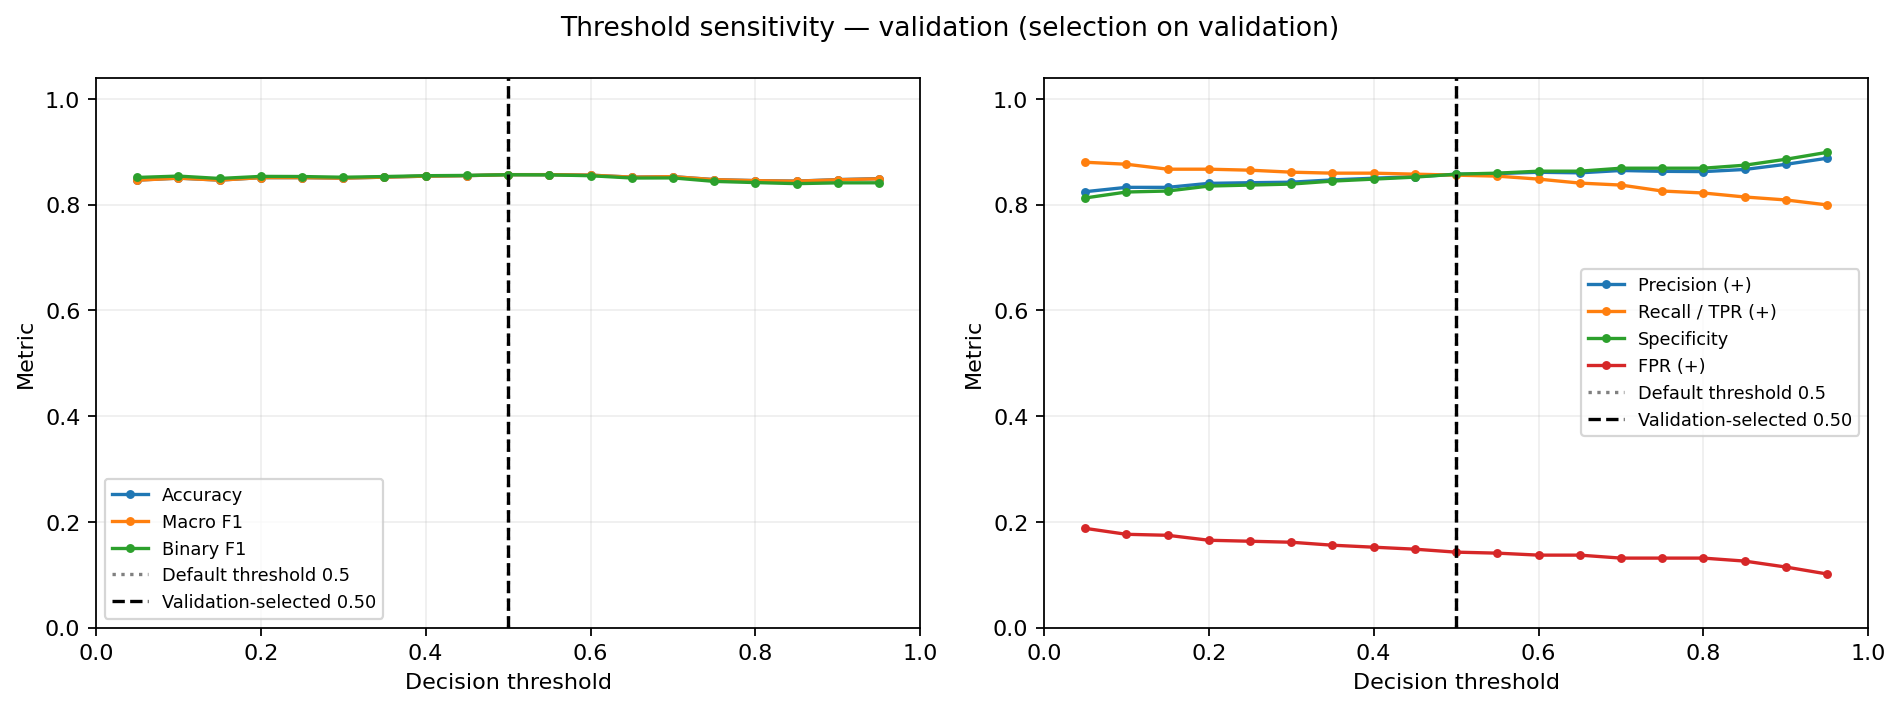

In [27]:
study_policy = read_json(study_run / "decision_threshold.json")
display(pd.DataFrame(study_policy["curve"]))
display(pd.DataFrame([{"policy":"0.5",**study_policy["baseline_metrics"]},
                      {"policy":"selected",**study_policy["selected_metrics"]}]))
show_study_image(study_winner / "validation_threshold/threshold_curves.png", "**Validation threshold scan của winner**")

## P7 — Full test sau khi khóa lựa chọn

Winner đúng **889/1.066**. Confusion matrix: **TN=448, FP=85, FN=92, TP=441**. Accuracy **83,3959%**, Macro-F1 **83,3952%**, Positive Precision **83,8403%**, Recall **82,7392%**, Binary-F1 **83,2861%**.

Test loss đo bằng Trainer **0,7980755568**; NLL dựng lại từ saved probabilities **0,7980772048** là số dẫn xuất riêng, có sai số do float. Threshold chỉ đổi label, không đổi cross-entropy của cùng probabilities. Với threshold 0,5, argmax và policy trùng nhau trong run này.

,accuracy,binary_precision,binary_recall,binary_f1,macro_precision,macro_recall,macro_f1
0,0.833959,0.838403,0.827392,0.832861,0.834016,0.833959,0.833952


,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count,selection_split,selection_performed_on_test
0,0.5,0.833959,0.838403,0.827392,0.840525,0.159475,0.832861,0.833952,448,85,92,441,533,533,1066,validation,False


,label,precision,recall,f1-score,support
0,NEGATIVE,0.829630,0.840525,0.835042,533.0
1,POSITIVE,0.838403,0.827392,0.832861,533.0


**Test confusion matrix — argmax**

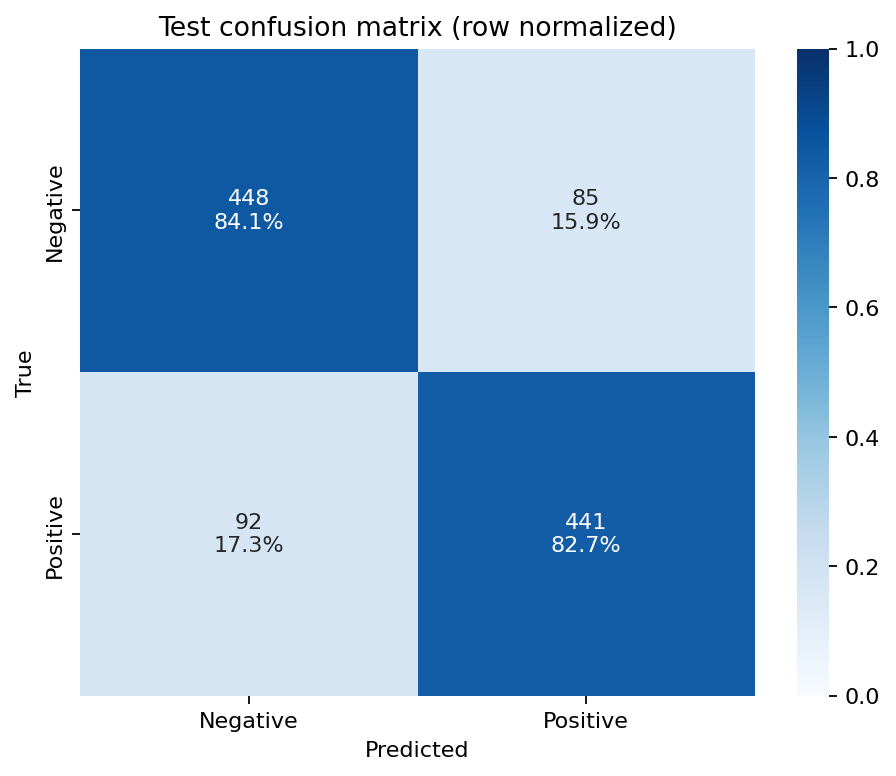

**Test confusion matrix — frozen validation threshold 0.5**

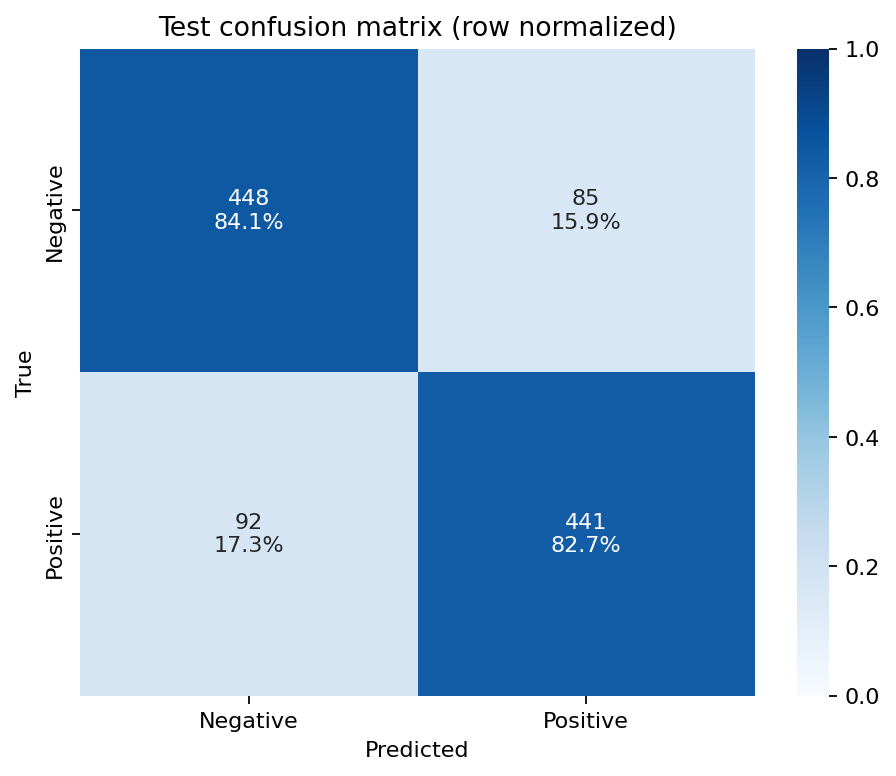

**Metric từng lớp, support=533 mỗi lớp**

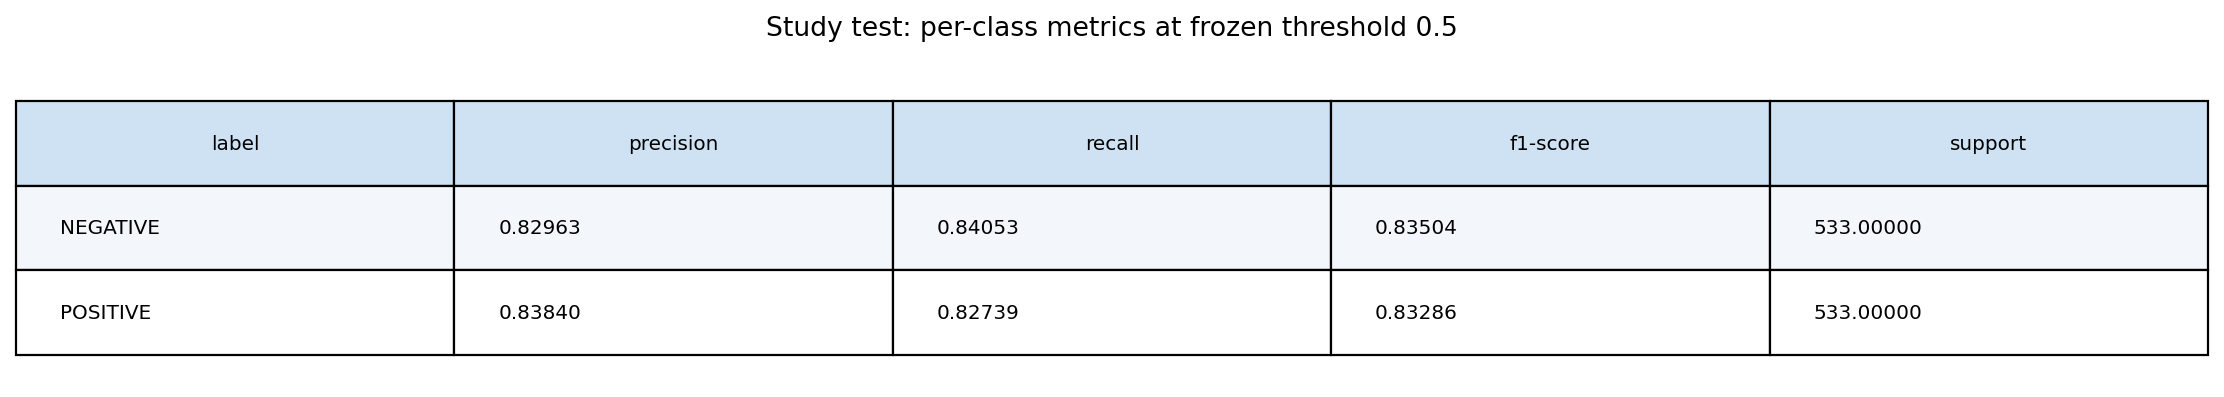

In [28]:
display(pd.DataFrame([read_json(study_run / "test_metrics.json")]))
display(pd.DataFrame([read_json(study_run / "test_threshold_metrics.json")]))
display(pd.DataFrame(study_tables["per_class"]))
show_study_image(study_run / "confusion_matrix.png", "**Test confusion matrix — argmax**")
show_study_image(study_run / "test_threshold/confusion_matrix.png", "**Test confusion matrix — frozen validation threshold 0.5**")
show_study_image(study_review / "per_class_metrics.png", "**Metric từng lớp, support=533 mỗi lớp**")

## P8 — Ranking, confidence và khoảng bất định

ROC-AUC **0,918416**, average precision **0,925989** cho biết khả năng xếp hạng; không có nghĩa accuracy đạt 91,84% hay confidence đã calibrated. Brier **0,150674**, top-label ECE **0,146071** và các ví dụ sai confidence >0,999 cho thấy confidence cần được thận trọng khi sử dụng.

Bootstrap phân tầng 2.000 lần cho model/policy cố định: Accuracy 95% percentile CI ≈ **[80,9568%; 85,6473%]**; Macro-F1 ≈ **[80,9568%; 85,6470%]**. Đây không phải khoảng bất định giữa các lần train, không bao gồm quá trình chọn hyperparameter và chỉ có một seed 42.

{'roc_auc': 0.918416411758287,
 'average_precision': 0.9259894498013682,
 'brier_score': 0.1506736755358776,
 'confidence_ece': 0.14607097334307081,
 'nll': 0.7980772048253766,
 'threshold': 0.5,
 'selection_split': 'validation',
 'bootstrap_95_percentile_ci': {'accuracy': [0.8095684803001876,
   0.8564727954971857],
  'macro_f1': [0.809568212168358, 0.8564696378079979]},
 'bootstrap_repeats': 2000,
 'ci_scope': 'fixed model, fixed threshold, stratified test sampling; excludes training-seed uncertainty'}

**ROC và Precision–Recall trên probabilities thật**

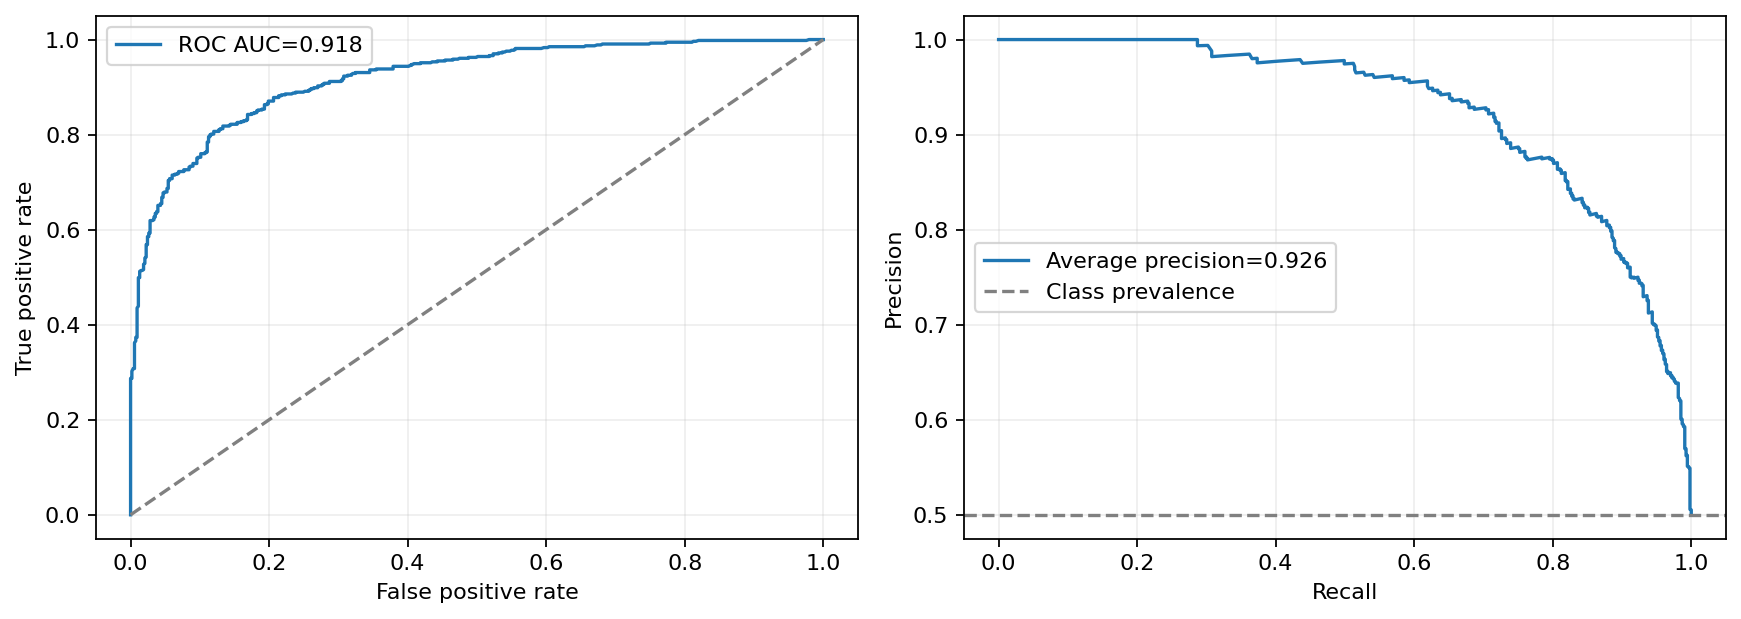

**Argmax confidence calibration và phân bố P(POSITIVE)**

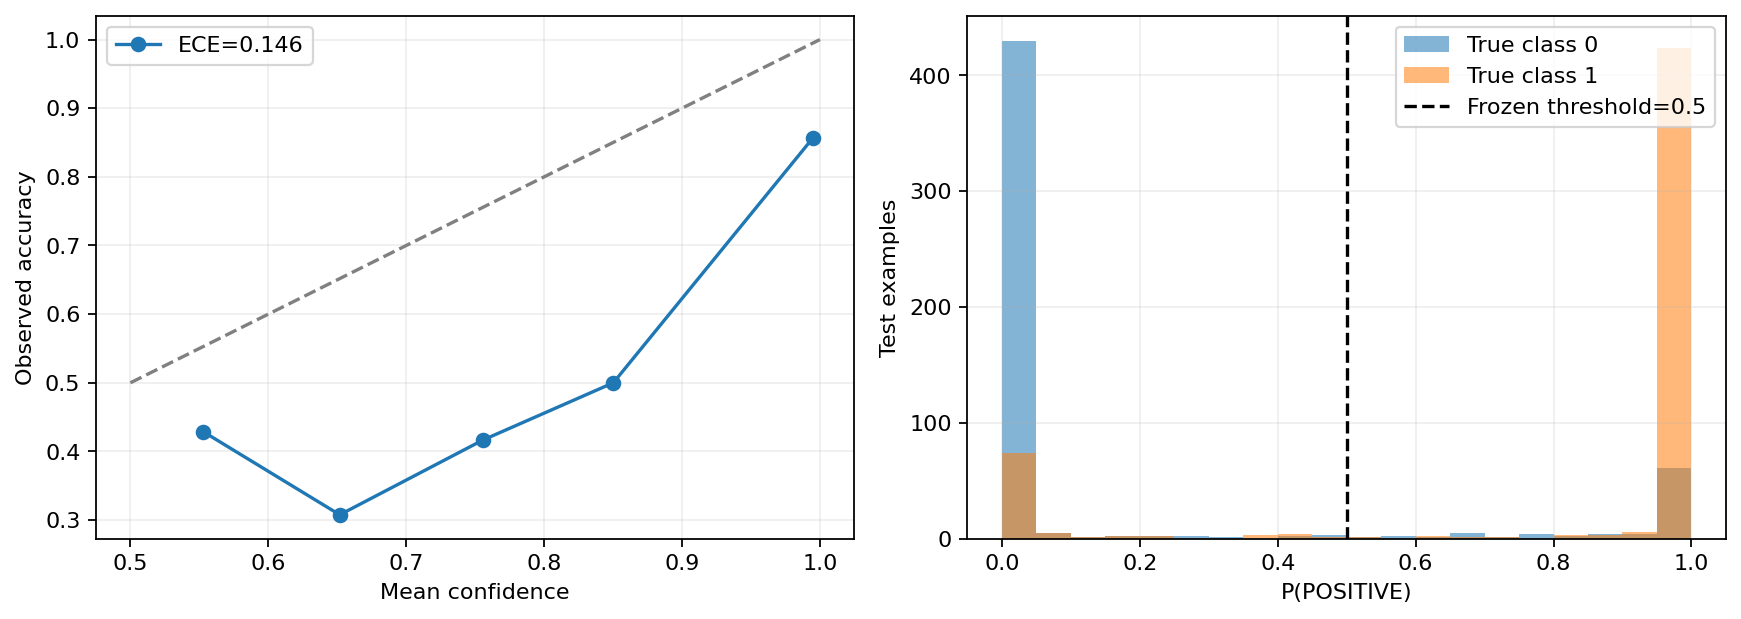

In [29]:
display(read_json(study_run / "probability_diagnostics.json"))
show_study_image(study_run / "roc_pr_curves.png", "**ROC và Precision–Recall trên probabilities thật**")
show_study_image(study_run / "calibration_confidence.png", "**Argmax confidence calibration và phân bố P(POSITIVE)**")

## P9 — So sánh với lịch sử 3 epoch: không ép kết luận cải thiện

Đã đối chiếu toàn bộ **index, text và nhãn** để bảo đảm cùng 1.066 test samples. Argmax lịch sử đúng 895; study đúng 889: giảm **6 mẫu / 0,5629 điểm phần trăm**. Study sửa 42 lỗi cũ nhưng sinh 48 lỗi mới; 847 mẫu cả hai đúng, 129 mẫu cả hai sai.

Paired stratified bootstrap CI 95% cho chênh accuracy (study − lịch sử) ≈ **[−2,3452; +1,2195] điểm phần trăm**, chứa 0. Không kết luận study vượt trội hoặc kém hơn có ý nghĩa thống kê từ chênh lệch này.

Đây không phải ablation chỉ thay epoch: còn khác LR được chọn, warmup/decay theo tổng ngân sách và criterion checkpoint. Test cũ từng được xem, nên cũng không gọi là blind test mới. Vẫn giữ winner LR=3e-5 theo validation; không đổi model vì đã thấy test của lịch sử cao hơn.

,same_test_cohort_verified,historical_correct,study_correct,both_correct,both_wrong,corrected_by_study,new_errors_in_study,accuracy_difference_study_minus_historical,paired_stratified_bootstrap_95_ci,bootstrap_repeats,bootstrap_seed,selection_performed,scope
0,True,895,889,847,129,42,48,-0.005629,"[-0.02345215759849906, 0.012195121951219513]",2000,42,False,descriptive comparison of two fixed prediction...


**Các nhóm đúng/sai trên cùng test cohort**

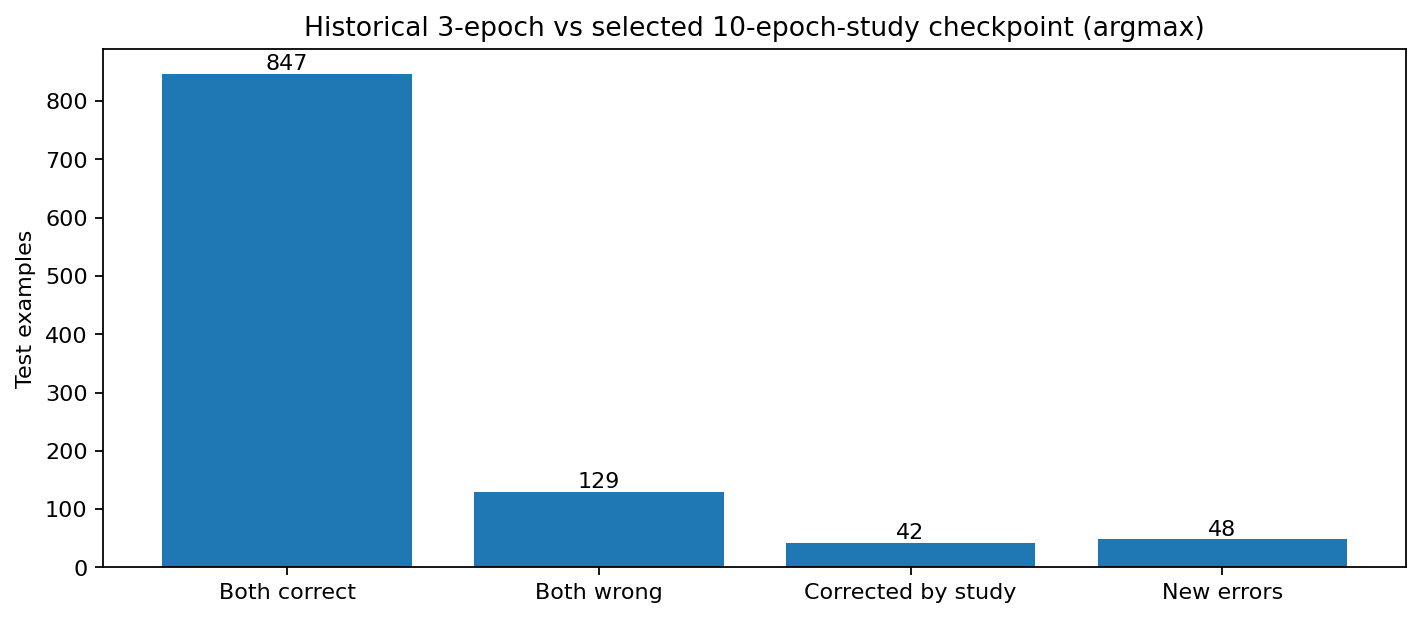

In [30]:
display(pd.DataFrame([study_tables["paired_comparison"]]))
show_study_image(study_review / "historical_paired_comparison.png", "**Các nhóm đúng/sai trên cùng test cohort**")

## P10 — Đọc lỗi và inference với policy đã chốt

- Câu “a very familiar tale…” bị dự đoán Positive dù nhãn Negative: phần “very familiar / told by countless filmmakers” có thể phê bình sự sáo mòn, còn nội dung sau mang từ vựng trung tính/nhân văn.
- Câu “entertains not so much… scrape the bottom…” bị Positive: cấu trúc tương phản và lời châm biếm có thể tạo tín hiệu xung đột.
- Câu “however canned… unexpectedly giddy viewing” bị Negative dù nhãn Positive: đánh giá cuối câu tích cực có thể bị lấn bởi sắc thái phủ định trước đó.
- Câu “almost puts the kibosh… otherwise a sumptuous work…” bị Negative: phê bình một đoạn không đồng nghĩa kết luận toàn phim tiêu cực.

Đó là cách đọc ngôn ngữ và giả thuyết giải thích lỗi, **không phải causal attribution của Transformer**. Mẫu confidence cao được chọn có chủ đích để kiểm tra lỗi tự tin, không đại diện ngẫu nhiên cho mọi lỗi. Không đổi threshold từ những câu test này.

**Ví dụ đúng/sai có confidence cao**

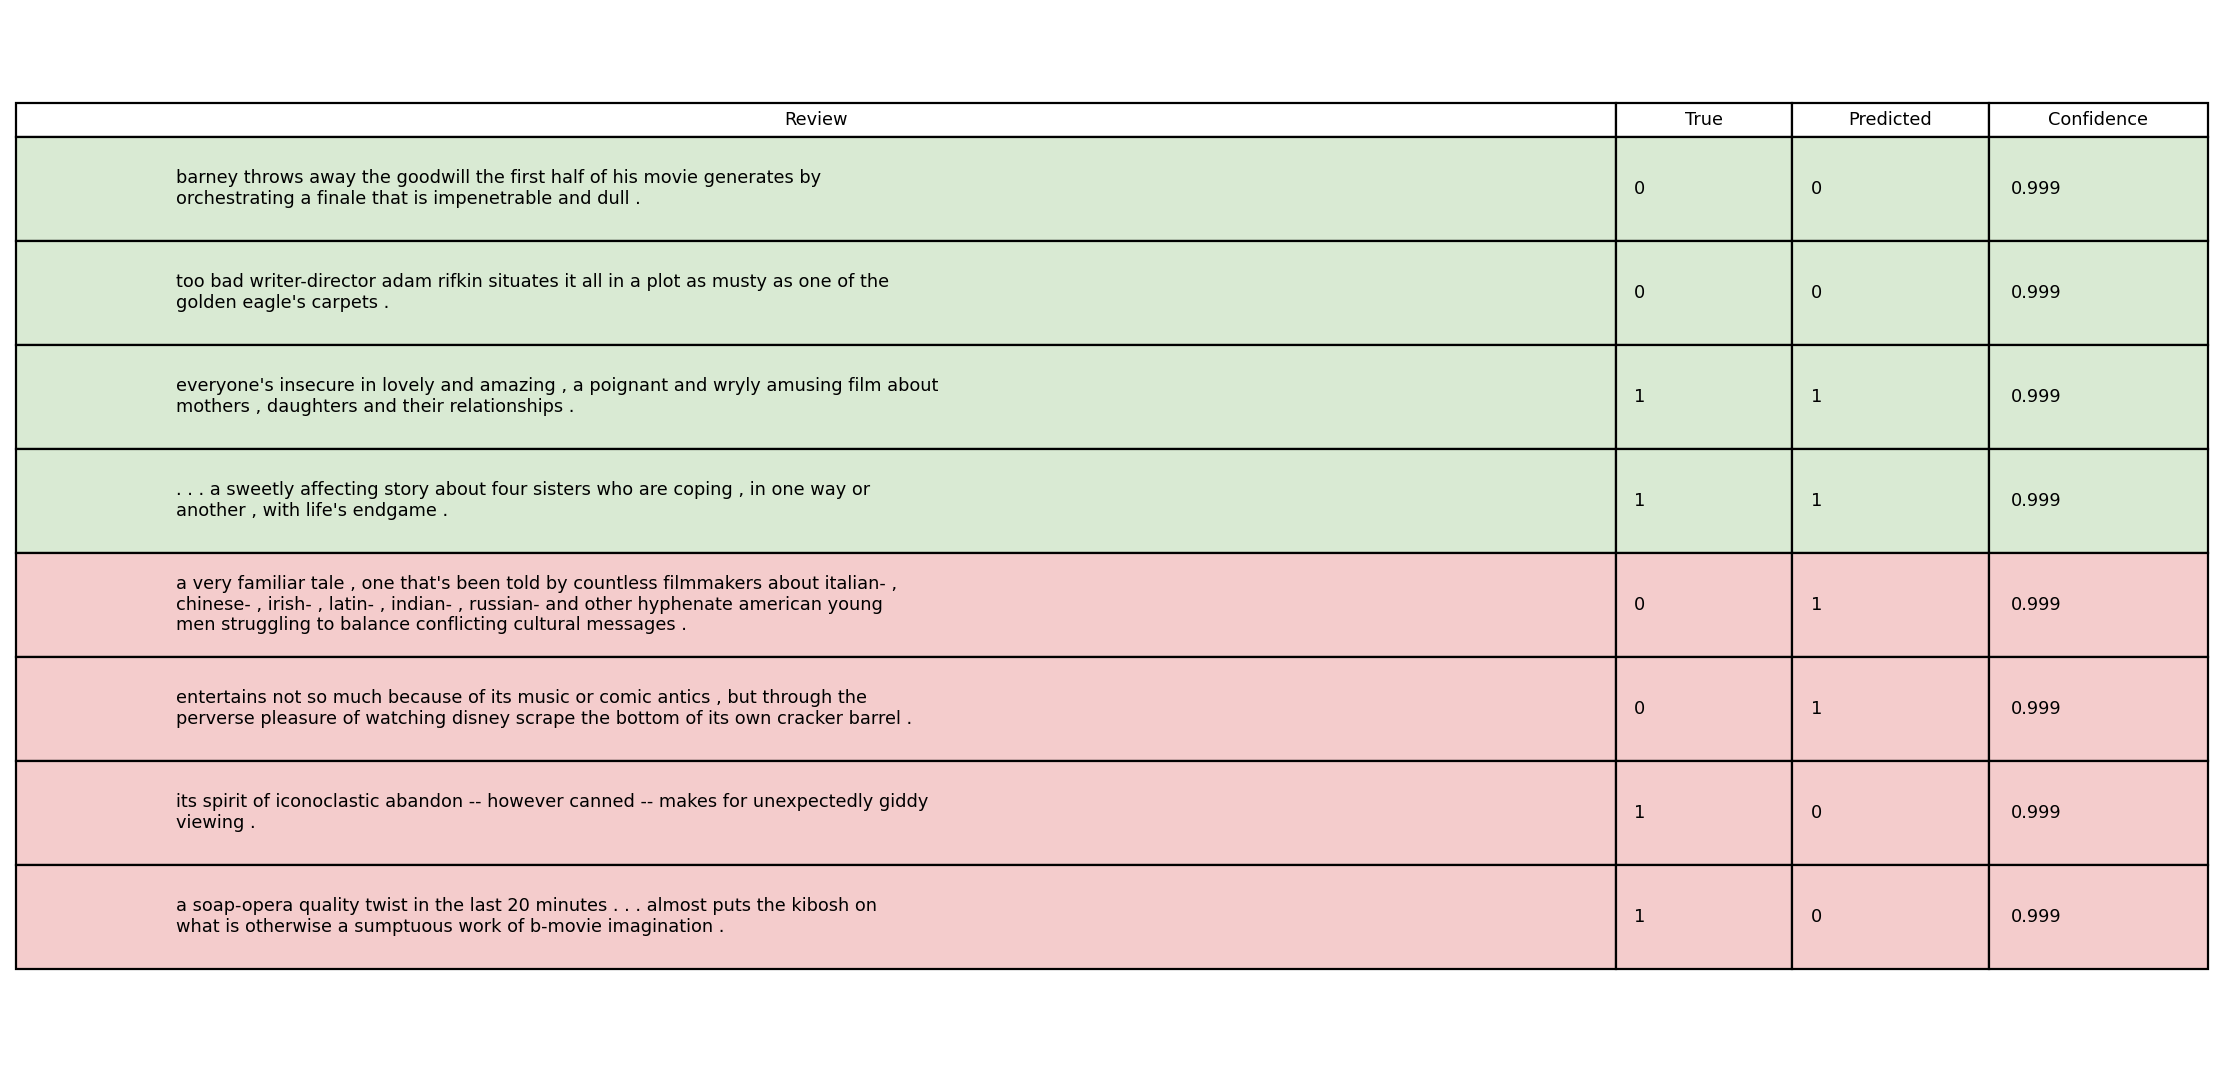

,index,text,true_label,predicted_label,confidence
0,1003,barney throws away the goodwill the first half...,0,0,0.999358
1,651,too bad writer-director adam rifkin situates i...,0,0,0.999356
2,94,"everyone's insecure in lovely and amazing , a ...",1,1,0.999256
3,510,. . . a sweetly affecting story about four sis...,1,1,0.999253
4,949,"a very familiar tale , one that's been told by...",0,1,0.999115
5,939,entertains not so much because of its music or...,0,1,0.999107
6,164,its spirit of iconoclastic abandon -- however ...,1,0,0.999331
7,216,a soap-opera quality twist in the last 20 minu...,1,0,0.999227


,index,true_label,predicted_label,positive_probability,decision_confidence,text
0,2,1,0,0.003046,0.996954,"it's like a "" big chill "" reunion of the baade..."
1,4,1,0,0.005820,0.994180,"red dragon "" never cuts corners ."
2,5,1,0,0.065366,0.934634,fresnadillo has something serious to say about...
3,7,1,0,0.002191,0.997809,weighty and ponderous but every bit as filling...
4,12,1,0,0.002901,0.997099,"mostly , [goldbacher] just lets her complicate..."
5,14,1,0,0.021410,0.978590,"at its worst , the movie is pretty diverting ;..."
6,21,1,0,0.399036,0.600964,making such a tragedy the backdrop to a love s...
7,28,1,0,0.002823,0.997177,devotees of star trek ii : the wrath of khan w...
8,36,1,0,0.003984,0.996016,"reminiscent of alfred hitchcock's thrillers , ..."
9,40,1,0,0.444685,0.555315,"you needn't be steeped in '50s sociology , pop..."


**Inference: checkpoint winner + frozen policy**

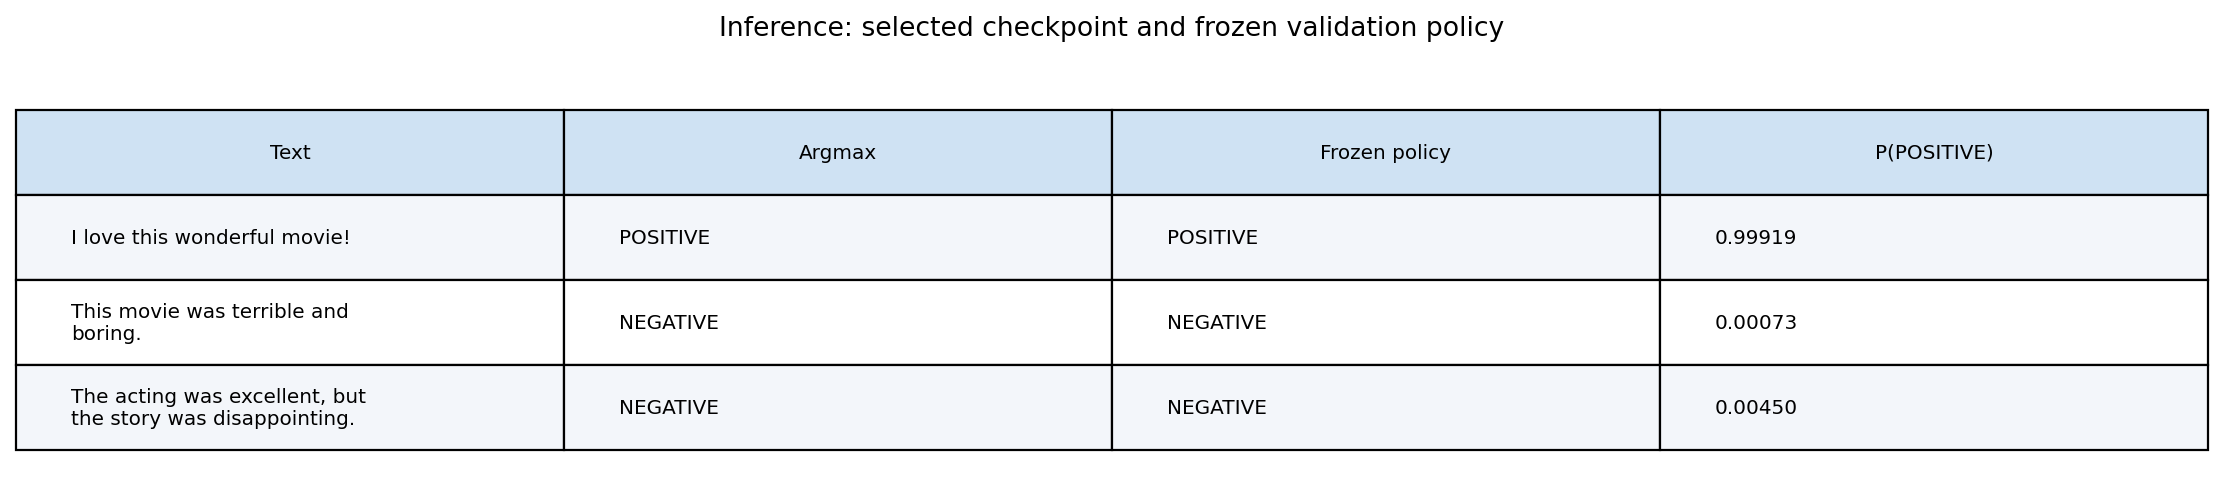

,text,score,probabilities,argmax_label,label,decision_threshold,selection_split
0,I love this wonderful movie!,0.999186,"[0.0008135565440170467, 0.9991864562034607]",POSITIVE,POSITIVE,0.5,validation
1,This movie was terrible and boring.,0.999271,"[0.9992706179618835, 0.0007293288363143802]",NEGATIVE,NEGATIVE,0.5,validation
2,"The acting was excellent, but the story was di...",0.995497,"[0.9954967498779297, 0.004503272473812103]",NEGATIVE,NEGATIVE,0.5,validation


In [31]:
show_study_image(study_run / "sample_predictions.png", "**Ví dụ đúng/sai có confidence cao**")
display(pd.DataFrame(read_json(study_run / "sample_predictions.json")))
display(pd.DataFrame(read_json(study_run / "threshold_errors.json")).head(12))
show_study_image(study_run / "inference_predictions.png", "**Inference: checkpoint winner + frozen policy**")
display(pd.DataFrame(read_json(study_run / "inference_predictions.json")))

## P11 — Artifact, nghiệm thu và giới hạn còn lại

Review ZIP giữ **đủ raw logs** và original manifests của cả ba candidate, study, Exercise 1, Kaggle audit và preflight. Cả ba candidate có exact weight verification trên Kaggle; final study tải lại winner trước test. ZIP review cố ý bỏ checkpoints, vì vậy môi trường review chỉ kiểm toán predictions/policy/hash, không thực thi lại weights.

Các hình/bảng đã nằm trong `outputs/runs/`; `outputs/published/` xuất bản sao theo `config/report.json`, primary result là study mới. Các role lịch sử vẫn giữ riêng để đối chiếu. Artifact notebook đã thực thi được lưu trong run `notebook_render`; không sửa raw science records để khớp bài viết.

**Không cần train lại để hoàn thiện báo cáo này.** Giữ checkpoint ZIP để inference/reload sau này. Nếu nghiên cứu tiếp, cần thiết kế nhiều seed hoặc calibration/đánh giá ngoài trước khi chạy; đó là công việc bổ sung, không được suy ra đã hoàn thành từ study hiện tại.

In [32]:
display({"study_run":study_run.name,"audit":study_audit["status"],
         "candidates":study_audit["candidate_count"],"epochs_each":study_audit["epochs_per_candidate"],
         "weights_loaded_locally":False,"new_training_executed":False,
         "report_primary":read_json(LAB / "config/report.json")["primary_result"]})
print("Nguồn bảng:", study_review / "tables.json")
print("Báo cáo gốc tự xuất:", study_run / "study_report.md")
print("Report artifacts:", LAB / "outputs/published/index.md")

{'study_run': '20261026T184219Z_study_94f2ba7b',
 'audit': 'passed',
 'candidates': 3,
 'epochs_each': 10,
 'weights_loaded_locally': False,
 'new_training_executed': False,
 'report_primary': 'study'}

Nguồn bảng: /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261026T191751Z_study_review_d66d4edb/tables.json
Báo cáo gốc tự xuất: /workspace/Lab-DL-completion/labs/lab03/outputs/runs/20261026T184219Z_study_94f2ba7b/study_report.md
Report artifacts: /workspace/Lab-DL-completion/labs/lab03/outputs/published/index.md
